<div style="background:linear-gradient(135deg,#0b3d63 0%,#1f6fa8 60%,#2a9d8f 100%);padding:34px 38px;border-radius:14px;color:#fff">
<div style="font-size:13px;letter-spacing:2px;opacity:.85">MACHINE LEARNING APLICADO A SISTEMAS HIDROELÉCTRICOS · MLASH_M · ENTREGA 3</div>
<div style="font-size:34px;font-weight:700;margin:10px 0 6px">Diseño de una Pequeña Central Hidroeléctrica (PCH)</div>
<div style="font-size:19px;opacity:.95">Conducción forzada, selección de turbina con <i>Gradient Boosting</i>, energía, mercado eléctrico y evaluación económica CAPEX/OPEX</div>
<div style="margin-top:18px;font-size:14px;opacity:.9">Alejandro Villamil · Valentina Álvarez &nbsp;|&nbsp; Escuela Colombiana de Ingeniería Julio Garavito &nbsp;|&nbsp; Noviembre de 2026</div>
</div>

**Objetivo:** desarrollar paso a paso el diseño preliminar de la PCH, desde los datos del río hasta la rentabilidad del proyecto: dimensionar la tubería de presión, calcular pérdidas, salto neto y potencia, seleccionar la turbina con un modelo de *Machine Learning* verificado con las ecuaciones de turbomáquinas, estimar la energía y los ingresos con precios oficiales de XM, y evaluar CAPEX, OPEX, VAN, TIR y B/C con la metodología de la clase 14.

El cuaderno se ejecuta de arriba hacia abajo (*Restart & Run All*) con Python 3.14. Todo el código está aquí mismo; solo necesita la carpeta `data/` junto al archivo.

### Contenido

| # | Sección | # | Sección |
|---|---|---|---|
| 1 | Datos del proyecto | 10 | Mercado eléctrico e ingresos (XM) |
| 2 | Librerías y configuración | 11 | CAPEX y OPEX (clase 14) |
| 3 | Parámetros editables | 12 | Evaluación económica: VAN, TIR, B/C, PB |
| 4 | Datos de entrada y control de calidad | 13 | ML hidráulico: factibilidad y pérdidas |
| 5 | Accesorios: selección por tipo y cantidad | 14 | Optimización y comparativo de tuberías |
| 6 | Modelo hidráulico y selección de la tubería | 15 | Beneficio ambiental |
| 7 | Golpe de ariete y espesor de pared | 16 | Resumen de resultados |
| 8 | **Selección de turbina con Gradient Boosting** | 17 | Conclusiones |
| 9 | Producción de energía | 18 | Referencias |

---
# 1. Datos del proyecto

- Serie diaria de caudales del río: 9.124 días (archivo `S04 Datos de Rio.xlsx`).
- Caudal de diseño: $Q = 28\ \mathrm{m^3/s}$ (alternativa seleccionada en la Entrega 2).
- Caudal ecológico mínimo: $Q_{eco} = 4\ \mathrm{m^3/s}$.
- Salto hidráulico bruto: $H_b = 80\ \mathrm{m}$.
- Longitud de la tubería de presión: $L = 1200\ \mathrm{m}$.
- Agua a 20 °C: $\rho = 998\ \mathrm{kg/m^3}$, $\nu = 1.004\times10^{-6}\ \mathrm{m^2/s}$.
- Pérdidas hidráulicas máximas: 6 % del salto bruto; velocidad en la tubería entre 0,5 y 5 m/s.
- Eficiencias: turbina según su curva de carga parcial, generador $\eta_g = 0.96$, transformador $\eta_{tr} = 0.985$.
- Factor de fricción: ecuación explícita de **Swamee–Jain**.
- Materiales y diámetros comerciales: `Base Datos Tuberias PCH.xlsx`.
- Accesorios del tramo (tipo, variante, coeficiente $K$ y fuente): `Base Datos Accesorios PCH.xlsx`.
- Turbinas: catálogos WEG, ANDRITZ y Flygt.
- Precios de energía: informes mensuales oficiales de XM.
- Tasa de cambio: TRM vigente el día del cálculo, descargada de datos.gov.co (Superintendencia Financiera).
- Costos: metodología y referencias de la clase 14 (CAPEX y OPEX).

### 1.1 Clasificación de la información

| Dato | Categoría | Justificación |
|:---|:---:|:---|
| Caudal de diseño, salto bruto y longitud | **Indispensable** | Dimensionan la tubería y fijan la potencia instalada |
| ρ, ν, g y rugosidad ε del material | **Indispensable** | Entran en Reynolds, Swamee–Jain y la potencia hidráulica |
| Pérdida máxima 6 % y velocidad 0,5–5 m/s | **Indispensable** | Son las restricciones que definen el diámetro mínimo aceptable |
| Tipo y cantidad de accesorios del tramo (base de datos de accesorios) | **Indispensable** | Determinan las pérdidas menores ΣnK·V²/2g |
| Envolventes de catálogo WEG, ANDRITZ y Flygt | **Indispensable** | Validan la turbina que propone el modelo de ML |
| Serie diaria de 9.124 caudales | **Indispensable para energía** | Define la producción anual, el factor de planta y la variabilidad hidrológica |
| Caudal ecológico 4 m³/s | **Indispensable para energía** | Restricción ambiental: se descuenta antes de turbinar |
| Precios XM de bolsa y contratos | **Indispensable para economía** | Convierten la energía en ingresos |
| CAPEX USD/kW (UPME, OLADE, ESHA) | **Útil, con incertidumbre** | Orden de magnitud de prefactibilidad |
| % de OPEX (2 %, 1 %, 0,56 %) | **Útil, con incertidumbre** | Proporciones del ejercicio de la clase 14 |
| Fecha de inicio de la serie de caudales | **Supuesto** | El archivo no la trae; solo afecta el cruce mes a mes con los precios |
| TRM del día | **Indispensable para economía** | Convierte el CAPEX en USD a pesos; se descarga en línea el día del cálculo |
| Tasa de descuento | **Supuesto editable** | Se sensibiliza en la sección 12 |

---
# 2. Librerías y configuración

Se usan solo librerías estándar del ecosistema científico de Python. `sqlite3` viene con Python y permite guardar los datos de entrada en una base de datos relacional consultable con SQL; `scikit-learn` aporta los modelos de ML; `scipy` resuelve la TIR por búsqueda de raíces.

La primera celda revisa que las librerías estén instaladas **en el mismo Python que usa el cuaderno** y, si falta alguna, la instala con `pip` (requiere internet la primera vez).

In [1]:
# ============================================================
# INSTALACIÓN AUTOMÁTICA DE LAS LIBRERÍAS QUE FALTEN
# ============================================================

import importlib, importlib.util, subprocess, sys             # Herramientas de Python para revisar e instalar paquetes.
REQUERIDAS = {"numpy": "numpy", "pandas": "pandas", "scipy": "scipy", "sklearn": "scikit-learn",  # Módulo → paquete de pip.
              "matplotlib": "matplotlib", "openpyxl": "openpyxl", "ipywidgets": "ipywidgets"}
faltan = [pq for mod, pq in REQUERIDAS.items() if importlib.util.find_spec(mod) is None]  # Paquetes que no están instalados.
print(f"Python {sys.version.split()[0]}  |  intérprete del kernel: {sys.executable}")  # Python que ejecuta el cuaderno.
if faltan:                                                    # Instala lo que falte en ESTE mismo Python (el del kernel).
    print("Instalando:", ", ".join(faltan))                   # Aviso.
    try:                                                      # pip del mismo intérprete.
        if importlib.util.find_spec("pip") is None:           # Algunos entornos virtuales se crean sin pip...
            subprocess.check_call([sys.executable, "-m", "ensurepip", "--upgrade"])  # ...y se le instala primero.
        subprocess.check_call([sys.executable, "-m", "pip", "install", *faltan])  # Instalación.
        importlib.invalidate_caches()                         # Python reconoce los paquetes recién instalados.
        print("Listo. Si la celda siguiente aún falla, use Kernel → Restart y vuelva a ejecutar todo.")  # Indicación.
    except Exception as err:                                  # Sin pip o sin internet.
        print(f"No se pudo instalar automáticamente ({err}). En una terminal ejecute:\n"
              f"  \"{sys.executable}\" -m pip install {' '.join(faltan)}")  # Comando manual.
else:                                                         # Todo instalado.
    print("Todas las librerías necesarias están instaladas.") # Confirmación.

Python 3.14.10  |  intérprete del kernel: /opt/hostedtoolcache/Python/3.14.10/x64/bin/python
Todas las librerías necesarias están instaladas.


In [2]:
# ============================================================
# LIBRERÍAS
# ============================================================

import warnings                                               # Permite silenciar avisos no críticos de las librerías.
import time                                                   # Mide tiempos de cómputo (ML vs física).
import sqlite3                                                # Motor de base de datos relacional incluido en Python.
import json                                                   # Lectura de las respuestas JSON de la API de la TRM.
import urllib.parse, urllib.request                           # Consulta de la TRM en internet sin librerías adicionales.
from datetime import date                                     # Fecha del día del cálculo.
from pathlib import Path                                      # Manejo de rutas independiente del sistema operativo.

import numpy as np                                            # Cálculo numérico vectorizado.
import pandas as pd                                           # Tablas de datos (DataFrames) y lectura de Excel/CSV.
import matplotlib.pyplot as plt                               # Gráficas de ingeniería.
from matplotlib.path import Path as MplPath                   # Prueba punto-en-polígono para las envolventes de catálogo.
from matplotlib.ticker import NullFormatter, FuncFormatter    # Formato de ejes logarítmicos y de miles.
from scipy.optimize import brentq                             # Raíz de una función: se usa para la TIR.
from IPython.display import display, Markdown                 # Muestra tablas y texto con formato dentro del cuaderno.

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, GroupShuffleSplit  # Particiones y búsqueda de hiperparámetros.
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor, RandomForestClassifier  # Modelos de ensambles de árboles.
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor  # Gradient Boosting por histogramas (rápido en datasets grandes).
from sklearn.linear_model import LogisticRegression, LinearRegression  # Modelos lineales de referencia.
from sklearn.dummy import DummyClassifier, DummyRegressor     # Modelos base "ingenuos" contra los que se compara.
from sklearn.pipeline import make_pipeline                    # Encadena escalado + modelo.
from sklearn.preprocessing import StandardScaler              # Escala variables para modelos lineales.
from sklearn.inspection import permutation_importance         # Importancia de variables independiente del modelo.
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,  # Métricas de clasificación.
                             confusion_matrix, classification_report, r2_score)  # Matriz de confusión y R².

warnings.filterwarnings("ignore")                             # Mantiene limpia la salida del cuaderno.
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")  # Tres decimales y separador de miles en las tablas.
pd.set_option("display.max_colwidth", 120)                    # Deja leer los textos largos de las tablas.
pd.set_option("display.width", 200)                           # Ancho de impresión de tablas.

In [3]:
# ============================================================
# ESTILO GRÁFICO Y RUTAS
# ============================================================

PALETA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # Colores categóricos con contraste validado.
TINTA, GRIS = "#1f2937", "#9aa3ad"                            # Color de texto y color de referencias secundarias.
plt.rcParams.update({                                         # Estilo común para todas las figuras.
    "figure.dpi": 110, "savefig.dpi": 150, "figure.figsize": (9, 4.6),  # Resolución y tamaño por defecto.
    "axes.spines.top": False, "axes.spines.right": False,     # Ejes limpios: sin marco superior ni derecho.
    "axes.grid": True, "grid.color": "#e5e7eb", "grid.linewidth": 0.8,  # Rejilla suave para leer valores.
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.labelsize": 10.5,  # Jerarquía tipográfica.
    "axes.prop_cycle": plt.cycler(color=PALETA), "legend.frameon": False,  # Paleta del proyecto y leyendas sin marco.
    "text.color": TINTA, "axes.labelcolor": TINTA, "xtick.color": TINTA, "ytick.color": TINTA,  # Texto oscuro legible.
})
miles = FuncFormatter(lambda v, _: f"{v:,.0f}")               # Formateador de ejes con separador de miles.

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())  # Busca la carpeta del proyecto que contiene "data".
DATOS = RAIZ / "data"                                         # Carpeta con los archivos de entrada.
SALIDAS = RAIZ / "resultados"                                 # Carpeta donde el cuaderno guarda tablas, gráficas y resultados.
SALIDAS.mkdir(exist_ok=True)                                  # La crea si no existe.
print("Carpeta de datos:", DATOS)                             # Confirma de dónde se leen los datos.

Carpeta de datos: /home/runner/work/pch-proyecto-integrado/pch-proyecto-integrado/data


---
# 3. Parámetros editables

Todos los supuestos del proyecto están en **una sola celda**. Cambie un valor y ejecute *Kernel → Restart & Run All*: el cuaderno completo se recalcula con el nuevo dato. Cada parámetro indica su unidad y de dónde sale.

In [4]:
# ============================================================
# PARÁMETROS EDITABLES
# ============================================================

archivo_caudales = DATOS / "S04 Datos de Rio.xlsx"            # Serie diaria de caudales del río (9.124 días, Entrega 1).
archivo_tuberias = DATOS / "Base Datos Tuberias PCH.xlsx"     # Base de datos de materiales y diámetros comerciales.
archivo_accesorios = DATOS / "Base Datos Accesorios PCH.xlsx" # Base de datos de accesorios con su coeficiente K.
archivo_precios = DATOS / "precios_xm_mensual.csv"            # Precios mensuales oficiales de XM con URL de cada informe.
archivo_dataset_ml = DATOS / "dataset_hidraulico_v0.1.0.csv"  # Dataset hidráulico de 8.400 casos (Entrega 2).

# --- Sitio e hidráulica
Q_diseno = 28.0                                               # Caudal de diseño (m³/s), alternativa seleccionada en la Entrega 2.
Q_eco = 4.0                                                   # Caudal ecológico que siempre queda en el río (m³/s).
H_bruto = 80.0                                                # Salto bruto entre la bocatoma y la casa de máquinas (m).
L = 1200.0                                                    # Longitud de la tubería de presión (m).
rho = 998.0                                                   # Densidad del agua a 20 °C (kg/m³).
nu = 1.004e-6                                                 # Viscosidad cinemática del agua a 20 °C (m²/s).
g = 9.81                                                      # Aceleración de la gravedad (m/s²).
cota_casa_maquinas = 1000.0                                   # Altitud de la casa de máquinas (m s. n. m.), para la presión atmosférica.

# --- Criterios de diseño de la conducción
material_id = "PE100_AGRU"                                    # Material de la tubería (opciones: GRP_FLOWTITE, PE100_AGRU, DI_PAM, PVC).
D_tuberia = None                                              # Diámetro interno elegido (m): None = el menor que cumple; o un valor del catálogo, p. ej. 3.0.
seleccion_tuberia_por_consola = False                         # True: la sección 6 lista las tuberías que cumplen y pregunta cuál usar.
V_max, V_min = 5.0, 0.5                                       # Velocidad máxima (erosión, golpe de ariete) y mínima (sedimentación), m/s (ESHA 2004).
perdida_max = 0.06                                            # Pérdida hidráulica máxima admisible como fracción del salto bruto (criterio de la Entrega 2).
T_cierre = 10.0                                               # Tiempo de cierre de la válvula de guarda (s), para el golpe de ariete.

# --- Accesorios del tramo: tipo (ID de la base de datos de accesorios) y cantidad
accesorios_tramo = {                                          # La lista completa de tipos con su ID y su K está en la sección 5.
    "ENT_ABOCINADA": 1,                                       # Entrada abocinada desde la cámara de carga.
    "REJ_RECTANGULAR": 1,                                     # Rejilla fina de barras rectangulares (Kirschmer).
    "CODO_45_RD3": 4,                                         # Codos de 45° con r/D = 3 en los cambios de pendiente.
    "VAL_MARIPOSA": 2,                                        # Válvula de guarda + válvula de admisión (use VAL_ESFERICA si H > 200 m).
    "JUNTA_DILATACION": 2,                                    # Juntas de dilatación telescópicas.
    "RED_CONICA": 1,                                          # Reducción cónica a la entrada de la espiral.
}
seleccion_por_consola = False                                 # True: la sección 5 pregunta con input() el tipo y la cantidad de cada accesorio.

# --- Equipos y red
eta_t = 0.92                                                  # Eficiencia de referencia de la turbina en el punto de diseño (se refina con la curva en la sección 8).
eta_g = 0.96                                                  # Eficiencia del generador.
eta_tr = 0.985                                                # Eficiencia del transformador elevador.
perdidas_linea = 0.01                                         # Pérdidas de la línea hasta la frontera comercial (fracción).
autoconsumo = 0.005                                           # Servicios auxiliares de la central (fracción).
disponibilidad = 0.95                                         # Disponibilidad anual por mantenimientos y fallas (fracción).
n_unidades_max = 3                                            # Número máximo de unidades que se evalúan para la turbina.

# --- Mercado y economía (pesos constantes, metodología de la clase 14)
anio_base = 2026                                              # Año base de los pesos constantes.
TRM_en_linea = True                                           # True: descarga la TRM vigente el día del cálculo (sección 4.6).
TRM_respaldo = 3269.88                                        # TRM (COP/USD) que se usa si no hay internet: la vigente el 10-nov-2026.
frac_contrato = 0.70                                          # Fracción de la energía vendida en contrato bilateral en el escenario base.
i_desc = 0.10                                                 # Tasa de descuento real del inversionista (10 % anual).
vida_util = 30                                                # Horizonte de evaluación (años de operación).
c_ref_usd_kw = 3009.0                                         # CAPEX de referencia UPME para hidro menor (USD/kW), Plan de Expansión 2025-2039.
f_cop, f_mant, f_adm = 0.02, 0.01, 0.0056                     # OPEX como fracción del CAPEX: operación, mantenimiento y administración (clase 14).
ley99 = 0.06                                                  # Transferencias del sector eléctrico, Ley 99 de 1993 art. 45 (plantas > 10 MW).
tasa_renta = 0.35                                             # Impuesto de renta (Estatuto Tributario art. 240), solo en la variante después de impuestos.

semilla = 42                                                  # Semilla aleatoria: garantiza resultados reproducibles en los modelos de ML.
reconstruir_base_datos = False                                # True: vuelve a crear la base SQL desde los archivos de data/ (sección 4.1).
busqueda_hiperparametros = True                               # False: usa los hiperparámetros ya encontrados (ejecución rápida del dashboard).

---
# 4. Datos de entrada y control de calidad

> **Por qué primero los datos.** Un modelo, físico o de ML, no puede ser mejor que sus datos. Antes de calcular se verifica que cada variable esté dentro de un **rango físicamente admisible** y se marcan los **atípicos estadísticos**. Son dos cosas distintas: un caudal negativo es imposible y se rechaza; una creciente de 300 m³/s es rara pero real y se conserva, porque eliminarla sesgaría la energía y el riesgo.

### 4.1 Base de datos SQL del proyecto

Todos los datos de entrada viven en una **base de datos relacional SQLite** (`base_datos/pch_proyecto.sqlite`), y el cuaderno los lee con consultas SQL. La base se crea a partir de los archivos fuente de la carpeta `data/` (Excel y CSV) y se guarda también como `pch_proyecto.sql`, un script en SQL estándar con el esquema y los datos que se puede cargar en cualquier motor (SQLite, PostgreSQL, MySQL) o revisar en GitHub.

| Tabla | Contenido |
|---|---|
| `caudales_rio` | caudal medio diario del río, 9.124 días |
| `tuberias_materiales`, `tuberias_diametros`, `tuberias_rangos`, `tuberias_fuentes` | materiales, diámetros comerciales, rangos de fabricación y catálogos |
| `accesorios`, `accesorios_fuentes` | tipos de accesorio con su coeficiente $K$ y sus referencias |
| `precios_xm` | precios mensuales de bolsa y contratos de XM |
| `dataset_hidraulico` | 8.400 casos hidráulicos de la Entrega 2 |
| `metadatos` | diccionario de datos: descripción, archivo fuente y filas de cada tabla |
| `v_catalogo_tuberias` (vista) | cada diámetro con la rugosidad de su material |

In [5]:
# ============================================================
# BASE DE DATOS SQL DEL PROYECTO (SE CREA A PARTIR DE LOS ARCHIVOS FUENTE)
# ============================================================

def crear_base_datos(carpeta_datos, ruta_db):                 # Crea la base SQLite con todos los datos de entrada del proyecto.
    carpeta_datos, ruta_db = Path(carpeta_datos), Path(ruta_db)  # Rutas como objetos Path.
    ruta_db.parent.mkdir(parents=True, exist_ok=True)         # Crea la carpeta de la base si no existe.
    tub = carpeta_datos / "Base Datos Tuberias PCH.xlsx"      # Excel de tuberías (Entrega 1).
    acc = carpeta_datos / "Base Datos Accesorios PCH.xlsx"    # Excel de accesorios con su K.
    rio_xl = pd.read_excel(carpeta_datos / "S04 Datos de Rio.xlsx", sheet_name="Rio")  # Serie diaria de caudales.
    tablas = {                                                # Nombre de la tabla: (datos, descripción, archivo fuente).
        "caudales_rio": (rio_xl.set_axis(["dia", "Q_rio_m3s"], axis=1),
                         "Caudal medio diario del río (m³/s)", "S04 Datos de Rio.xlsx"),
        "tuberias_materiales": (pd.read_excel(tub, sheet_name="Materiales"),
                                "Materiales de tubería: rugosidad de diseño, uso y fuente", tub.name),
        "tuberias_diametros": (pd.read_excel(tub, sheet_name="Diametros_comerciales"),
                               "Diámetros comerciales por material y fabricante", tub.name),
        "tuberias_rangos": (pd.read_excel(tub, sheet_name="Rangos_materiales"),
                            "Rango de diámetros de fabricación de cada material", tub.name),
        "tuberias_fuentes": (pd.read_excel(tub, sheet_name="Fuentes"), "Catálogos de respaldo de las tuberías", tub.name),
        "accesorios": (pd.read_excel(acc, sheet_name="Accesorios"),
                       "Tipos de accesorio con su método de cálculo de K y su fuente", acc.name),
        "accesorios_fuentes": (pd.read_excel(acc, sheet_name="Fuentes"), "Referencias de los coeficientes K", acc.name),
        "precios_xm": (pd.read_csv(carpeta_datos / "precios_xm_mensual.csv"),
                       "Precios mensuales de bolsa y contratos publicados por XM (COP/kWh corrientes)", "precios_xm_mensual.csv"),
        "dataset_hidraulico": (pd.read_csv(carpeta_datos / "dataset_hidraulico_v0.1.0.csv"),
                               "Dataset hidráulico de 8.400 casos de la Entrega 2", "dataset_hidraulico_v0.1.0.csv"),
    }
    if ruta_db.exists():                                      # Se reconstruye desde cero para no mezclar versiones.
        ruta_db.unlink()                                      # Borra la base anterior.
    with sqlite3.connect(ruta_db) as con:                     # Crea la base.
        for nombre, (df, _, _) in tablas.items():             # Una tabla por archivo u hoja.
            df.to_sql(nombre, con, index=False)               # Escribe la tabla.
        pd.DataFrame([(n, d, f, len(df)) for n, (df, d, f) in tablas.items()],  # Diccionario de datos.
                     columns=["tabla", "descripcion", "archivo_fuente", "filas"]).assign(creada=str(date.today())).to_sql(
            "metadatos", con, index=False)                    # Tabla de metadatos.
        con.execute("CREATE VIEW v_catalogo_tuberias AS SELECT d.*, m.epsilon_diseno_mm FROM tuberias_diametros d "
                    "LEFT JOIN tuberias_materiales m USING (Material_ID)")  # Vista: diámetro + rugosidad del material.
        con.execute("CREATE INDEX ix_diametros_material ON tuberias_diametros (Material_ID)")  # Índice para filtrar por material.
    with sqlite3.connect(ruta_db) as con, open(ruta_db.with_suffix(".sql"), "w", encoding="utf-8") as f:  # Respaldo portable.
        for linea in con.iterdump():                          # Esquema y datos en SQL estándar.
            f.write(linea + "\n")                             # Una sentencia por línea.
    return ruta_db                                            # Ruta de la base creada.

ruta_db = RAIZ / "base_datos" / "pch_proyecto.sqlite"         # Base de datos SQL del proyecto.
if reconstruir_base_datos or not ruta_db.exists():            # Se crea si no existe o si se pide reconstruirla.
    crear_base_datos(DATOS, ruta_db)                          # Excel/CSV → SQLite + script .sql.

def consulta(sql, params=None):                               # Ejecuta una consulta SQL y devuelve una tabla.
    with sqlite3.connect(ruta_db) as con:                     # Abre la base y la cierra al terminar.
        return pd.read_sql(sql, con, params=params)           # Resultado como DataFrame.

print(f"Base de datos: {ruta_db.name}  |  respaldo SQL: {ruta_db.with_suffix('.sql').name}")  # Archivos.
consulta("SELECT tabla, filas, descripcion, archivo_fuente FROM metadatos")  # Diccionario de datos.

Base de datos: pch_proyecto.sqlite  |  respaldo SQL: pch_proyecto.sql


,tabla,filas,descripcion,archivo_fuente
0,caudales_rio,9124,Caudal medio diario del río (m³/s),S04 Datos de Rio.xlsx
1,tuberias_materiales,6,"Materiales de tubería: rugosidad de diseño, uso y fuente",Base Datos Tuberias PCH.xlsx
2,tuberias_diametros,131,Diámetros comerciales por material y fabricante,Base Datos Tuberias PCH.xlsx
3,tuberias_rangos,6,Rango de diámetros de fabricación de cada material,Base Datos Tuberias PCH.xlsx
4,tuberias_fuentes,5,Catálogos de respaldo de las tuberías,Base Datos Tuberias PCH.xlsx
5,accesorios,51,Tipos de accesorio con su método de cálculo de K y su fuente,Base Datos Accesorios PCH.xlsx
6,accesorios_fuentes,3,Referencias de los coeficientes K,Base Datos Accesorios PCH.xlsx
7,precios_xm,166,Precios mensuales de bolsa y contratos publicados por XM (COP/kWh corrientes),precios_xm_mensual.csv
8,dataset_hidraulico,8400,Dataset hidráulico de 8.400 casos de la Entrega 2,dataset_hidraulico_v0.1.0.csv


### 4.2 Serie de caudales del río

Los caudales se comportan aproximadamente como una variable **log-normal** (asimétrica, con colas largas de crecientes). Por eso el criterio de atípico de Tukey se aplica sobre $\ln Q$:

$$ \text{atípico si } \ln Q < Q_1 - k\,\mathrm{IQR} \quad\text{o}\quad \ln Q > Q_3 + k\,\mathrm{IQR}, \qquad k = 3 $$

Además se buscan **saltos bruscos** ($|\ln Q_t - \ln Q_{t-1}| > 1{,}5$, es decir, el caudal se multiplica o divide por más de 4,5 en un día) y **rachas planas** (30 días o más con el mismo valor, típico de relleno de datos o sensor bloqueado).

In [6]:
# ============================================================
# LECTURA DE LA SERIE DE CAUDALES
# ============================================================

rio = consulta("SELECT dia, Q_rio_m3s FROM caudales_rio ORDER BY dia")  # Serie diaria desde la base SQL.
rio["Q_rio_m3s"] = pd.to_numeric(rio["Q_rio_m3s"], errors="coerce")  # Convierte a número; un texto inválido queda como NaN.
rio["fecha"] = pd.date_range("2000-01-01", periods=len(rio), freq="D")  # SUPUESTO: el archivo no trae fechas; se asigna un calendario.
print(f"Registros: {len(rio):,} días ≈ {len(rio)/365:.1f} años")  # Tamaño de la serie.
rio.describe().T                                              # Estadística descriptiva del caudal.

Registros: 9,124 días ≈ 25.0 años


,count,mean,min,25%,50%,75%,max,std
dia,"9,124.000","4,562.500",1.000,"2,281.750","4,562.500","6,843.250","9,124.000","2,634.016"
Q_rio_m3s,"9,124.000",46.651,19.400,31.800,35.500,57.900,108.000,22.273
fecha,9124,2012-06-27 12:00:00,2000-01-01 00:00:00,2006-03-30 18:00:00,2012-06-27 12:00:00,2018-09-25 06:00:00,2024-12-23 00:00:00,NaN


In [7]:
# ============================================================
# CONTROL DE CALIDAD DE LOS CAUDALES
# ============================================================

q = rio["Q_rio_m3s"]                                          # Serie de caudales (m³/s).
fuera_rango = q.isna() | (q < 0) | (q > 2000)                 # Rango admisible: 0 ≤ Q ≤ 2.000 m³/s (cuenca de PCH).
lnq = np.log(q.clip(lower=1e-6))                              # Logaritmo natural del caudal (se evita ln(0)).
q1, q3 = np.percentile(lnq[~fuera_rango], [25, 75])           # Primer y tercer cuartil en escala log.
iqr = q3 - q1                                                 # Rango intercuartílico.
atipico = ((lnq < q1 - 3 * iqr) | (lnq > q3 + 3 * iqr)) & ~fuera_rango  # Criterio de Tukey "extremo" (k = 3).
salto = lnq.diff().abs() > 1.5                                # Cambio de más de 4,5 veces en un día.
racha = q.groupby((q != q.shift()).cumsum()).transform("size") >= 30  # Treinta días o más con el mismo valor.

qc_caudales = pd.DataFrame({                                  # Tabla resumen del control de calidad.
    "Prueba": ["Nulos o fuera de rango (se rechazan)", "Atípicos log-IQR k=3 (se marcan)",
               "Saltos bruscos > 4,5× (se marcan)", "Rachas planas ≥ 30 días (se marcan)"],
    "Registros": [int(fuera_rango.sum()), int(atipico.sum()), int(salto.sum()), int(racha.sum())],
})
qc_caudales["% de la serie"] = qc_caudales["Registros"] / len(q) * 100  # Proporción afectada.
rio = rio[~fuera_rango].reset_index(drop=True)                # Solo se eliminan los datos físicamente imposibles.
display(qc_caudales)                                          # Muestra el resultado del control.

,Prueba,Registros,% de la serie
0,Nulos o fuera de rango (se rechazan),0,0.000
1,Atípicos log-IQR k=3 (se marcan),0,0.000
2,"Saltos bruscos > 4,5× (se marcan)",0,0.000
3,Rachas planas ≥ 30 días (se marcan),162,1.776


### 4.3 Curva de duración de caudales

La curva de duración ordena los caudales de mayor a menor y asigna a cada uno la probabilidad de ser igualado o excedido (fórmula de Weibull):

$$ P(Q \ge Q_i) = \frac{i}{N + 1}\cdot 100\,\% $$

Es la herramienta clásica para escoger el caudal de diseño de una PCH: un $Q_d$ alto aprovecha las crecientes pero deja la turbina trabajando a carga parcial buena parte del año; un $Q_d$ bajo hace lo contrario. El valor de 28 m³/s se optimiza económicamente en la sección 14.

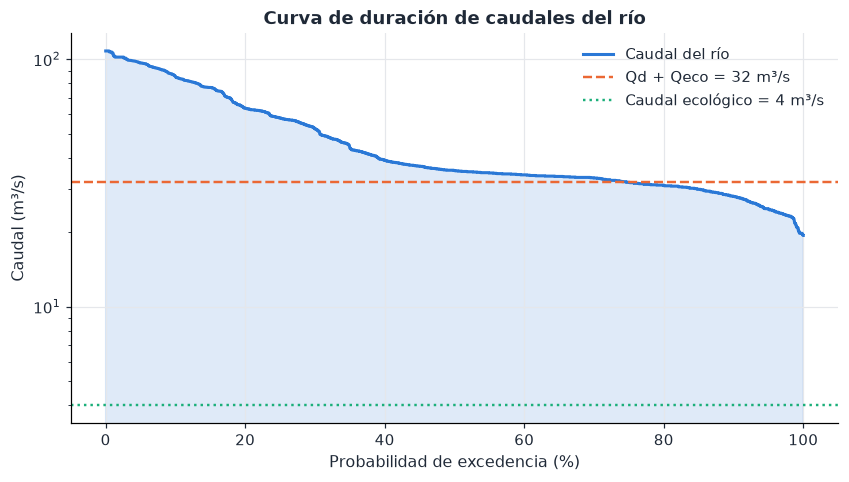

El río supera Qd + Qeco el 74.0 % del tiempo.


,Q5,Q30,Q50,Q80,Q95
Q (m³/s),96.500,52.400,35.500,30.900,24.800


In [8]:
# ============================================================
# CURVA DE DURACIÓN
# ============================================================

Q_ord = np.sort(rio["Q_rio_m3s"].values)[::-1]                # Caudales ordenados de mayor a menor.
excedencia = np.arange(1, len(Q_ord) + 1) / (len(Q_ord) + 1) * 100  # Probabilidad de excedencia de Weibull (%).
exc_Qd = np.interp(Q_diseno + Q_eco, Q_ord[::-1], excedencia[::-1])  # % del tiempo en que el río supera Qd + Qeco.
Q_tabla = {p: np.percentile(rio["Q_rio_m3s"], 100 - p) for p in (5, 30, 50, 80, 95)}  # Caudales característicos Q5 ... Q95.

fig, ax = plt.subplots()                                      # Figura de la curva de duración.
ax.fill_between(excedencia, Q_ord, color=PALETA[0], alpha=0.15)  # Área bajo la curva: volumen disponible.
ax.plot(excedencia, Q_ord, color=PALETA[0], lw=2, label="Caudal del río")  # Curva de duración.
ax.axhline(Q_diseno + Q_eco, color=PALETA[1], ls="--", lw=1.6, label=f"Qd + Qeco = {Q_diseno + Q_eco:.0f} m³/s")  # Caudal que satura la central.
ax.axhline(Q_eco, color=PALETA[2], ls=":", lw=1.6, label=f"Caudal ecológico = {Q_eco:.0f} m³/s")  # Caudal que se respeta.
ax.set_yscale("log")                                          # Escala log: muestra igual de bien estiaje y crecientes.
ax.set(xlabel="Probabilidad de excedencia (%)", ylabel="Caudal (m³/s)", title="Curva de duración de caudales del río")  # Rótulos.
ax.legend()                                                   # Leyenda.
plt.show()                                                    # Dibuja la figura.
print(f"El río supera Qd + Qeco el {exc_Qd:.1f} % del tiempo.")  # Interpretación del caudal de diseño.
pd.Series(Q_tabla, name="Q (m³/s)").rename(lambda p: f"Q{p}").to_frame().T  # Caudales característicos.

### 4.4 Catálogo de tuberías

La base de datos de tuberías (Entrega 1, tablas `tuberias_materiales` y `tuberias_diametros`) trae, por material, la rugosidad absoluta de diseño $\varepsilon$ y los diámetros comerciales con su fuente de catálogo (Amiblu Flowtite, AGRU, PAM, American). Se unen ambas tablas para tener, en cada diámetro, la rugosidad que le corresponde.

In [9]:
# ============================================================
# CATÁLOGO DE MATERIALES Y DIÁMETROS COMERCIALES
# ============================================================

materiales = consulta("SELECT * FROM tuberias_materiales")    # Tabla de materiales (rugosidad, fuente).
diametros = consulta("SELECT * FROM tuberias_diametros")      # Tabla de diámetros comerciales.
catalogo = diametros.merge(materiales[["Material_ID", "epsilon_diseno_mm"]], on="Material_ID", how="left")  # Une rugosidad a cada diámetro.
eps_di = materiales.loc[materiales["Material_ID"].str.startswith("DI"), "epsilon_diseno_mm"].dropna()  # Rugosidad publicada para fundición dúctil.
catalogo.loc[catalogo["Material_ID"].str.startswith("DI"), "epsilon_diseno_mm"] = catalogo["epsilon_diseno_mm"].fillna(eps_di.iloc[0])  # DI_PAM usa la del hierro dúctil.
catalogo = catalogo[catalogo["Disponible_catalogo"].fillna(True).astype(bool)]  # Solo diámetros disponibles.
catalogo = catalogo.dropna(subset=["Diametro_hidraulico_m", "epsilon_diseno_mm"]).reset_index(drop=True)  # Descarta filas incompletas.
resumen_mat = catalogo.groupby(["Material_ID", "Material"]).agg(  # Resumen por material.
    epsilon_mm=("epsilon_diseno_mm", "first"), D_min_m=("Diametro_hidraulico_m", "min"),
    D_max_m=("Diametro_hidraulico_m", "max"), diametros=("Diametro_hidraulico_m", "count")).reset_index()
resumen_mat                                                   # Muestra la tabla.

,Material_ID,Material,epsilon_mm,D_min_m,D_max_m,diametros
0,DI_PAM,Hierro dúctil NATURAL,0.045,0.060,2.000,24
1,GRP_FLOWTITE,PRFV / GRP Flowtite,0.029,0.200,4.000,41
2,PE100_AGRU,PE 100-RC AGRU,0.007,0.020,3.500,41
3,PVC,PVC-O TOM,0.002,0.090,1.200,23


### 4.5 Precios oficiales del mercado (XM)

El archivo `precios_xm_mensual.csv` se construyó a partir de los **informes mensuales de variables del mercado publicados por XM** (cada fila guarda la URL del informe y la fecha de consulta). Contiene el precio de bolsa nacional (36 meses) y los precios promedio de contratos (SICEP, regulados y no regulados).

Los precios vienen en **pesos corrientes**. Para sumarlos con costos de distintos años se llevan a **pesos constantes de 2026** con el IPC del DANE:

$$ P_{\text{const}} = P_{\text{corr}}\cdot\frac{\text{IPC}_{2026}}{\text{IPC}_{t}} $$

In [10]:
# ============================================================
# PRECIOS XM: LECTURA, CONTROL DE CALIDAD Y DEFLACTACIÓN
# ============================================================

px = consulta("SELECT * FROM precios_xm")                     # Precios de los informes XM desde la base SQL.
px["fecha"] = pd.to_datetime(px["periodo_mes"] + "-01")       # Fecha del primer día de cada mes.
px = px[(px["valor"] >= 0) & (px["valor"] <= 5000)]           # Rango admisible 0-5.000 COP/kWh (≈4× el máximo histórico).
IPC_DANE = {2023: 9.28, 2024: 5.20, 2025: 5.10, 2026: 6.29}   # Variación anual del IPC (%), DANE (2026: dato a septiembre).

def nivel_ipc(t):                                             # Nivel relativo del IPC a mitad de cada mes.
    nivel = 1.0                                               # Índice arbitrario = 1 al inicio de 2023.
    for a in range(2023, t.year):                             # Acumula la inflación de los años completos anteriores.
        nivel *= 1 + IPC_DANE.get(a, 0) / 100                 # Factor de cada año.
    return nivel * (1 + IPC_DANE.get(t.year, 0) / 100) ** ((t.month - 0.5) / 12)  # Interpolación geométrica dentro del año.

ipc_base = np.mean([nivel_ipc(pd.Timestamp(anio_base, m, 1)) for m in range(1, 13)])  # IPC promedio del año base.
px["valor_const"] = px["valor"] * ipc_base / px["fecha"].map(nivel_ipc)  # Pesos constantes del año base.
serie = {v: g.set_index("fecha")["valor_const"].sort_index() for v, g in px.groupby("variable")}  # Una serie por variable.
bolsa = serie["bolsa"]                                        # Precio de bolsa mensual (COP/kWh constantes).
z_mad = (bolsa - bolsa.median()).abs() / (1.4826 * (bolsa - bolsa.median()).abs().median())  # Z robusto con la mediana (MAD).
print(f"Bolsa: {len(bolsa)} meses ({bolsa.index.min():%Y-%m} a {bolsa.index.max():%Y-%m}); "
      f"atípicos |z_MAD| > 3.5: {(z_mad > 3.5).sum()} (se conservan: son riesgo real de El Niño)")  # Resultado del QC.
px.groupby("variable")["valor_const"].describe()[["count", "mean", "min", "max"]]  # Estadística por variable.

Bolsa: 36 meses (2023-09 a 2026-08); atípicos |z_MAD| > 3.5: 0 (se conservan: son riesgo real de El Niño)


,count,mean,min,max
variable,,,,
SICEP,22.000,331.885,309.567,360.437
bolsa,36.000,551.407,119.551,"1,709.084"
contrato_no_regulado,22.000,315.742,291.118,344.982
contrato_regulado,22.000,336.425,313.618,352.857
escasez_PE,14.000,727.657,594.893,908.546
escasez_PEI,14.000,342.116,321.967,369.302
escasez_PES,14.000,997.470,840.976,"1,307.420"
indice_MC,22.000,332.506,311.737,349.449


### 4.6 Tasa de cambio del día (TRM)

La TRM la calcula y certifica cada día hábil la **Superintendencia Financiera** y el Banco de la República la publica en su portal SUAMECA. Ese portal es una aplicación web sin una API pública documentada, así que el cuaderno toma el mismo valor oficial del conjunto de **datos abiertos del Gobierno** *Tasa de Cambio Representativa del Mercado – Histórico* (`datos.gov.co`, recurso `32sa-8pi3`), que se consulta en línea:

$$TRM_{hoy} = \text{valor con } \text{vigencia desde} \le \text{fecha del cálculo} \le \text{vigencia hasta}$$

Los fines de semana y festivos rige la TRM del último día hábil, que es la que devuelve la consulta. Sin internet, o con `TRM_en_linea = False`, se usa `TRM_respaldo` de la celda de parámetros y el cuaderno lo avisa. Todo el CAPEX en dólares se convierte a pesos con este valor:

$$C_{COP}=C_{USD}\cdot TRM$$

In [11]:
# ============================================================
# TRM DEL DÍA DESDE LA API DE DATOS ABIERTOS (SUPERINTENDENCIA FINANCIERA)
# ============================================================

URL_TRM = "https://www.datos.gov.co/resource/32sa-8pi3.json"  # Serie histórica oficial de la TRM (API Socrata).

def trm_del_dia(fecha=None, n=10, timeout=15):                # TRM vigente en la fecha dada (hoy por defecto) y los n valores anteriores.
    fecha = fecha or date.today()                             # Fecha del cálculo.
    consulta = {"$where": f"vigenciadesde <= '{fecha:%Y-%m-%d}T00:00:00'",  # Solo valores ya vigentes en esa fecha.
                "$order": "vigenciadesde DESC", "$limit": n}  # Del más reciente al más antiguo.
    url = URL_TRM + "?" + urllib.parse.urlencode(consulta)    # URL completa de la consulta.
    peticion = urllib.request.Request(url, headers={"User-Agent": "PCH-notebook"})  # Petición HTTP.
    with urllib.request.urlopen(peticion, timeout=timeout) as resp:  # Descarga la respuesta.
        datos = pd.DataFrame(json.loads(resp.read().decode("utf-8")))  # JSON → tabla.
    datos["valor"] = datos["valor"].astype(float)             # TRM en COP/USD.
    for c in ("vigenciadesde", "vigenciahasta"):              # Fechas de vigencia.
        datos[c] = pd.to_datetime(datos[c]).dt.date           # Solo la fecha.
    return datos                                              # La primera fila es la TRM vigente.

fecha_calculo = date.today()                                  # Día en que se ejecuta el cuaderno.
historial_trm = None                                          # Últimos valores (solo si hay conexión).
if TRM_en_linea:                                              # Consulta en línea.
    try:                                                      # Si falla la conexión se usa el respaldo.
        historial_trm = trm_del_dia(fecha_calculo)            # Descarga.
        TRM = float(historial_trm.iloc[0]["valor"])           # TRM vigente hoy.
        fuente_trm = (f"datos.gov.co (Superfinanciera), vigente del {historial_trm.iloc[0]['vigenciadesde']} "
                      f"al {historial_trm.iloc[0]['vigenciahasta']}")  # Fuente y vigencia.
    except Exception as err:                                  # Sin internet, servidor caído o respuesta inesperada.
        TRM, fuente_trm = TRM_respaldo, f"valor de respaldo de la celda de parámetros (no se pudo consultar en línea: {type(err).__name__})"
else:                                                         # Consulta desactivada.
    TRM, fuente_trm = TRM_respaldo, "valor de respaldo de la celda de parámetros (TRM_en_linea = False)"
print(f"Fecha del cálculo: {fecha_calculo:%Y-%m-%d}")         # Día del cálculo.
print(f"TRM = {TRM:,.2f} COP/USD  |  fuente: {fuente_trm}")   # Valor usado en todo el cuaderno.
if historial_trm is not None:                                 # Muestra los últimos valores oficiales.
    display(historial_trm.rename(columns={"valor": "TRM [COP/USD]", "vigenciadesde": "Vigente desde",
                                          "vigenciahasta": "Vigente hasta"})[["Vigente desde", "Vigente hasta", "TRM [COP/USD]"]])

Fecha del cálculo: 2026-11-11
TRM = 3,297.07 COP/USD  |  fuente: datos.gov.co (Superfinanciera), vigente del 2026-11-11 al 2026-11-12


,Vigente desde,Vigente hasta,TRM [COP/USD]
0,2026-11-11,2026-11-12,"3,297.070"
1,2026-11-10,2026-11-10,"3,269.880"
2,2026-11-07,2026-11-09,"3,237.830"
3,2026-11-06,2026-11-06,"3,228.260"
4,2026-11-05,2026-11-05,"3,221.190"
5,2026-11-04,2026-11-04,"3,235.590"
6,2026-10-31,2026-11-03,"3,182.990"
7,2026-10-30,2026-10-30,"3,166.910"
8,2026-10-29,2026-10-29,"3,162.350"
9,2026-10-28,2026-10-28,"3,148.020"


### 4.7 Consultas SQL a la base de datos

Con la base SQL cualquier dato del proyecto se obtiene con una consulta estándar. Dos ejemplos: los tres diámetros GRP más cercanos a 3 m (usando la vista que une diámetros y rugosidad) y el caudal medio y máximo por año de la serie.

In [12]:
# ============================================================
# CONSULTAS SQL DE EJEMPLO
# ============================================================

display(consulta(                                             # Diámetros GRP más cercanos a 3 m con su rugosidad.
    "SELECT Material_ID, DN_mm, Diametro_hidraulico_m, epsilon_diseno_mm FROM v_catalogo_tuberias "
    "WHERE Material_ID = ? ORDER BY ABS(Diametro_hidraulico_m - 3.0) LIMIT 3", params=("GRP_FLOWTITE",)))
consulta("SELECT (dia - 1) / 365 + 1 AS anio, ROUND(AVG(Q_rio_m3s), 1) AS Q_medio, ROUND(MAX(Q_rio_m3s), 1) AS Q_max "
         "FROM caudales_rio GROUP BY anio ORDER BY anio LIMIT 5")  # Caudal medio y máximo de los primeros 5 años.

,Material_ID,DN_mm,Diametro_hidraulico_m,epsilon_diseno_mm
0,GRP_FLOWTITE,3000,3.000,0.029
1,GRP_FLOWTITE,2900,2.900,0.029
2,GRP_FLOWTITE,3100,3.100,0.029


,anio,Q_medio,Q_max
0,1,43.700,59.400
1,2,33.100,37.100
2,3,31.500,35.600
3,4,32.600,40.300
4,5,34.600,37.900


---
# 5. Accesorios, válvulas y pérdidas menores

Las pérdidas menores se producen donde el flujo cambia de dirección o de sección (entrada, rejilla, codos, válvulas, bifurcaciones). En este proyecto el tramo de conducción **se arma eligiendo el tipo y la cantidad de cada accesorio** de la tabla `accesorios` de la base de datos SQL (creada desde `Base Datos Accesorios PCH.xlsx`): 51 accesorios en 8 categorías (entradas, rejillas, codos, válvulas, bifurcaciones, cambios de sección, juntas y salida), cada uno con su coeficiente $K$ y su fuente (Idelchik, Crane, ESHA). Con la selección, el cuaderno suma los coeficientes y calcula las pérdidas automáticamente.

Coeficiente total del tramo ($n_i$ = cantidad del accesorio $i$, $K_i$ = su coeficiente unitario):

$$K_{total}=\sum_i n_i K_i$$

Pérdidas menores totales:

$$h_m=K_{total}\,\frac{V^2}{2g}$$

Pérdida de cada accesorio:

$$h_{m,i}=n_i K_i\,\frac{V^2}{2g}$$

Coeficiente de un codo de ángulo $\theta$ (Idelchik / ESHA 2004):

$$K_\theta = K_{90}\!\left(\frac{r}{D}\right)\cdot C_\theta$$

Pérdida en la rejilla fina, ecuación de Kirschmer ($k_t$ = factor de forma de la barra, $t$ = espesor, $b$ = separación, $\varphi$ = inclinación; ESHA 2004, cap. 5):

$$K_{rej} = k_t\left(\frac{t}{b}\right)^{4/3}\sin\varphi$$

Como la rejilla trabaja con la velocidad de aproximación $V_r \approx 1$ m/s, su coeficiente se refiere a la velocidad de la tubería:

$$K' = K_{rej}\left(\frac{V_r}{V}\right)^2$$

Coeficientes de las válvulas en función de la apertura (curvas de la gráfica 1):

| Válvula | Abierta | Parcialmente cerrada | Fuente |
|---|---|---|---|
| Mariposa | K = 0,25 | más de 700 a 70° de cierre | Idelchik, diagrama 9-17 |
| Compuerta | K = 0,03 | 98 al 12,5 % de apertura | Crane TP-410 |
| Esférica | K = 0,05 | 206 a 60° de cierre | Idelchik |

In [13]:
# ============================================================
# CURVAS DE COEFICIENTES K Y FUNCIONES DE CÁLCULO
# ============================================================

CODO90_RD = np.array([1, 1.5, 2, 3, 4, 6, 8, 10])             # Relación radio de curvatura / diámetro.
CODO90_K = np.array([0.35, 0.25, 0.19, 0.17, 0.16, 0.18, 0.20, 0.22])  # K de un codo de 90° para cada r/D.
MARIPOSA_ANG = np.array([0, 5, 10, 15, 20, 25, 30, 40, 50, 60, 70])  # Ángulo de cierre de la mariposa (°).
MARIPOSA_K = np.array([0.25, 0.24, 0.52, 0.90, 1.54, 2.51, 3.91, 10.8, 32.6, 118, 751])  # K de la mariposa.
COMPUERTA_AP = np.array([0.125, 0.25, 0.375, 0.5, 0.625, 0.75, 0.875, 1.0])  # Apertura relativa de la compuerta.
COMPUERTA_K = np.array([98, 17, 5.5, 2.06, 0.81, 0.26, 0.07, 0.03])  # K de la compuerta (Crane TP-410).
ESFERICA_ANG = np.array([0, 10, 20, 30, 40, 50, 60])          # Ángulo de cierre de la válvula esférica (°).
ESFERICA_K = np.array([0.05, 0.29, 1.56, 5.47, 17.3, 52.6, 206])  # K de la esférica.
V_rejilla, V_ref = 1.0, 4.0                                   # Velocidad de aproximación a la rejilla y velocidad típica en la tubería (m/s).

def K_codo(angulo, r_D):                                      # Coeficiente de un codo de cualquier ángulo.
    k90 = np.interp(r_D, CODO90_RD, CODO90_K)                 # Interpola K de 90° para el r/D dado.
    c = np.interp(angulo, [0, 22.5, 45, 60, 90, 180], [0, 0.40, 0.65, 0.80, 1.0, 1.4])  # Factor de ángulo C_θ.
    return k90 * c                                            # K del codo.

def K_rejilla_kirschmer(t_mm=12, b_mm=50, phi=75, kt=2.42):   # Pérdida en rejilla de barras (Kirschmer).
    return kt * (t_mm / b_mm) ** (4 / 3) * np.sin(np.radians(phi))  # K referido a la velocidad de la rejilla.

def K_accesorio(fila):                                        # K unitario de una fila de la base de datos según su método de cálculo.
    if fila["Metodo"] == "codo":                              # Codos: curva K90(r/D) por el factor de ángulo.
        return float(K_codo(fila["Angulo_grados"], fila["r_D"]))  # K del codo.
    if fila["Metodo"] == "rejilla":                           # Rejillas: Kirschmer referida a la velocidad de la tubería.
        K_rej = K_rejilla_kirschmer(fila["t_mm"], fila["b_mm"], fila["phi_grados"], fila["kt"])  # K con la velocidad de la rejilla.
        return float(K_rej * (V_rejilla / V_ref) ** 2)        # K' con la velocidad de la tubería.
    return float(fila["K_tabla"])                             # Resto de accesorios: K de tabla.

In [14]:
# ============================================================
# BASE DE DATOS DE ACCESORIOS: TIPOS DISPONIBLES CON SU ID Y SU K
# ============================================================

bd_acc = consulta("SELECT * FROM accesorios")                 # Una fila por tipo de accesorio (base SQL).
bd_acc["K"] = bd_acc.apply(K_accesorio, axis=1)               # K unitario de cada tipo según su método.
bd_acc = bd_acc.set_index("ID")                               # El ID es la clave con la que se selecciona el accesorio.
categorias = list(dict.fromkeys(bd_acc["Categoria"]))         # Categorías en el orden de la base de datos.
print(f"{len(bd_acc)} tipos de accesorios en {len(categorias)} categorías: {', '.join(categorias)}")  # Tamaño de la base.
bd_acc[["Categoria", "Accesorio", "Detalle", "K", "Fuente"]]  # Catálogo completo: el ID es el índice de la tabla.

51 tipos de accesorios en 8 categorías: Entrada, Rejilla, Codo, Válvula, Bifurcación, Cambio de sección, Junta y pieza, Salida


,Categoria,Accesorio,Detalle,K,Fuente
ID,,,,,
ENT_REENTRANTE,Entrada,Entrada a la tubería,tubo saliente (reentrante),0.800,"Idelchik, Handbook of Hydraulic Resistance, 3a ed."
ENT_ARISTA_VIVA,Entrada,Entrada a la tubería,arista viva a ras de muro,0.500,"Idelchik, Handbook of Hydraulic Resistance, 3a ed."
ENT_LIG_REDONDEADA,Entrada,Entrada a la tubería,"arista ligeramente redondeada, r/D = 0,02",0.280,"Idelchik, Handbook of Hydraulic Resistance, 3a ed."
ENT_REDONDEADA,Entrada,Entrada a la tubería,"arista redondeada, r/D = 0,06",0.150,"Idelchik, Handbook of Hydraulic Resistance, 3a ed."
ENT_ABOCINADA,Entrada,Entrada a la tubería,"abocinada o campana, r/D ≥ 0,15",0.040,"Idelchik, Handbook of Hydraulic Resistance, 3a ed."
REJ_RECTANGULAR,Rejilla,Rejilla de entrada,"barras rectangulares, t = 12 mm, b = 50 mm, φ = 75°",0.022,"ESHA, Guide on How to Develop a Small Hydropower Plant (2004), cap. 5"
REJ_RECT_REDONDEADA,Rejilla,Rejilla de entrada,"barras rectangulares con frente redondeado, t = 12 mm, b = 50 mm, φ = 75°",0.016,"ESHA, Guide on How to Develop a Small Hydropower Plant (2004), cap. 5"
REJ_CIRCULAR,Rejilla,Rejilla de entrada,"barras circulares, t = 12 mm, b = 50 mm, φ = 75°",0.016,"ESHA, Guide on How to Develop a Small Hydropower Plant (2004), cap. 5"
REJ_HIDRODINAMICA,Rejilla,Rejilla de entrada,"barras de perfil hidrodinámico, t = 12 mm, b = 50 mm, φ = 75°",0.007,"ESHA, Guide on How to Develop a Small Hydropower Plant (2004), cap. 5"


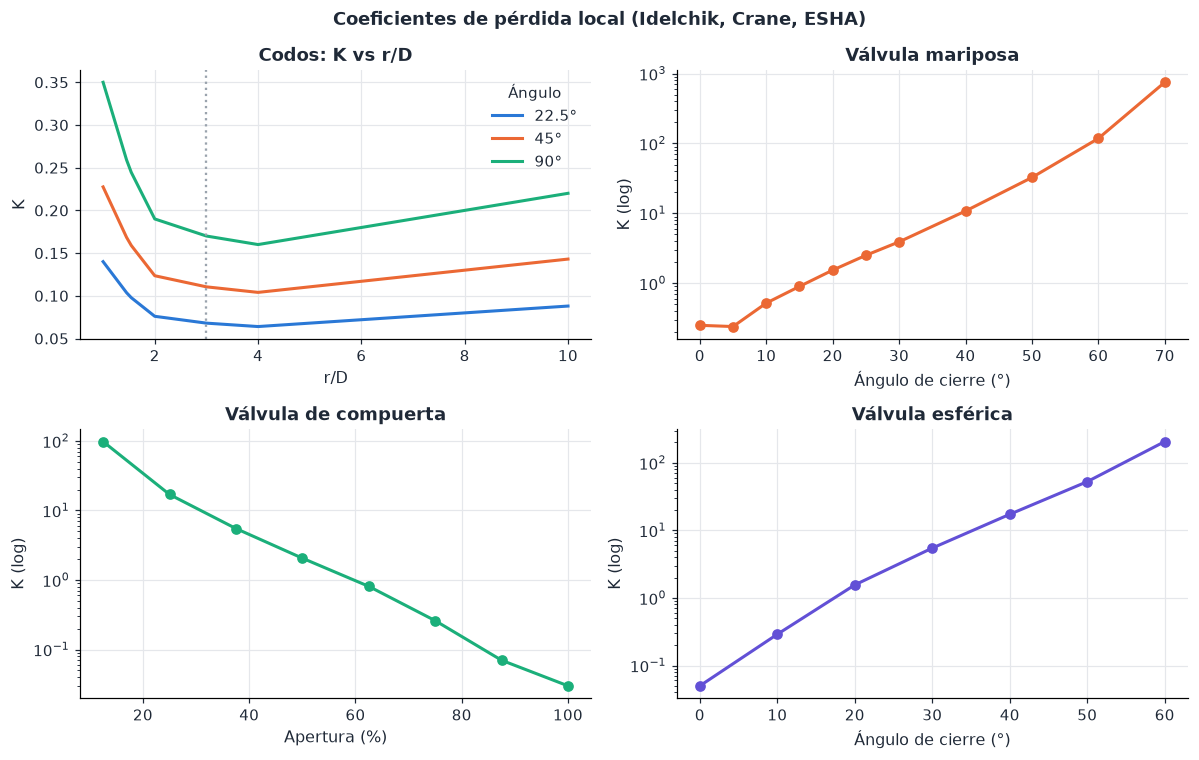

In [15]:
# ============================================================
# GRÁFICA 1 - CURVAS DE PÉRDIDA DE ACCESORIOS Y VÁLVULAS
# ============================================================

fig, ax = plt.subplots(2, 2, figsize=(11, 7))                 # Cuatro paneles: codos, mariposa, compuerta, esférica.
rd = np.linspace(1, 10, 100)                                  # Malla de r/D para las curvas de codos.
for k, ang in enumerate([22.5, 45, 90]):                      # Tres ángulos de codo típicos.
    ax[0, 0].plot(rd, K_codo(ang, rd), lw=2, color=PALETA[k], label=f"{ang:g}°")  # Curva K(r/D).
ax[0, 0].axvline(3, color=GRIS, ls=":")                       # r/D = 3 adoptado en el proyecto.
ax[0, 0].set(title="Codos: K vs r/D", xlabel="r/D", ylabel="K")  # Rótulos.
ax[0, 0].legend(title="Ángulo")                               # Leyenda.
ax[0, 1].semilogy(MARIPOSA_ANG, MARIPOSA_K, "o-", color=PALETA[1], lw=2)  # Mariposa en escala log.
ax[0, 1].set(title="Válvula mariposa", xlabel="Ángulo de cierre (°)", ylabel="K (log)")  # Rótulos.
ax[1, 0].semilogy(COMPUERTA_AP * 100, COMPUERTA_K, "o-", color=PALETA[2], lw=2)  # Compuerta en escala log.
ax[1, 0].set(title="Válvula de compuerta", xlabel="Apertura (%)", ylabel="K (log)")  # Rótulos.
ax[1, 1].semilogy(ESFERICA_ANG, ESFERICA_K, "o-", color=PALETA[6], lw=2)  # Esférica en escala log.
ax[1, 1].set(title="Válvula esférica", xlabel="Ángulo de cierre (°)", ylabel="K (log)")  # Rótulos.
fig.suptitle("Coeficientes de pérdida local (Idelchik, Crane, ESHA)", fontweight="bold")  # Título general.
fig.tight_layout()                                            # Ajusta márgenes.
plt.show()                                                    # Dibuja.

**Lectura de ingeniería.** Una mariposa a 30° de cierre ya multiplica su pérdida por 15 y a 60° por casi 500: por eso las válvulas de guarda y de admisión **nunca se usan para regular caudal**, solo trabajan totalmente abiertas o cerradas. La regulación la hace el distribuidor de la turbina. En codos, el mínimo de $K$ está en $r/D \approx 3$–4; radios mayores alargan la pieza sin reducir la pérdida.

### 5.1 Selección del tipo y la cantidad de accesorios del tramo

El tramo se define con el diccionario `accesorios_tramo` de la celda de parámetros: a cada **ID** de la tabla anterior se le asigna su **cantidad**. Hay tres formas de elegirlos:

1. **Editar el diccionario** en la sección 3 y ejecutar *Restart & Run All*.
2. **Por consola**, como en el Taller 1: con `seleccion_por_consola = True` la celda siguiente muestra el menú de cada categoría y pregunta el tipo y la cantidad.
3. **Con el selector interactivo** de la sección 6.1, que muestra las pérdidas al instante para cualquier diámetro.

Con la selección se arma el inventario del tramo, se calcula $n_i K_i$ de cada renglón y su suma $K_{total}$ entra en el modelo hidráulico de la sección 6.

In [16]:
# ============================================================
# SELECCIÓN POR CONSOLA (OPCIONAL, COMO EN EL TALLER 1)
# ============================================================

if seleccion_por_consola:                                     # Solo si se activó en la celda de parámetros.
    accesorios_tramo = {}                                     # Empieza un tramo vacío.
    for cat in categorias:                                    # Recorre las categorías de la base de datos.
        opciones = bd_acc[bd_acc["Categoria"] == cat]         # Tipos de accesorio de esta categoría.
        print(f"\n{cat.upper()}")                             # Encabezado de la categoría.
        for k, (id_acc, f) in enumerate(opciones.iterrows(), start=1):  # Menú numerado.
            print(f"  {k:>2}. {f.Accesorio} - {f.Detalle} (K = {f.K:.3f})")  # Una línea por tipo.
        while True:                                           # Permite elegir varios tipos de la misma categoría.
            txt = input(f"{cat}: número del tipo (Enter para pasar a la siguiente categoría): ").strip()  # Tipo elegido.
            if not txt:                                       # Enter vacío...
                break                                         # ...pasa a la siguiente categoría.
            try:                                              # Valida lo que escribió el usuario.
                id_acc = opciones.index[int(txt) - 1]         # ID del tipo elegido.
                n = int(input("   Cantidad: "))               # Cantidad de ese accesorio.
            except (ValueError, IndexError):                  # Número inválido.
                print("   Opción no válida, intente de nuevo.")  # Aviso.
                continue                                      # Vuelve a preguntar.
            accesorios_tramo[id_acc] = accesorios_tramo.get(id_acc, 0) + n  # Suma la cantidad al tramo.
    print("\naccesorios_tramo =", accesorios_tramo)           # Selección final (se puede copiar a la celda de parámetros).
else:                                                         # Selección de la celda de parámetros.
    print("Se usa la selección de la celda de parámetros (seleccion_por_consola = False).")  # Aviso.

Se usa la selección de la celda de parámetros (seleccion_por_consola = False).


In [17]:
# ============================================================
# INVENTARIO DEL TRAMO Y K TOTAL
# ============================================================

def inventario_tramo(seleccion):                              # Tabla de los accesorios elegidos con su coeficiente.
    faltan = [i for i in seleccion if i not in bd_acc.index]  # IDs que no existen en la base de datos.
    if faltan:                                                # Si hay IDs mal escritos...
        raise KeyError(f"Estos ID no están en la base de datos de accesorios: {faltan}")  # ...se avisa cuáles.
    ids = [i for i, n in seleccion.items() if n > 0]          # Solo los accesorios con cantidad positiva.
    inv = bd_acc.loc[ids, ["Categoria", "Accesorio", "Detalle"]].copy()  # Descripción de cada accesorio.
    inv["Cantidad"] = [int(seleccion[i]) for i in ids]        # n_i.
    inv["K unitario"] = bd_acc.loc[ids, "K"].values           # K_i.
    inv["K total"] = inv["Cantidad"] * inv["K unitario"]      # n_i · K_i.
    inv["Fuente"] = bd_acc.loc[ids, "Fuente"].values          # Referencia del coeficiente.
    return inv                                                # Inventario del tramo.

def perdidas_menores(inv, V):                                 # Pérdida de cada accesorio para la velocidad V de la tubería.
    tabla = inv[["Accesorio", "Detalle", "Cantidad", "K total"]].copy()  # Columnas necesarias.
    tabla["h_m [m]"] = tabla["K total"] * V ** 2 / (2 * g)    # h_m,i = n_i K_i V²/2g.
    total = tabla["h_m [m]"].sum()                            # Pérdidas menores totales.
    tabla["% de h_m"] = tabla["h_m [m]"] / total * 100 if total > 0 else 0.0  # Participación de cada accesorio.
    tabla.loc["TOTAL"] = ["TOTAL", "", tabla["Cantidad"].sum(), tabla["K total"].sum(), total, 100.0]  # Fila total.
    return tabla                                              # Tabla de pérdidas.

inventario = inventario_tramo(accesorios_tramo)               # Inventario con la selección actual.
K_total = float(inventario["K total"].sum())                  # K total del tramo.
h_m_ref = K_total * V_ref ** 2 / (2 * g)                      # Pérdidas menores con la velocidad típica de 4 m/s.
print(f"Accesorios en el tramo: {inventario['Cantidad'].sum()}  |  K total = {K_total:.3f}  (la Entrega 2 suponía 1,85)")  # Resultado.
print(f"Pérdidas menores preliminares con V = {V_ref:.0f} m/s: h_m = {h_m_ref:.3f} m (el valor final se calcula con el diámetro elegido en la sección 6)")
tabla_inv = inventario.copy()                                 # Copia para mostrar con la fila total.
tabla_inv.loc["TOTAL"] = ["", "TOTAL", "", inventario["Cantidad"].sum(), np.nan, K_total, ""]  # Fila total.
tabla_inv                                                     # Muestra el inventario.

Accesorios en el tramo: 11  |  K total = 1.154  (la Entrega 2 suponía 1,85)
Pérdidas menores preliminares con V = 4 m/s: h_m = 0.941 m (el valor final se calcula con el diámetro elegido en la sección 6)


,Categoria,Accesorio,Detalle,Cantidad,K unitario,K total,Fuente
ID,,,,,,,
ENT_ABOCINADA,Entrada,Entrada a la tubería,"abocinada o campana, r/D ≥ 0,15",1,0.040,0.040,"Idelchik, Handbook of Hydraulic Resistance, 3a ed."
REJ_RECTANGULAR,Rejilla,Rejilla de entrada,"barras rectangulares, t = 12 mm, b = 50 mm, φ = 75°",1,0.022,0.022,"ESHA, Guide on How to Develop a Small Hydropower Plant (2004), cap. 5"
CODO_45_RD3,Codo,Codo 45°,radio de curvatura r/D = 3,4,0.111,0.442,"Idelchik, Handbook of Hydraulic Resistance, 3a ed.; ESHA, Guide on How to Develop a Small Hydropower Plant (2004), c..."
VAL_MARIPOSA,Válvula,Válvula mariposa,100 % abierta (guarda o admisión),2,0.250,0.500,"Idelchik, Handbook of Hydraulic Resistance, 3a ed."
JUNTA_DILATACION,Junta y pieza,Junta de dilatación,telescópica,2,0.050,0.100,"Idelchik, Handbook of Hydraulic Resistance, 3a ed."
RED_CONICA,Cambio de sección,Reducción cónica,"gradual, ángulo ≤ 10° (p. ej. llegada a la espiral)",1,0.050,0.050,"Idelchik, Handbook of Hydraulic Resistance, 3a ed."
TOTAL,,TOTAL,,11,NaN,1.154,


In [18]:
# ============================================================
# VÁLVULAS E INSTRUMENTOS RECOMENDADOS
# ============================================================

valvulas = pd.DataFrame([                                     # Regla de anteproyecto (ESHA 2004 y catálogo WEG/HISA p. 7).
    ("Válvula de guarda (cabeza de tubería)", "Mariposa", 1, "cierre de emergencia por sobrevelocidad o rotura"),
    ("Válvula de admisión por unidad", "Esférica" if H_bruto > 200 else "Mariposa", 1, "mariposa si H ≤ 200 m; esférica si H > 200 m"),
    ("Bypass de llenado", "Compuerta pequeña", 1, "iguala presiones antes de abrir la admisión"),
    ("Ventosas doble efecto", "Válvula de aire", 2, "evitan el colapso por vacío al vaciar la tubería"),
    ("Desagüe de fondo", "Compuerta", 1, "punto bajo de la tubería"),
    ("Descarga de caudal ecológico", "Chorro hueco (Howell-Bunger)", 1, "disipa energía en descarga libre"),
], columns=["Elemento", "Tipo recomendado", "Cantidad", "Justificación"])
valvulas                                                      # Muestra la tabla.

,Elemento,Tipo recomendado,Cantidad,Justificación
0,Válvula de guarda (cabeza de tubería),Mariposa,1,cierre de emergencia por sobrevelocidad o rotura
1,Válvula de admisión por unidad,Mariposa,1,mariposa si H ≤ 200 m; esférica si H > 200 m
2,Bypass de llenado,Compuerta pequeña,1,iguala presiones antes de abrir la admisión
3,Ventosas doble efecto,Válvula de aire,2,evitan el colapso por vacío al vaciar la tubería
4,Desagüe de fondo,Compuerta,1,punto bajo de la tubería
5,Descarga de caudal ecológico,Chorro hueco (Howell-Bunger),1,disipa energía en descarga libre


---
# 6. Modelo hidráulico y selección de la tubería

Se aplica la cadena de ecuaciones del Taller 1, ahora con el $K_{total}$ de los accesorios seleccionados en la sección 5 y con todos los diámetros comerciales del catálogo.

Área y velocidad:
$$A=\frac{\pi D^2}{4},\qquad V=\frac{Q}{A}$$

Número de Reynolds:
$$Re=\frac{VD}{\nu}$$

Factor de fricción de Darcy mediante Swamee–Jain (explícita, error < 1 % frente a Colebrook en $5000 < Re < 10^8$):
$$f=\frac{0.25}{\left[\log_{10}\left(\frac{\varepsilon}{3.7D}+\frac{5.74}{Re^{0.9}}\right)\right]^2}$$

Pérdida mayor por Darcy–Weisbach:
$$h_f=f\frac{L}{D}\frac{V^2}{2g}$$

Pérdidas menores:
$$h_m=\left(\sum K\right)\frac{V^2}{2g}$$

Pérdida total y salto neto:
$$h_L=h_f+h_m,\qquad H_n=H_b-h_L$$

Potencia hidráulica y potencia eléctrica:
$$P_h=\rho g Q H_n,\qquad P_e=P_h\,\eta_t\,\eta_g$$

**Por qué Swamee–Jain y no Colebrook.** Colebrook–White es implícita (hay que iterar). Swamee–Jain da el mismo resultado con una sola evaluación, lo que permite vectorizar el cálculo sobre los 9.124 días de la serie y sobre miles de casos del dataset de ML.

**Criterio de selección.** Se elige el **menor diámetro comercial** que cumpla simultáneamente $V_{min} \le V \le V_{max}$ y $h_L \le 6\,\%\,H_b$: el menor diámetro factible es el de menor costo de tubería. La optimización económica completa (costo de la tubería frente a la energía perdida) se hace en la sección 14.

In [19]:
# ============================================================
# FUNCIONES DEL MODELO HIDRÁULICO
# ============================================================

def swamee_jain(Re, eps_m, D):                                # Factor de fricción de Darcy (vectorizado).
    Re = np.asarray(Re, dtype=float)                          # Reynolds como arreglo de NumPy.
    with np.errstate(divide="ignore", invalid="ignore"):      # Evita avisos cuando Re = 0 (planta detenida).
        f_turb = 0.25 / np.log10(eps_m / (3.7 * D) + 5.74 / Re ** 0.9) ** 2  # Swamee-Jain (régimen turbulento).
        f_lam = 64 / Re                                       # Hagen-Poiseuille (régimen laminar).
    return np.where(Re <= 0, 0.0, np.where(Re < 2300, f_lam, f_turb))  # Escoge la ecuación según el régimen.

def hidraulica(Q, D, eps_mm, K, L=L, H_b=H_bruto, eta_t=eta_t, eta_g=eta_g):  # Cadena completa del Taller 1.
    Q = np.asarray(Q, dtype=float)                            # Caudal (m³/s), escalar o vector.
    A = np.pi * D ** 2 / 4                                    # Área de la sección (m²).
    V = Q / A                                                 # Velocidad media (m/s).
    Re = V * D / nu                                           # Número de Reynolds.
    f = swamee_jain(Re, eps_mm / 1000, D)                     # Factor de fricción (ε en metros).
    carga_v = V ** 2 / (2 * g)                                # Carga de velocidad (m).
    hf = f * (L / D) * carga_v                                # Pérdida por fricción (m).
    hm = K * carga_v                                          # Pérdidas menores (m).
    hL = hf + hm                                              # Pérdida total (m).
    Hn = H_b - hL                                             # Salto neto (m).
    Ph = rho * g * Q * Hn / 1e6                               # Potencia hidráulica (MW).
    Pe = Ph * eta_t * eta_g                                   # Potencia eléctrica en bornes (MW).
    return dict(A=A, V=V, Re=Re, f=f, hf=hf, hm=hm, hL=hL, Hn=Hn, Ph=Ph, Pe=Pe, perdida=hL / H_b)  # Resultados.

In [20]:
# ============================================================
# MATERIALES DISPONIBLES EN LA BASE DE DATOS DE TUBERÍAS
# ============================================================

print("MATERIALES DISPONIBLES:")                              # Encabezado del menú.
print("-" * 92)                                               # Línea separadora.
for k, fila in resumen_mat.iterrows():                        # Recorre los materiales del catálogo.
    print(f"{k + 1}. {fila.Material:<32} | ε = {fila.epsilon_mm:.4f} mm | "
          f"D = {fila.D_min_m:.2f} – {fila.D_max_m:.2f} m | {fila.diametros} diámetros")  # Una línea por material.

MATERIALES DISPONIBLES:
--------------------------------------------------------------------------------------------
1. Hierro dúctil NATURAL            | ε = 0.0450 mm | D = 0.06 – 2.00 m | 24 diámetros
2. PRFV / GRP Flowtite              | ε = 0.0290 mm | D = 0.20 – 4.00 m | 41 diámetros
3. PE 100-RC AGRU                   | ε = 0.0070 mm | D = 0.02 – 3.50 m | 41 diámetros
4. PVC-O TOM                        | ε = 0.0015 mm | D = 0.09 – 1.20 m | 23 diámetros


In [21]:
# ============================================================
# TABLA DE TUBERÍAS: TODOS LOS DIÁMETROS COMERCIALES AL CAUDAL DE DISEÑO
# ============================================================

r = hidraulica(Q_diseno, catalogo["Diametro_hidraulico_m"].values, catalogo["epsilon_diseno_mm"].values, K_total)  # Evalúa todo el catálogo a la vez.
tabla_tub = pd.DataFrame({                                    # Tabla de resultados por diámetro.
    "Material_ID": catalogo["Material_ID"], "D [m]": catalogo["Diametro_hidraulico_m"], "ε [mm]": catalogo["epsilon_diseno_mm"],
    "V [m/s]": r["V"], "Re": r["Re"], "f": r["f"], "h_f [m]": r["hf"], "h_m [m]": r["hm"],
    "h_total [m]": r["hL"], "Pérdida [%]": r["perdida"] * 100, "H_neto [m]": r["Hn"], "P_e [MW]": r["Pe"]})
tabla_tub["Cumple V"] = tabla_tub["V [m/s]"].between(V_min, V_max)  # Criterio de velocidad.
tabla_tub["Cumple 6%"] = tabla_tub["Pérdida [%]"] <= perdida_max * 100  # Criterio de pérdidas.
tabla_tub["Factible"] = tabla_tub["Cumple V"] & tabla_tub["Cumple 6%"]  # Ambos criterios a la vez.
tabla_tub = tabla_tub.sort_values(["Material_ID", "D [m]"]).reset_index(drop=True)  # Orden por material y diámetro.
minimos = tabla_tub[tabla_tub["Factible"]].groupby("Material_ID").first()  # Menor diámetro factible de cada material.
minimos[["D [m]", "V [m/s]", "h_total [m]", "Pérdida [%]", "H_neto [m]", "P_e [MW]"]]  # Comparación entre materiales.

,D [m],V [m/s],h_total [m],Pérdida [%],H_neto [m],P_e [MW]
Material_ID,,,,,,
GRP_FLOWTITE,2.900,4.239,4.439,5.549,75.561,18.294
PE100_AGRU,2.830,4.451,4.678,5.847,75.322,18.236


### Opciones de tubería y selección del diseñador

La tabla siguiente reúne **todas las tuberías del catálogo que cumplen el diseño** ($V_{min} \le V \le V_{max}$ y $h_L \le 6\,\%\,H_b$) al caudal de diseño. El diseñador escoge una de tres formas:

1. **Automática** (`D_tuberia = None`): el menor diámetro que cumple con el material `material_id`, que es el de menor costo de tubería.
2. **En la celda de parámetros**: `material_id` y `D_tuberia` con el diámetro deseado; se toma el diámetro comercial más cercano.
3. **Por consola**: con `seleccion_tuberia_por_consola = True` el cuaderno pregunta el número de la opción.

Si la tubería elegida no cumple el diseño, el cuaderno lo avisa y usa el menor diámetro que cumple. Al final (sección 14.2) se compara el costo de todas estas opciones frente a la seleccionada.

In [22]:
# ============================================================
# OPCIONES DE TUBERÍA QUE CUMPLEN EL DISEÑO
# ============================================================

nombre_material = dict(zip(catalogo.Material_ID, catalogo.Material))  # Nombre comercial de cada material.
opciones_tub = tabla_tub[tabla_tub["Factible"]].reset_index(drop=True)  # Solo las que cumplen V y pérdidas.
opciones_tub.insert(0, "Material", opciones_tub["Material_ID"].map(nombre_material))  # Nombre del material.
opciones_tub.index = opciones_tub.index + 1                   # Numeración desde 1 para elegir por consola.
print(f"{len(opciones_tub)} tuberías del catálogo cumplen {V_min} ≤ V ≤ {V_max} m/s y pérdidas ≤ {perdida_max:.0%} de Hb con Q = {Q_diseno:g} m³/s")
opciones_tub[["Material", "Material_ID", "D [m]", "V [m/s]", "h_total [m]", "Pérdida [%]", "H_neto [m]", "P_e [MW]"]]  # Opciones.

16 tuberías del catálogo cumplen 0.5 ≤ V ≤ 5.0 m/s y pérdidas ≤ 6% de Hb con Q = 28 m³/s


,Material,Material_ID,D [m],V [m/s],h_total [m],Pérdida [%],H_neto [m],P_e [MW]
1,PRFV / GRP Flowtite,GRP_FLOWTITE,2.900,4.239,4.439,5.549,75.561,18.294
2,PRFV / GRP Flowtite,GRP_FLOWTITE,3.000,3.961,3.777,4.721,76.223,18.455
3,PRFV / GRP Flowtite,GRP_FLOWTITE,3.100,3.710,3.231,4.038,76.769,18.587
4,PRFV / GRP Flowtite,GRP_FLOWTITE,3.200,3.482,2.778,3.473,77.222,18.696
5,PRFV / GRP Flowtite,GRP_FLOWTITE,3.300,3.274,2.401,3.002,77.599,18.788
6,PRFV / GRP Flowtite,GRP_FLOWTITE,3.400,3.084,2.085,2.606,77.915,18.864
7,PRFV / GRP Flowtite,GRP_FLOWTITE,3.500,2.910,1.818,2.273,78.182,18.929
8,PRFV / GRP Flowtite,GRP_FLOWTITE,3.600,2.751,1.592,1.990,78.408,18.984
9,PRFV / GRP Flowtite,GRP_FLOWTITE,3.700,2.604,1.399,1.749,78.601,19.030
10,PRFV / GRP Flowtite,GRP_FLOWTITE,3.800,2.469,1.235,1.543,78.765,19.070


In [23]:
# ============================================================
# SELECCIÓN DE LA TUBERÍA
# ============================================================

if seleccion_tuberia_por_consola:                             # El diseñador elige el número de la opción.
    while True:                                               # Repite hasta recibir una opción válida.
        try:                                                  # Valida la respuesta.
            elegida = opciones_tub.loc[int(input(f"Número de la tubería a usar (1 a {len(opciones_tub)}): "))]  # Fila elegida.
            break                                             # Opción válida.
        except (ValueError, KeyError):                        # Número fuera de la lista.
            print("Opción no válida, intente de nuevo.")      # Aviso.
    material_id, D_tuberia = elegida["Material_ID"], float(elegida["D [m]"])  # Material y diámetro elegidos.

res_mat = tabla_tub[tabla_tub["Material_ID"] == material_id].reset_index(drop=True)  # Diámetros del material elegido.
cumplen = res_mat[res_mat["Factible"]]                        # Diámetros que cumplen ambos criterios.
if cumplen.empty:                                             # Si ningún diámetro del material cumple...
    raise RuntimeError(f"Ningún diámetro de {material_id} cumple: elija otro material de la tabla de opciones.")  # ...se detiene.
if D_tuberia is None:                                         # Selección automática.
    sel, modo_sel = cumplen.iloc[0], "automática: menor diámetro que cumple"  # El menor diámetro válido.
else:                                                         # Diámetro pedido por el diseñador.
    cand = res_mat.loc[(res_mat["D [m]"] - D_tuberia).abs().idxmin()]  # Diámetro comercial más cercano al pedido.
    if cand["Factible"]:                                      # Cumple el diseño.
        sel, modo_sel = cand, "elegida por el diseñador"      # Se usa.
    else:                                                     # No cumple: se avisa y se usa el menor que cumple.
        print(f"⚠ {material_id} D = {cand['D [m]']:.2f} m NO cumple el diseño (V = {cand['V [m/s]']:.2f} m/s, "
              f"pérdidas = {cand['Pérdida [%]']:.2f} %); se usa el menor diámetro que cumple.")  # Aviso.
        sel, modo_sel = cumplen.iloc[0], "automática (la elegida no cumplía el diseño)"  # Respaldo.
D_sel = float(sel["D [m]"])                                   # Diámetro seleccionado (m).
mat = resumen_mat.set_index("Material_ID").loc[material_id]   # Fila del material seleccionado.
eps_sel = float(mat.epsilon_mm)                               # Rugosidad absoluta del material (mm).
h_permitida = perdida_max * H_bruto                           # Pérdida máxima admisible (m).
print(f"TUBERÍA SELECCIONADA ({modo_sel})")                   # Título.
print("-" * 92)                                               # Línea separadora.
print(f"Material = {mat.Material}  |  ε = {eps_sel:.4f} mm = {eps_sel / 1000:.7f} m")  # Material y rugosidad.
print(f"D = {D_sel:.2f} m  |  V = {sel['V [m/s]']:.2f} m/s")  # Diámetro y velocidad.
print(f"Pérdida total = {sel['h_total [m]']:.3f} m  |  Límite permitido = {h_permitida:.3f} m")  # Pérdida frente al límite.
print(f"Pérdida relativa = {sel['Pérdida [%]']:.2f} % del salto bruto")  # Pérdida relativa.
i_sel = res_mat.index[res_mat["D [m]"] == D_sel][0]           # Posición del diámetro elegido.
res_mat.iloc[max(0, i_sel - 2): i_sel + 3]                    # Comparación con dos diámetros antes y dos después.

TUBERÍA SELECCIONADA (automática: menor diámetro que cumple)
--------------------------------------------------------------------------------------------
Material = PE 100-RC AGRU  |  ε = 0.0070 mm = 0.0000070 m
D = 2.83 m  |  V = 4.45 m/s
Pérdida total = 4.678 m  |  Límite permitido = 4.800 m
Pérdida relativa = 5.85 % del salto bruto


,Material_ID,D [m],ε [mm],V [m/s],Re,f,h_f [m],h_m [m],h_total [m],Pérdida [%],H_neto [m],P_e [MW],Cumple V,Cumple 6%,Factible
35,PE100_AGRU,2.500,0.007,5.704,"14,203,469.025",0.008,6.473,1.913,8.387,10.484,71.613,17.338,False,False,False
36,PE100_AGRU,2.720,0.007,4.819,"13,054,659.030",0.008,4.270,1.365,5.636,7.044,74.364,18.005,True,False,False
37,PE100_AGRU,2.830,0.007,4.451,"12,547,234.121",0.008,3.512,1.165,4.678,5.847,75.322,18.236,True,True,True
38,PE100_AGRU,3.000,0.007,3.961,"11,836,224.187",0.008,2.636,0.923,3.559,4.448,76.441,18.507,True,True,True
39,PE100_AGRU,3.260,0.007,3.355,"10,892,230.847",0.008,1.752,0.662,2.414,3.017,77.586,18.785,True,True,True


In [24]:
# ============================================================
# RESULTADOS HIDRÁULICOS PARA EL DIÁMETRO SELECCIONADO
# ============================================================

hd = hidraulica(Q_diseno, D_sel, eps_sel, K_total)            # Evalúa el punto de diseño.
hd = {k: float(np.squeeze(v)) for k, v in hd.items()}         # Convierte los resultados a números simples.
V_sel, H_neto = hd["V"], hd["Hn"]                             # Velocidad y salto neto que usan las secciones siguientes.
resumen_hidr = pd.DataFrame({                                 # Tabla Magnitud / Valor (estilo Taller 1).
    "Magnitud": ["Diámetro seleccionado", "Velocidad media", "Número de Reynolds", "Factor de fricción Darcy (Swamee–Jain)",
                 "Pérdida por fricción", "Pérdidas menores", "Pérdida hidráulica total", "Salto neto",
                 "Potencia hidráulica", "Potencia eléctrica en bornes"],
    "Valor": [f"{D_sel:.2f} m", f"{hd['V']:.2f} m/s", f"{hd['Re']:,.0f} (turbulento)", f"{hd['f']:.5f}", f"{hd['hf']:.3f} m",
              f"{hd['hm']:.3f} m", f"{hd['hL']:.3f} m ({hd['perdida'] * 100:.2f} %)", f"{hd['Hn']:.2f} m",
              f"{hd['Ph']:.2f} MW", f"{hd['Pe']:.2f} MW"]})
resumen_hidr                                                  # Muestra el resumen.

,Magnitud,Valor
0,Diámetro seleccionado,2.83 m
1,Velocidad media,4.45 m/s
2,Número de Reynolds,"12,547,234 (turbulento)"
3,Factor de fricción Darcy (Swamee–Jain),0.00820
4,Pérdida por fricción,3.512 m
5,Pérdidas menores,1.165 m
6,Pérdida hidráulica total,4.678 m (5.85 %)
7,Salto neto,75.32 m
8,Potencia hidráulica,20.65 MW
9,Potencia eléctrica en bornes,18.24 MW


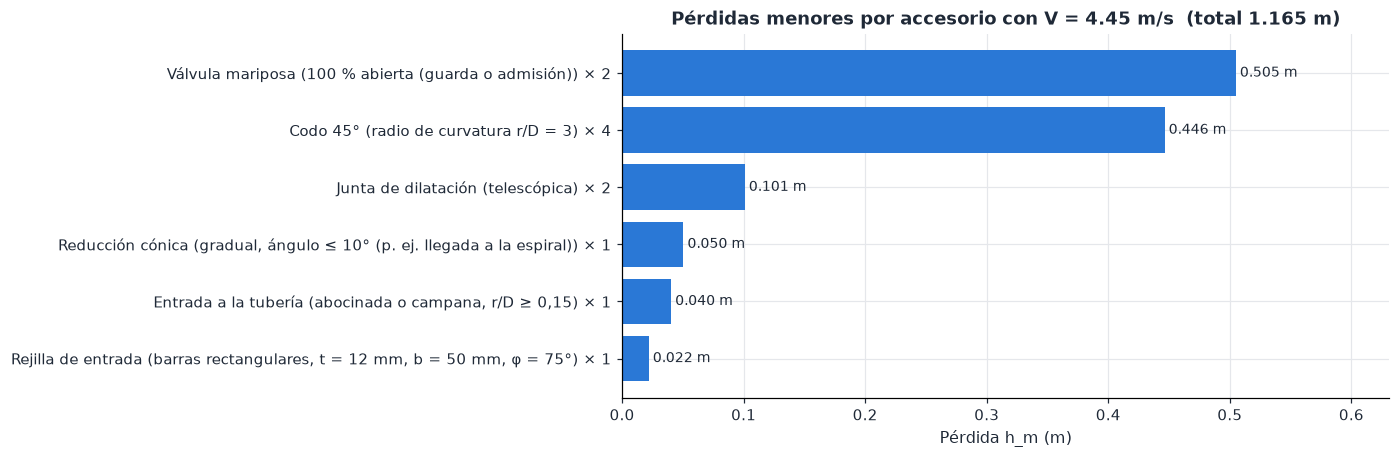

,Accesorio,Detalle,Cantidad,K total,h_m [m],% de h_m
ID,,,,,,
ENT_ABOCINADA,Entrada a la tubería,"abocinada o campana, r/D ≥ 0,15",1,0.040,0.040,3.467
REJ_RECTANGULAR,Rejilla de entrada,"barras rectangulares, t = 12 mm, b = 50 mm, φ = 75°",1,0.022,0.022,1.889
CODO_45_RD3,Codo 45°,radio de curvatura r/D = 3,4,0.442,0.446,38.309
VAL_MARIPOSA,Válvula mariposa,100 % abierta (guarda o admisión),2,0.500,0.505,43.335
JUNTA_DILATACION,Junta de dilatación,telescópica,2,0.100,0.101,8.667
RED_CONICA,Reducción cónica,"gradual, ángulo ≤ 10° (p. ej. llegada a la espiral)",1,0.050,0.050,4.334
TOTAL,TOTAL,,11,1.154,1.165,100.000


In [25]:
# ============================================================
# DESGLOSE DE PÉRDIDAS MENORES CON LA VELOCIDAD DE DISEÑO
# ============================================================

desglose = perdidas_menores(inventario, V_sel)                # h_m de cada accesorio elegido con V del diámetro seleccionado.
fig, ax = plt.subplots(figsize=(9, 0.45 * len(inventario) + 1.6))  # Alto según el número de accesorios.
d_ = desglose.drop(index="TOTAL").sort_values("h_m [m]")      # Accesorios ordenados por su pérdida.
etiquetas = [f"{a} ({d}) × {int(n)}" for a, d, n in zip(d_["Accesorio"], d_["Detalle"], d_["Cantidad"])]  # Rótulo de cada barra.
ax.barh(etiquetas, d_["h_m [m]"], color=PALETA[0])            # Pérdida de cada accesorio.
ax.set_axisbelow(True)                                        # Cuadrícula detrás de las barras.
for y, v in enumerate(d_["h_m [m]"]):                         # Valor al final de cada barra.
    ax.text(v, y, f" {v:.3f} m", va="center", fontsize=9)     # Etiqueta numérica.
ax.set(xlabel="Pérdida h_m (m)", title=f"Pérdidas menores por accesorio con V = {V_sel:.2f} m/s  (total {hd['hm']:.3f} m)")  # Rótulos.
ax.set_xlim(0, d_["h_m [m]"].max() * 1.25)                    # Espacio para las etiquetas.
plt.show()                                                    # Dibuja.
desglose                                                      # Muestra el desglose.

### 6.1 Selector interactivo de accesorios

Esta celda permite **escoger el tipo y la cantidad** de cada accesorio directamente de la base de datos y ver **al instante** cómo cambian $K_{total}$, $h_m$, $h_L$, el salto neto y la potencia, para cualquier diámetro comercial del material elegido:

1. Elija la **categoría** y el **tipo** de accesorio.
2. Escriba la **cantidad** y pulse **Agregar / cambiar** (cantidad 0 o **Quitar** lo elimina del tramo).
3. Cambie el **diámetro** para ver su efecto en las pérdidas.

Cada cambio recalcula el tramo con las ecuaciones de las secciones 5 y 6. Para llevar la nueva selección al resto del proyecto (turbina, energía, economía), ejecute desde la celda *INVENTARIO DEL TRAMO Y K TOTAL* hacia abajo, o copie el diccionario `accesorios_tramo` que imprime el selector en la celda de parámetros. Requiere `ipywidgets`; sin él, el cuaderno sigue funcionando con la selección de la sección 3.

In [26]:
# ============================================================
# SELECTOR INTERACTIVO DE ACCESORIOS CON CÁLCULO AUTOMÁTICO DE PÉRDIDAS
# ============================================================

try:                                                          # El selector necesita ipywidgets.
    import ipywidgets as widgets                              # Librería de controles interactivos.
except ImportError:                                           # Sin ipywidgets el resto del cuaderno funciona igual.
    widgets = None                                            # Marca que no hay controles.
    print("Instale ipywidgets para usar el selector: pip install ipywidgets")  # Ayuda.

if widgets is not None:                                       # Construye el selector.
    seleccion_inicial = dict(accesorios_tramo)                # Selección de partida (para el botón Restablecer).
    sel_tramo = dict(accesorios_tramo)                        # Copia de trabajo que modifican los botones.
    w_cat = widgets.Dropdown(options=categorias, description="Categoría")  # Lista de categorías.
    w_tipo = widgets.Dropdown(description="Tipo", layout=widgets.Layout(width="620px"))  # Tipos de la categoría.
    w_cant = widgets.BoundedIntText(value=1, min=0, max=100, description="Cantidad")  # Cantidad del accesorio.
    w_D = widgets.Dropdown(options=[(f"{d:.2f} m", float(d)) for d in res_mat["D [m]"]], value=D_sel,
                           description="Diámetro")            # Diámetros comerciales del material elegido.
    b_poner = widgets.Button(description="Agregar / cambiar", button_style="success", icon="plus")  # Botón agregar.
    b_quitar = widgets.Button(description="Quitar", button_style="danger", icon="trash")  # Botón quitar.
    b_reset = widgets.Button(description="Restablecer", icon="undo")  # Botón volver a la selección inicial.
    salida = widgets.Output()                                 # Zona donde se muestran los resultados.

    def actualizar_tipos(*_):                                 # Llena la lista de tipos según la categoría.
        sub = bd_acc[bd_acc["Categoria"] == w_cat.value]      # Tipos de la categoría elegida.
        w_tipo.options = [(f"{f.Accesorio} - {f.Detalle}  (K = {f.K:.3f})", i) for i, f in sub.iterrows()]  # Opciones.
        w_cant.value = sel_tramo.get(w_tipo.value, 1)         # Muestra la cantidad que ya tiene en el tramo.

    def recalcular(*_):                                       # Recalcula inventario, K total y pérdidas.
        global accesorios_tramo, inventario, K_total          # La selección queda disponible para las celdas siguientes.
        accesorios_tramo = {i: n for i, n in sel_tramo.items() if n > 0}  # Solo cantidades positivas.
        inventario = inventario_tramo(accesorios_tramo)       # Inventario con la nueva selección.
        K_total = float(inventario["K total"].sum())          # Nuevo K total.
        h = {k: float(np.squeeze(v)) for k, v in hidraulica(Q_diseno, w_D.value, eps_sel, K_total).items()}  # Hidráulica.
        cumple = (V_min <= h["V"] <= V_max) and h["perdida"] <= perdida_max  # Criterios de diseño.
        salida.clear_output()                                 # Borra el resultado anterior.
        with salida:                                          # Escribe en la zona de resultados.
            display(perdidas_menores(inventario, h["V"]).round(3))  # Pérdida de cada accesorio.
            print(f"K total = {K_total:.3f}  |  V = {h['V']:.2f} m/s  |  h_f = {h['hf']:.3f} m  |  h_m = {h['hm']:.3f} m")
            print(f"h_L = {h['hL']:.3f} m = {h['perdida']:.2%} de Hb  |  H_neto = {h['Hn']:.2f} m  |  P_e = {h['Pe']:.2f} MW  |  "
                  + ("✔ cumple V y 6 %" if cumple else "✘ no cumple V o el 6 % de pérdidas"))
            print("\naccesorios_tramo =", accesorios_tramo)   # Diccionario listo para copiar.

    def poner(_):                                             # Agrega o cambia la cantidad del tipo elegido.
        sel_tramo[w_tipo.value] = int(w_cant.value)           # Nueva cantidad.
        recalcular()                                          # Recalcula.

    def quitar(_):                                            # Elimina el tipo elegido del tramo.
        sel_tramo.pop(w_tipo.value, None)                     # Lo quita.
        recalcular()                                          # Recalcula.

    def restablecer(_):                                       # Vuelve a la selección de la celda de parámetros.
        sel_tramo.clear()                                     # Vacía la copia de trabajo.
        sel_tramo.update(seleccion_inicial)                   # Copia la selección inicial.
        recalcular()                                          # Recalcula.

    w_cat.observe(actualizar_tipos, names="value")            # Cambio de categoría → nuevos tipos.
    w_tipo.observe(lambda _: setattr(w_cant, "value", sel_tramo.get(w_tipo.value, 1)), names="value")  # Muestra su cantidad.
    w_D.observe(recalcular, names="value")                    # Cambio de diámetro → recalcula.
    b_poner.on_click(poner)                                   # Conecta los botones.
    b_quitar.on_click(quitar)
    b_reset.on_click(restablecer)
    actualizar_tipos()                                        # Llena la primera lista de tipos.
    recalcular()                                              # Primer cálculo con la selección actual.
    display(widgets.VBox([widgets.HBox([w_cat, w_D]), w_tipo, widgets.HBox([w_cant, b_poner, b_quitar, b_reset]), salida]))  # Muestra el selector.

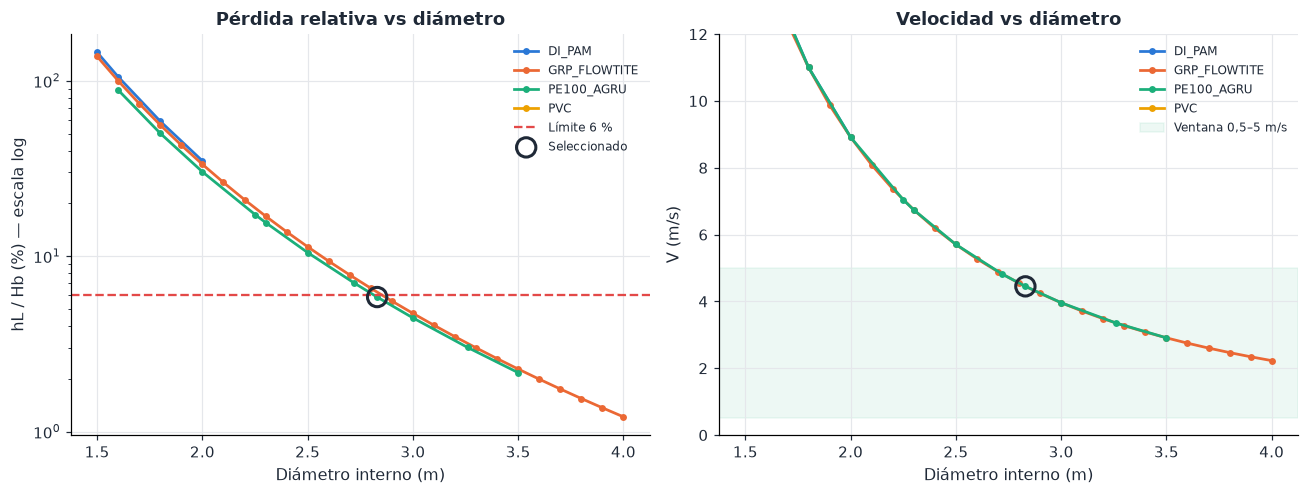

In [27]:
# ============================================================
# GRÁFICA 2 - PÉRDIDAS VS DIÁMETRO PARA CADA MATERIAL
# ============================================================

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))               # Dos paneles: pérdida relativa y velocidad.
for k, (m, gm) in enumerate(tabla_tub.groupby("Material_ID")):  # Una curva por material.
    gm = gm[(gm["D [m]"] >= 1.5)]                             # Rango de diámetros con sentido para 28 m³/s.
    ax[0].plot(gm["D [m]"], gm["Pérdida [%]"], "o-", ms=3.5, lw=1.8, color=PALETA[k], label=m)  # Pérdida relativa.
    ax[1].plot(gm["D [m]"], gm["V [m/s]"], "o-", ms=3.5, lw=1.8, color=PALETA[k], label=m)  # Velocidad.
ax[0].axhline(perdida_max * 100, color=PALETA[7], ls="--", lw=1.5, label="Límite 6 %")  # Límite de pérdidas.
ax[0].scatter(D_sel, hd["perdida"] * 100, s=160, facecolor="none", edgecolor=TINTA, lw=2, zorder=5, label="Seleccionado")  # Punto elegido.
ax[0].set(yscale="log", xlabel="Diámetro interno (m)", ylabel="hL / Hb (%) — escala log", title="Pérdida relativa vs diámetro")  # Rótulos.
ax[1].axhspan(V_min, V_max, color=PALETA[2], alpha=0.08, label="Ventana 0,5–5 m/s")  # Ventana de velocidad admisible.
ax[1].scatter(D_sel, V_sel, s=160, facecolor="none", edgecolor=TINTA, lw=2, zorder=5)  # Punto elegido.
ax[1].set(xlabel="Diámetro interno (m)", ylabel="V (m/s)", title="Velocidad vs diámetro", ylim=(0, 12))  # Rótulos.
ax[0].legend(fontsize=8)                                      # Leyenda del primer panel.
ax[1].legend(fontsize=8)                                      # Leyenda del segundo panel.
fig.tight_layout()                                            # Ajusta márgenes.
plt.show()                                                    # Dibuja.

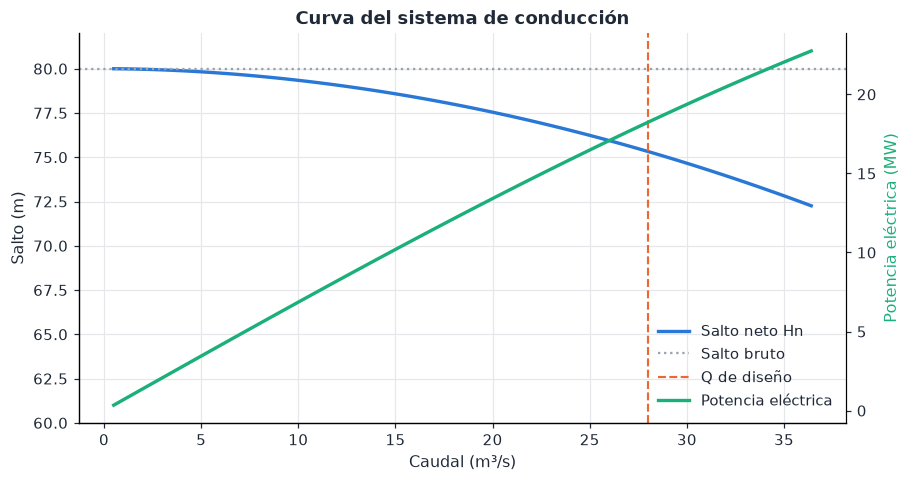

In [28]:
# ============================================================
# GRÁFICA 3 - CURVA DEL SISTEMA: SALTO NETO Y POTENCIA VS CAUDAL
# ============================================================

Qs = np.linspace(0.5, 1.3 * Q_diseno, 120)                    # Caudales de 0,5 m³/s a 130 % del diseño.
cs = hidraulica(Qs, D_sel, eps_sel, K_total)                  # Curva del sistema con la tubería elegida.
fig, ax = plt.subplots()                                      # Figura.
ax.plot(Qs, cs["Hn"], lw=2.2, color=PALETA[0], label="Salto neto Hn")  # Salto neto.
ax.axhline(H_bruto, color=GRIS, ls=":", label="Salto bruto")  # Referencia del salto bruto.
ax.axvline(Q_diseno, color=PALETA[1], ls="--", lw=1.4, label="Q de diseño")  # Caudal de diseño.
ax.set(xlabel="Caudal (m³/s)", ylabel="Salto (m)", title="Curva del sistema de conducción", ylim=(60, 82))  # Rótulos.
ax2 = ax.twinx()                                              # Segundo eje para la potencia.
ax2.plot(Qs, cs["Pe"], lw=2.2, color=PALETA[2], label="Potencia eléctrica")  # Potencia eléctrica.
ax2.set_ylabel("Potencia eléctrica (MW)", color=PALETA[2])    # Rótulo del segundo eje.
ax2.grid(False)                                               # Sin rejilla duplicada.
ax2.spines["right"].set_visible(True)                         # Muestra el eje derecho.
h1, l1 = ax.get_legend_handles_labels()                       # Elementos del primer eje.
h2, l2 = ax2.get_legend_handles_labels()                      # Elementos del segundo eje.
ax.legend(h1 + h2, l1 + l2, loc="lower right")                # Leyenda conjunta en la zona libre.
plt.show()                                                    # Dibuja.

**Lectura de ingeniería.** El salto neto cae con $Q^2$ (las pérdidas son proporcionales a $V^2$), así que la potencia deja de crecer linealmente al aumentar el caudal. Con el diámetro elegido, a 130 % del caudal de diseño la pérdida ya superaría el 9 %: el caudal de diseño y el diámetro deben decidirse juntos, que es exactamente lo que hace la optimización de la sección 14.

---
# 7. Golpe de ariete y espesor de pared

Al cerrar la válvula de guarda la columna de agua se frena y su energía cinética se convierte en una onda de presión que viaja por la tubería.

Celeridad de la onda (depende de la compresibilidad del agua y de la elasticidad de la pared):

$$a=\sqrt{\frac{K_w/\rho}{1+\dfrac{K_w\,D}{E\,e}}}$$

donde $K_w = 2{,}2$ GPa es el módulo volumétrico del agua, $E$ el módulo de elasticidad del material y $e$ el espesor de pared.

Tiempo crítico (ida y vuelta de la onda):

$$T_c=\frac{2L}{a}$$

Sobrepresión con cierre rápido, $T \le T_c$ (Joukowsky):

$$\Delta h=\frac{a\,V}{g}$$

Sobrepresión con cierre lento, $T > T_c$ (Michaud):

$$\Delta h=\frac{2\,L\,V}{g\,T}$$

Tiempo mínimo de cierre para limitar la sobrepresión al 30 % del salto bruto (criterio de diseño adoptado):

$$T_{min}=\frac{2\,L\,V}{g\,(0.30\,H_b)}$$

Espesor de la tubería de acero de referencia, fórmula de Barlow más sobreespesor por corrosión, y espesor mínimo de manipulación de USBR:

$$e=\frac{p\,D}{2\,\sigma_{adm}\,E_j}+e_c,\qquad e_{min}=\frac{D+508}{400}\ \text{(mm)}$$

In [29]:
# ============================================================
# GOLPE DE ARIETE CON EL MATERIAL SELECCIONADO
# ============================================================

E_GPa = {"GRP_FLOWTITE": 15, "PE100_AGRU": 1.1, "DI_PAM": 170, "PVC": 3.0, "STEEL_WELDED": 206}  # Módulo de elasticidad (GPa).
p_m = H_bruto * 1.3                                           # Presión de diseño en m.c.a. (estática + 30 %).
if material_id == "PE100_AGRU":                               # Polietileno: la clase la fija el SDR.
    sdr = 17 if p_m <= 100 else 11 if p_m <= 160 else 7.4     # SDR 17 = PN10, SDR 11 = PN16, SDR 7,4 = PN25.
    e_mm, clase = D_sel * 1000 / (sdr - 2), f"PE100 SDR {sdr:g}"  # Espesor a partir del diámetro interno.
elif material_id == "GRP_FLOWTITE":                           # Fibra de vidrio: orden de magnitud del catálogo Flowtite.
    e_mm, clase = D_sel * 1000 / 90, "GRP PN10 SN5000 (e ≈ D/90)"  # Espesor aproximado de catálogo.
elif material_id == "DI_PAM":                                 # Fundición dúctil clase K9.
    e_mm, clase = 9 * (0.5 + D_sel), "Fundición dúctil K9"    # e = 9·(0,5 + 0,001·DN) mm.
else:                                                         # PVC de pared lisa.
    e_mm, clase = D_sel * 1000 / 24, "PVC SDR 26"             # Espesor por SDR.
a = np.sqrt((2.2e9 / rho) / (1 + 2.2e9 * D_sel / (E_GPa[material_id] * 1e9 * e_mm / 1000)))  # Celeridad de la onda (m/s).
Tc = 2 * L / a                                                # Tiempo crítico de ida y vuelta (s).
dh_jouk = a * V_sel / g                                       # Sobrepresión de Joukowsky (m).
dh_T = dh_jouk if T_cierre <= Tc else 2 * L * V_sel / (g * T_cierre)  # Sobrepresión con el tiempo de cierre elegido.
T_min = 2 * L * V_sel / (g * 0.30 * H_bruto)                  # Tiempo de cierre que limita la sobrepresión al 30 %.
ariete = pd.DataFrame({"Magnitud": ["Clase de tubería", "Espesor de pared", "Celeridad a", "Tiempo crítico 2L/a",
                                    "Δh Joukowsky (cierre instantáneo)", f"Δh con cierre de {T_cierre:.0f} s",
                                    "Tiempo mínimo de cierre (Δh ≤ 30 % Hb)"],
                       "Valor": [clase, f"{e_mm:.0f} mm", f"{a:.0f} m/s", f"{Tc:.1f} s", f"{dh_jouk:.0f} m",
                                 f"{dh_T:.0f} m ({dh_T / H_bruto * 100:.0f} % de Hb)", f"{T_min:.0f} s"]})
ariete                                                        # Muestra la tabla.

,Magnitud,Valor
0,Clase de tubería,PE100 SDR 11
1,Espesor de pared,314 mm
2,Celeridad a,341 m/s
3,Tiempo crítico 2L/a,7.0 s
4,Δh Joukowsky (cierre instantáneo),155 m
5,Δh con cierre de 10 s,109 m (136 % de Hb)
6,Tiempo mínimo de cierre (Δh ≤ 30 % Hb),45 s


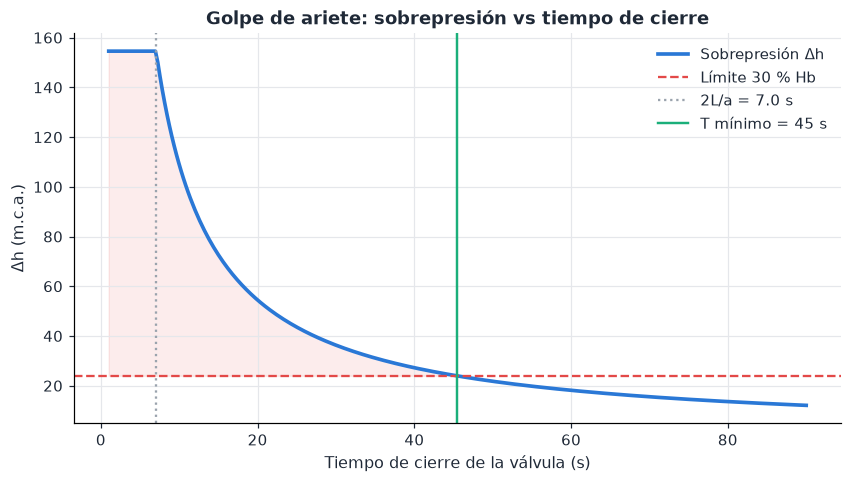

In [30]:
# ============================================================
# GRÁFICA 4 - SOBREPRESIÓN VS TIEMPO DE CIERRE
# ============================================================

T = np.linspace(1, 90, 300)                                   # Tiempos de cierre de 1 a 90 s.
dh = np.where(T <= Tc, dh_jouk, 2 * L * V_sel / (g * T))      # Joukowsky hasta Tc y Michaud después.
fig, ax = plt.subplots()                                      # Figura.
ax.plot(T, dh, lw=2.4, color=PALETA[0], label="Sobrepresión Δh")  # Curva Δh(T).
ax.axhline(0.30 * H_bruto, color=PALETA[7], ls="--", label="Límite 30 % Hb")  # Límite de diseño.
ax.axvline(Tc, color=GRIS, ls=":", label=f"2L/a = {Tc:.1f} s")  # Tiempo crítico.
ax.axvline(T_min, color=PALETA[2], lw=1.6, label=f"T mínimo = {T_min:.0f} s")  # Tiempo mínimo recomendado.
ax.fill_between(T, dh, 0.30 * H_bruto, where=dh > 0.30 * H_bruto, color=PALETA[7], alpha=0.10)  # Zona prohibida.
ax.set(xlabel="Tiempo de cierre de la válvula (s)", ylabel="Δh (m.c.a.)", title="Golpe de ariete: sobrepresión vs tiempo de cierre")  # Rótulos.
ax.legend()                                                   # Leyenda.
plt.show()                                                    # Dibuja.

**Decisión.** Con un cierre de 10 s la sobrepresión supera ampliamente el salto estático, lo que obligaría a una tubería de clase muy superior. Se especifica una **ley de cierre del regulador y de la válvula de guarda no menor que el tiempo mínimo calculado**, más una válvula de alivio sincronizada. Con ese tiempo la presión máxima queda en $1{,}3\,H_b$, que es justamente la presión usada para escoger la clase de la tubería.

In [31]:
# ============================================================
# TABLA DE ESPESORES DE TUBERÍA DE ACERO (ALTERNATIVA DE REFERENCIA) Y VALIDACIÓN API 5L
# ============================================================

sigma_adm, E_j, e_corr, precio_acero = 137.0, 0.90, 2.0, 1650.0  # MPa, eficiencia de junta, corrosión (mm), USD/t.
p_MPa = rho * g * H_bruto * 1.30 / 1e6                        # Presión de diseño con 30 % de golpe de ariete (MPa).
filas = []                                                    # Lista de filas de la tabla.
for DN in range(2000, 3750, 250):                             # Diámetros nominales de 2.000 a 3.500 mm.
    e_p = p_MPa * DN / (2 * sigma_adm * E_j) + e_corr         # Espesor por presión (Barlow) + corrosión (mm).
    e_min = (DN + 508) / 400                                  # Espesor mínimo de manipulación USBR (mm).
    e_ad = np.ceil(max(e_p, e_min))                           # Espesor adoptado: el mayor, redondeado al mm.
    masa = np.pi * (DN / 1000 + e_ad / 1000) * e_ad / 1000 * 7850  # Masa por metro (kg/m).
    filas.append([DN, e_p, e_min, e_ad, masa, masa * L / 1000, masa * L / 1000 * precio_acero / 1e6])  # Agrega la fila.
tabla_acero = pd.DataFrame(filas, columns=["DN [mm]", "e presión [mm]", "e mínimo USBR [mm]", "e adoptado [mm]",
                                           "masa [kg/m]", "masa total [t]", "material [MUSD]"])  # Tabla final.
api = pd.DataFrame([(1016.0, 12.7, 314.22), (1422.0, 19.1, 660.77), (1524.0, 25.4, 938.67), (1829.0, 22.2, 989.14)],
                   columns=["OD [mm]", "e [mm]", "kg/m catálogo API 5L"])  # Masas publicadas en el catálogo API 5L (petrol01.pdf).
api["kg/m calculado"] = np.pi * (api["OD [mm]"] - api["e [mm]"]) / 1000 * api["e [mm]"] / 1000 * 7850  # Misma fórmula de masa.
api["error [%]"] = (api["kg/m calculado"] / api["kg/m catálogo API 5L"] - 1) * 100  # Error de la fórmula.
display(tabla_acero)                                          # Muestra la tabla de acero.
api                                                           # Muestra la validación: la fórmula de masa reproduce el catálogo con error < 0,5 %.

,DN [mm],e presión [mm],e mínimo USBR [mm],e adoptado [mm],masa [kg/m],masa total [t],material [MUSD]
0,2000,10.258,6.270,11.000,545.537,654.645,1.080
1,2250,11.290,6.895,12.000,669.412,803.294,1.325
2,2500,12.322,7.520,13.000,805.667,966.800,1.595
3,2750,13.355,8.145,14.000,954.301,"1,145.162",1.890
4,3000,14.387,8.770,15.000,"1,115.316","1,338.380",2.208
5,3250,15.419,9.395,16.000,"1,288.711","1,546.454",2.552
6,3500,16.451,10.020,17.000,"1,474.487","1,769.384",2.919


,OD [mm],e [mm],kg/m catálogo API 5L,kg/m calculado,error [%]
0,"1,016.000",12.700,314.220,314.235,0.005
1,"1,422.000",19.100,660.770,660.815,0.007
2,"1,524.000",25.400,938.670,938.726,0.006
3,"1,829.000",22.200,989.140,989.197,0.006


---
# 8. Selección de turbina con *Gradient Boosting*

La selección se hace en cuatro pasos:

| Paso | Herramienta | Pregunta que responde |
|---|---|---|
| 8.1 | Ecuaciones de turbomáquinas | ¿Qué tipos son posibles con este $Q$ y $H_n$ (velocidad específica, velocidad síncrona, cavitación)? |
| 8.2 | Catálogos WEG, ANDRITZ y Flygt | ¿Algún fabricante ofrece ese tipo en ese punto? |
| 8.3–8.5 | **GradientBoostingClassifier** | Dado un punto $(Q, H)$, ¿qué tipo de turbina corresponde y con qué confianza? |
| 8.6–8.7 | Verificación física y ficha técnica | ¿La turbina propuesta por el modelo es factible? ¿Cuántas unidades, a qué velocidad, con qué rodete? |

### 8.1 Fundamento físico

Velocidad síncrona del generador (red de 60 Hz, $p$ polos):

$$n=\frac{120\,f}{p}=\frac{7200}{p}\ \ \text{rpm}$$

Velocidad específica adimensional ($n$ en rev/s), que describe la forma del rodete y por tanto el tipo de turbina (ESHA 2004):

$$n_{QE}=\frac{n\,\sqrt{Q}}{(g\,H)^{3/4}}$$

Velocidad específica en el sistema métrico:

$$n_s=\frac{n\,\sqrt{P_{kW}}}{H^{5/4}}$$

Rangos de aplicación de cada tipo:

| Tipo | Salto (m) | $n_{QE}$ | $n_s$ | Caudal mínimo técnico |
|---|---|---|---|---|
| Pelton | 50 – 1.300 | 0,005 – 0,061 | 5 – 70 | 10 % |
| Francis | 10 – 400 | 0,05 – 0,33 | 50 – 400 | 40 % |
| Kaplan | 2 – 40 | 0,19 – 1,55 | 300 – 1.100 | 20 % |
| Michell-Banki (flujo cruzado) | 2 – 200 | 0,01 – 0,12 | 20 – 200 | 15 % |

Coeficiente de cavitación de Thoma para turbinas de reacción (Francis, Kaplan):

$$\sigma=1.2715\,n_{QE}^{1.41}+\frac{V^2}{2gH}$$

Altura de aspiración admisible del rodete:

$$H_s=\frac{p_{atm}}{\rho g}-\frac{p_v}{\rho g}+\frac{V^2}{2g}-\sigma\,H$$

Se acepta $H_s \ge -6$ m: el rodete puede quedar hasta 6 m por debajo del nivel de descarga; más que eso encarece mucho la excavación de la casa de máquinas.

In [32]:
# ============================================================
# BASE DE DATOS DE TURBINAS Y VERIFICACIÓN FÍSICA
# ============================================================

TURBINAS = {                                                  # Rango de salto, caudal mínimo, n_s y curva de eficiencia vs Q/Qn (ESHA 2004, cap. 6).
    "Pelton": dict(H=(50, 1300), q_min=0.10, ns=(5, 70), nqe=(0.005, 0.0612),
                   q_rel=[0.10, 0.20, 0.40, 0.60, 0.80, 1.00], eta=[0.80, 0.87, 0.90, 0.91, 0.91, 0.90]),
    "Francis": dict(H=(10, 400), q_min=0.40, ns=(50, 400), nqe=(0.05, 0.33),
                    q_rel=[0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 1.00], eta=[0.78, 0.84, 0.88, 0.91, 0.93, 0.94, 0.92]),
    "Kaplan": dict(H=(2, 40), q_min=0.20, ns=(300, 1100), nqe=(0.19, 1.55),
                   q_rel=[0.20, 0.40, 0.60, 0.80, 1.00], eta=[0.82, 0.90, 0.92, 0.93, 0.92]),
    "Michell-Banki": dict(H=(2, 200), q_min=0.15, ns=(20, 200), nqe=(0.01, 0.12), P_max_kW=3000,
                          q_rel=[0.15, 0.20, 0.40, 0.60, 0.80, 1.00], eta=[0.70, 0.77, 0.80, 0.81, 0.81, 0.79]),
}
POLOS = np.arange(4, 82, 2)                                   # Números de polos posibles del generador.
N_SINC = 7200 / POLOS                                         # Velocidades síncronas a 60 Hz (rpm), de 1.800 a 91 rpm.
HS_MIN = -6.0                                                 # Sumergencia máxima aceptada del rodete (m), SUPUESTO de excavación.

def eta_turbina(tipo, q_rel):                                 # Eficiencia a carga parcial por interpolación de la curva típica.
    t = TURBINAS[tipo]                                        # Datos del tipo.
    q_rel = np.asarray(q_rel, dtype=float)                    # Caudal relativo Q/Qn.
    return np.where(q_rel < t["q_min"], 0.0, np.interp(q_rel, t["q_rel"], t["eta"]))  # Bajo el mínimo técnico la unidad se apaga.

def altura_aspiracion(nq, H, V2=2.0, cota=cota_casa_maquinas):  # Altura de aspiración admisible (Thoma).
    sigma = 1.2715 * nq ** 1.41 + V2 ** 2 / (2 * g * H)       # Coeficiente de cavitación de Thoma.
    h_atm = 101325 * (1 - 2.25577e-5 * cota) ** 5.25588 / (rho * g)  # Presión atmosférica a la cota (m.c.a.).
    return h_atm - 0.2388 + V2 ** 2 / (2 * g) - sigma * H     # Hs = Hatm − Hv + V²/2g − σH (Hv a 20 °C = 0,2388 m).

def factibilidad(tipo, H, Q_u):                               # ¿El tipo es físicamente posible para una unidad de caudal Q_u y salto H?
    t = TURBINAS[tipo]                                        # Datos del tipo.
    P_kW = rho * g * Q_u * H * max(t["eta"]) * eta_g / 1000   # Potencia por unidad (kW).
    ns = N_SINC * np.sqrt(P_kW) / H ** 1.25                   # n_s para cada velocidad síncrona.
    nq = (N_SINC / 60) * np.sqrt(Q_u) / (g * H) ** 0.75       # n_QE para cada velocidad síncrona.
    ok = (ns >= t["ns"][0]) & (ns <= t["ns"][1]) & (nq >= t["nqe"][0]) & (nq <= t["nqe"][1]) & (N_SINC >= 200)  # Rangos y n ≥ 200 rpm.
    if tipo in ("Francis", "Kaplan"):                         # Turbinas de reacción...
        ok &= altura_aspiracion(nq, H) >= HS_MIN              # ...también deben cumplir la cavitación.
    motivos = []                                              # Lista de razones de rechazo.
    if not t["H"][0] <= H <= t["H"][1]:                       # Salto fuera del rango del tipo.
        motivos.append(f"salto fuera de {t['H'][0]}–{t['H'][1]} m")  # Registra el motivo.
    if not ok.any():                                          # Ninguna velocidad síncrona cumple.
        motivos.append("sin velocidad síncrona que cumpla n_s, n_QE y Hs")  # Registra el motivo.
    if P_kW > t.get("P_max_kW", np.inf):                      # Límite de potencia del flujo cruzado.
        motivos.append(f"P por unidad > {t['P_max_kW']} kW")  # Registra el motivo.
    i = np.argmax(ok) if ok.any() else None                   # Mayor velocidad factible: generador más pequeño y barato.
    return dict(tipo=tipo, factible=not motivos, motivo="; ".join(motivos) or "OK", P_unidad_kW=P_kW,
                n_rpm=N_SINC[i] if i is not None else np.nan, polos=int(POLOS[i]) if i is not None else None,
                nQE=nq[i] if i is not None else np.nan, ns=ns[i] if i is not None else np.nan)  # Resultado.

pd.DataFrame([factibilidad(t, H_neto, Q_diseno) for t in TURBINAS])  # Verificación de los cuatro tipos con 1 unidad.

,tipo,factible,motivo,P_unidad_kW,n_rpm,polos,nQE,ns
0,Pelton,False,"sin velocidad síncrona que cumpla n_s, n_QE y Hs","18,038.222",NaN,NaN,NaN,NaN
1,Francis,True,OK,"18,632.888",400.000,18.000,0.249,246.063
2,Kaplan,False,"salto fuera de 2–40 m; sin velocidad síncrona que cumpla n_s, n_QE y Hs","18,434.666",NaN,NaN,NaN,NaN
3,Michell-Banki,False,"sin velocidad síncrona que cumpla n_s, n_QE y Hs; P por unidad > 3000 kW","16,056.000",NaN,NaN,NaN,NaN


### 8.2 Envolventes de aplicación de los fabricantes

Las zonas de aplicación caudal–salto se digitalizaron de los catálogos entregados en clase (lectura sobre gráficas log-log, error estimado ±5 %): **WEG/HISA** *Hydraulic Turbines* p. 3 (Pelton, Francis, Kaplan), **ANDRITZ** *Bombas como turbinas ACT/FPT* p. 5 y **Xylem Flygt** 2218 p. 4 (semi-Kaplan sumergible). Un punto pertenece a la envolvente si cae dentro del polígono en coordenadas $(\log Q, \log H)$.

In [33]:
# ENVOLVENTES DE CATÁLOGO (Q m³/s, H m) Y EVALUACIÓN DEL PUNTO DE DISEÑO
ENVOLVENTES = {                                               # Polígonos digitalizados de los catálogos.
    ("WEG", "Pelton"): [(0.30, 100), (0.30, 301), (0.405, 399), (1.55, 502), (6.08, 552), (12.3, 280), (1.02, 100)],
    ("WEG", "Francis"): [(0.504, 151), (1.55, 250), (23.3, 250), (46.4, 121.5), (27.4, 8.0), (4.07, 8.0), (0.504, 66.4)],
    ("WEG", "Kaplan"): [(3.09, 17.8), (8.95, 34.7), (99.3, 34.7), (218, 15.2), (71.3, 3.97), (14.1, 3.97)],
    ("ANDRITZ", "Bomba como turbina"): [(0.03, 10), (0.10, 55), (1.0, 80), (2.5, 80), (2.5, 5), (0.33, 3), (0.13, 3)],
    ("Flygt", "Semi-Kaplan"): [(0.7, 5), (0.7, 10), (1.0, 17), (2.2, 20), (2.8, 20), (4.0, 17), (8.0, 10),
                               (28, 10), (45, 6.5), (45, 4), (35, 2.5), (6, 2.5), (1.0, 3.5)],
}
P_MAX_CAT = {("WEG", "Pelton"): 30000, ("WEG", "Francis"): 50000, ("WEG", "Kaplan"): 30000,
             ("ANDRITZ", "Bomba como turbina"): 2000, ("Flygt", "Semi-Kaplan"): 2800}  # Potencia máxima por unidad (kW).

def dentro(clave, Q, H):                                      # Prueba punto-en-polígono en escala logarítmica.
    return bool(MplPath(np.log10(ENVOLVENTES[clave])).contains_point((np.log10(Q), np.log10(H))))  # True si el punto está dentro.

filas = []                                                    # Tabla de selección por fabricante.
for clave in ENVOLVENTES:                                     # Recorre cada envolvente.
    for k in range(1, n_unidades_max + 1):                    # Y cada número de unidades.
        P_u = rho * g * Q_diseno / k * H_neto * 0.90 * eta_g / 1000  # Potencia por unidad con η de referencia 0,90 (kW).
        ok = dentro(clave, Q_diseno / k, H_neto) and P_u <= P_MAX_CAT[clave]  # Envolvente y potencia.
        filas.append([*clave, k, Q_diseno / k, P_u, "APTA" if ok else "no"])  # Agrega la fila.
cat = pd.DataFrame(filas, columns=["Fabricante", "Tipo", "Unidades", "Q por unidad", "P por unidad [kW]", "Resultado"])  # Tabla.
cat.pivot_table(index=["Fabricante", "Tipo"], columns="Unidades", values="Resultado", aggfunc="first")  # Matriz fabricante × unidades.

Unidades                          1     2     3
Fabricante Tipo                                
ANDRITZ    Bomba como turbina    no    no    no
Flygt      Semi-Kaplan           no    no    no
WEG        Francis             APTA  APTA  APTA
           Kaplan                no    no    no
           Pelton                no    no    no

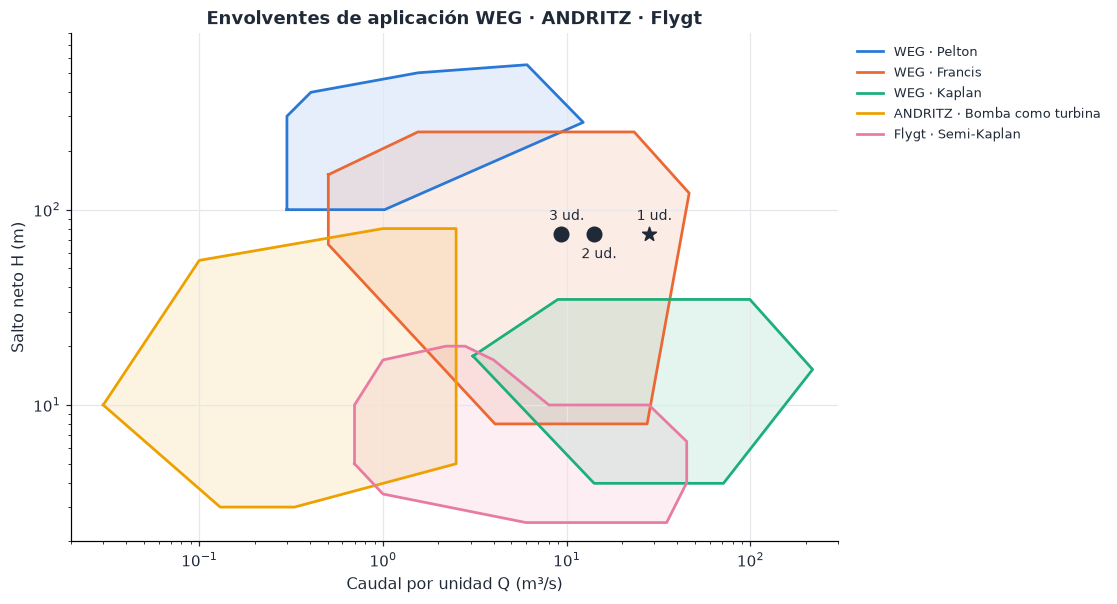

In [34]:
# ============================================================
# GRÁFICA 5 - CARTA DE SELECCIÓN POR FABRICANTE CON EL PUNTO DE DISEÑO
# ============================================================

fig, ax = plt.subplots(figsize=(9, 6))                        # Figura.
for k, (clave, pts) in enumerate(ENVOLVENTES.items()):        # Una envolvente por color.
    p = np.array(pts + [pts[0]])                              # Cierra el polígono.
    ax.fill(p[:, 0], p[:, 1], color=PALETA[k], alpha=0.12)    # Relleno suave.
    ax.plot(p[:, 0], p[:, 1], color=PALETA[k], lw=1.8, label=f"{clave[0]} · {clave[1]}")  # Contorno.
for k in range(1, n_unidades_max + 1):                        # Punto de diseño con 1, 2 y 3 unidades.
    ax.scatter(Q_diseno / k, H_neto, s=90, color=TINTA, marker="*" if k == 1 else "o", zorder=6)  # Punto por unidad.
    ax.annotate(f"{k} ud.", (Q_diseno / k, H_neto), xytext=(-8, 9 if k % 2 else -16), textcoords="offset points", fontsize=9)  # Etiqueta alternada arriba/abajo.
ax.set(xscale="log", yscale="log", xlim=(0.02, 300), ylim=(2, 800), xlabel="Caudal por unidad Q (m³/s)",
       ylabel="Salto neto H (m)", title="Envolventes de aplicación WEG · ANDRITZ · Flygt")  # Ejes log-log como en los catálogos.
ax.yaxis.set_minor_formatter(NullFormatter())                 # Quita etiquetas menores que se superponen.
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8.5)  # Leyenda fuera del gráfico.
plt.show()                                                    # Dibuja.

### 8.3 ¿Por qué un modelo *Gradient Boosting* para seleccionar la turbina?

**El problema.** Elegir el tipo de turbina es una **clasificación multiclase**: a partir de $(Q, H)$ hay que asignar una de cuatro clases (Pelton, Francis, Kaplan, Michell-Banki). La frontera entre clases no es una recta: depende de combinaciones como $n_{QE} \propto \sqrt{Q}/H^{3/4}$, del límite de cavitación y del tamaño de la central. En la práctica el ingeniero la resuelve con cartas gráficas y criterio; el objetivo es que un modelo aprenda ese criterio y lo aplique al instante, con una medida de confianza.

**Por qué Gradient Boosting.** Es un ensamble de árboles poco profundos que se construyen **en secuencia**, cada uno corrigiendo los errores del anterior.

Modelo aditivo, con tasa de aprendizaje $\nu$:

$$F_m(\mathbf{x})=F_{m-1}(\mathbf{x})+\nu\,h_m(\mathbf{x})$$

Cada árbol nuevo $h_m$ se ajusta al gradiente negativo de la pérdida logarítmica multiclase $\mathcal{L}$:

$$h_m\approx-\frac{\partial\,\mathcal{L}\big(y,F_{m-1}(\mathbf{x})\big)}{\partial F_{m-1}(\mathbf{x})}$$

Probabilidad de cada tipo de turbina (función *softmax*):

$$P(y=c\mid\mathbf{x})=\frac{e^{F_c(\mathbf{x})}}{\sum_j e^{F_j(\mathbf{x})}}$$

Se escoge por cuatro razones:
1. **Fronteras no lineales con pocas variables:** los árboles cortan el plano $(\log Q, \log H)$ en regiones, que es justamente la forma de una carta de selección.
2. **Interacciones automáticas:** un árbol de profundidad 3 combina $Q$ y $H$ sin que haya que programar $n_{QE}$.
3. **Probabilidades calibradas:** cerca de una frontera (por ejemplo Francis–Kaplan a 30 m) el modelo lo dice con una probabilidad baja; ahí el ingeniero debe mirar con más cuidado.
4. **Es el estado del arte en datos tabulares** y se puede interpretar con importancia de variables.

**De dónde salen las etiquetas.** No existe una base pública con miles de PCH colombianas y su turbina. Se construye un **dataset sintético etiquetado por reglas de ingeniería**: puntos $(Q, H)$ en todo el dominio de las PCH, y para cada uno la turbina que escogería el ingeniero con las reglas de la sección 8.1 (velocidad específica, velocidad síncrona, cavitación, potencia máxima). La regla de decisión es:

1. Se busca el **menor número de unidades** (1, 2 o 3) con el que algún tipo sea factible (menos unidades, menos costo).
2. Si la central es menor de 1 MW y la Michell-Banki es factible, se elige Michell-Banki (simple y barata en microcentrales).
3. En otro caso se elige el tipo factible de **mayor eficiencia máxima**.

**Alcance del modelo.** Como las etiquetas vienen de reglas, el modelo no puede ser *más* correcto que ellas: lo que aporta es velocidad, una frontera suave entre clases y la probabilidad de cada alternativa. Por eso su respuesta **siempre** se verifica con la física (sección 8.6). Con datos reales de centrales (por ejemplo, el inventario de PCH de la UPME) el mismo código se reentrena sin cambios.

In [35]:
# ============================================================
# DATASET SINTÉTICO DE SELECCIÓN DE TURBINAS ETIQUETADO POR REGLAS DE INGENIERÍA
# ============================================================

rng = np.random.default_rng(semilla)                          # Generador aleatorio reproducible.
N = 3500                                                      # Número de puntos (Q, H) del dominio de las PCH.
Q_s = 10 ** rng.uniform(np.log10(0.05), np.log10(150), N)     # Caudal log-uniforme entre 0,05 y 150 m³/s.
H_s = 10 ** rng.uniform(np.log10(3), np.log10(900), N)        # Salto log-uniforme entre 3 y 900 m.

def etiqueta_experto(Q, H):                                   # Regla de decisión del ingeniero (pasos 1 a 3).
    P_tot_kW = rho * g * Q * H * 0.90 * eta_g / 1000          # Potencia total aproximada de la central (kW).
    for k in range(1, n_unidades_max + 1):                    # Paso 1: el menor número de unidades posible.
        fact = [t for t in TURBINAS if factibilidad(t, H, Q / k)["factible"]]  # Tipos factibles con k unidades.
        if fact:                                              # Si hay al menos uno...
            if "Michell-Banki" in fact and P_tot_kW < 1000:   # Paso 2: microcentral.
                return "Michell-Banki", k                     # Microcentral: flujo cruzado.
            return max(fact, key=lambda t: max(TURBINAS[t]["eta"])), k  # Paso 3: mayor eficiencia.
    return None, None                                         # Ningún tipo factible con 3 unidades o menos.

t0 = time.perf_counter()                                      # Inicia el cronómetro.
etq = [etiqueta_experto(q, h) for q, h in zip(Q_s, H_s)]      # Etiqueta cada punto con la regla física.
t_regla = (time.perf_counter() - t0) / N * 1000               # Tiempo medio de la regla por punto (ms).
ds_turb = pd.DataFrame({"Q_m3s": Q_s, "H_m": H_s, "turbina": [e[0] for e in etq], "unidades": [e[1] for e in etq]})  # Dataset.
n_sin = ds_turb["turbina"].isna().sum()                       # Puntos sin turbina factible.
ds_turb = ds_turb.dropna().reset_index(drop=True)             # Se excluyen del entrenamiento (la física los rechaza igual).
ds_turb["log_Q"] = np.log10(ds_turb["Q_m3s"])                 # Variable 1: log del caudal (las cartas son log-log).
ds_turb["log_H"] = np.log10(ds_turb["H_m"])                   # Variable 2: log del salto.
ds_turb["log_P"] = np.log10(rho * g * ds_turb["Q_m3s"] * ds_turb["H_m"] / 1e6)  # Variable 3: log de la potencia hidráulica (MW).
print(f"Puntos etiquetados: {len(ds_turb):,} | sin turbina factible (excluidos): {n_sin} | regla física: {t_regla:.2f} ms/punto")  # Resumen.
ds_turb["turbina"].value_counts().to_frame("casos").assign(**{"%": lambda d: d.casos / d.casos.sum() * 100})  # Balance de clases.

Puntos etiquetados: 3,473 | sin turbina factible (excluidos): 27 | regla física: 0.07 ms/punto


,casos,%
turbina,,
Francis,1134,32.652
Michell-Banki,1078,31.039
Kaplan,695,20.012
Pelton,566,16.297


### 8.4 Variables, partición y entrenamiento

**Variables de entrada.** Solo $\log Q$, $\log H$ y $\log P_h$: son datos que el ingeniero conoce en la etapa de prefactibilidad, sin haber escogido todavía la velocidad del generador. El logaritmo se usa porque las cartas de selección y las leyes de semejanza son potenciales ($n_{QE} \propto Q^{0,5} H^{-0,75}$): en escala log esas relaciones se vuelven lineales y los cortes de los árboles quedan mejor ubicados.

**Partición.** 70 % entrenamiento, 15 % validación y 15 % prueba, **estratificada** para conservar la proporción de cada tipo (Michell-Banki es la clase minoritaria). Los hiperparámetros se eligen con validación cruzada de 5 pliegues sobre el entrenamiento; el conjunto de prueba se usa **una sola vez** al final.

In [36]:
# ============================================================
# PARTICIÓN ESTRATIFICADA Y MODELOS A COMPARAR
# ============================================================

X_cols = ["log_Q", "log_H", "log_P"]                          # Variables de entrada.
X_t, y_t = ds_turb[X_cols], ds_turb["turbina"]                # Matriz de variables y etiqueta.
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X_t, y_t, test_size=0.30, stratify=y_t, random_state=semilla)  # 70 % entrenamiento.
X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=semilla)  # 15 % validación y 15 % prueba.

def carta_por_salto(X):                                       # Método tradicional simplificado: la turbina se lee solo con el salto.
    H = 10 ** X["log_H"].values                               # Recupera el salto en metros.
    return np.where(H < 30, "Kaplan", np.where(H < 300, "Francis", "Pelton"))  # Kaplan < 30 m ≤ Francis < 300 m ≤ Pelton.

busqueda = GridSearchCV(                                      # Búsqueda de hiperparámetros del Gradient Boosting.
    GradientBoostingClassifier(subsample=0.8, random_state=semilla),  # Submuestreo del 80 %: reduce el sobreajuste (boosting estocástico).
    param_grid=({"n_estimators": [150, 300], "learning_rate": [0.05, 0.1], "max_depth": [2, 3]} if busqueda_hiperparametros  # 8 combinaciones...
                else {"n_estimators": [300], "learning_rate": [0.05], "max_depth": [2]}),  # ...o la mejor ya encontrada.
    cv=StratifiedKFold(5, shuffle=True, random_state=semilla), scoring="f1_macro", n_jobs=-1)  # F1 macro: pesa igual todas las clases.
t0 = time.perf_counter()                                      # Cronómetro.
busqueda.fit(X_tr, y_tr)                                      # Ajusta las 8 × 5 = 40 combinaciones.
print(f"Mejores hiperparámetros: {busqueda.best_params_} | F1 macro (CV) = {busqueda.best_score_:.4f} | {time.perf_counter() - t0:.1f} s")  # Resultado.
gb_turb = busqueda.best_estimator_                            # Modelo final de Gradient Boosting.

modelos_turb = {                                              # Modelos de comparación.
    "Base: clase mayoritaria": DummyClassifier(strategy="most_frequent"),  # Siempre predice la clase más frecuente.
    "Regresión logística multinomial": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),  # Frontera lineal en log.
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=semilla, n_jobs=-1),  # Árboles en paralelo.
}
for m in modelos_turb.values():                               # Entrena los modelos de comparación.
    m.fit(X_tr, y_tr)                                         # Ajuste en el mismo conjunto de entrenamiento.
modelos_turb["Gradient Boosting (ajustado)"] = gb_turb        # Agrega el modelo principal.

Mejores hiperparámetros: {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 300} | F1 macro (CV) = 0.9862 | 21.1 s


### 8.5 Evaluación en el conjunto de prueba

Se comparan cinco enfoques con las mismas métricas: la **exactitud** (fracción de aciertos) y el **F1 macro**, que promedia el F1 de cada clase sin ponderar por su tamaño, de modo que equivocarse en la clase minoritaria pesa igual que en la mayoritaria. También se mide el tiempo por predicción frente a la regla física completa.

Exactitud y F1 de cada clase $c$ (con su precisión $P_c$ y exhaustividad $R_c$):

$$\text{Exactitud}=\frac{\text{aciertos}}{N},\qquad F1_c=\frac{2\,P_c\,R_c}{P_c+R_c},\qquad F1_{macro}=\frac{1}{C}\sum_{c=1}^{C}F1_c$$

In [37]:
# ============================================================
# EVALUACIÓN EN EL CONJUNTO DE PRUEBA
# ============================================================

filas = []                                                    # Tabla de métricas.
pred_carta = carta_por_salto(X_te)                            # Predicción de la carta tradicional.
filas.append(["Tradicional: carta por salto", accuracy_score(y_te, pred_carta), f1_score(y_te, pred_carta, average="macro"), np.nan])  # Métricas.
for nombre, m in modelos_turb.items():                        # Recorre los modelos de ML.
    t0 = time.perf_counter()                                  # Cronómetro.
    p = m.predict(X_te)                                       # Predicción en prueba.
    t_pred = (time.perf_counter() - t0) / len(X_te) * 1000    # Tiempo por punto (ms).
    filas.append([nombre, accuracy_score(y_te, p), f1_score(y_te, p, average="macro"), t_pred])  # Métricas.
metricas_turb = pd.DataFrame(filas, columns=["Modelo", "Exactitud", "F1 macro", "ms por predicción"])  # Tabla.
metricas_turb["ms por predicción"] = metricas_turb["ms por predicción"].fillna(0)  # La carta es instantánea.
print(f"Regla física completa: {t_regla:.2f} ms por punto")   # Referencia de tiempo.
metricas_turb.sort_values("F1 macro", ascending=False).round(4)  # Tabla ordenada del mejor al peor modelo.

Regla física completa: 0.07 ms por punto


,Modelo,Exactitud,F1 macro,ms por predicción
3,Random Forest,0.989,0.990,0.102
4,Gradient Boosting (ajustado),0.987,0.988,0.010
2,Regresión logística multinomial,0.862,0.861,0.002
0,Tradicional: carta por salto,0.589,0.542,0.000
1,Base: clase mayoritaria,0.326,0.123,0.000


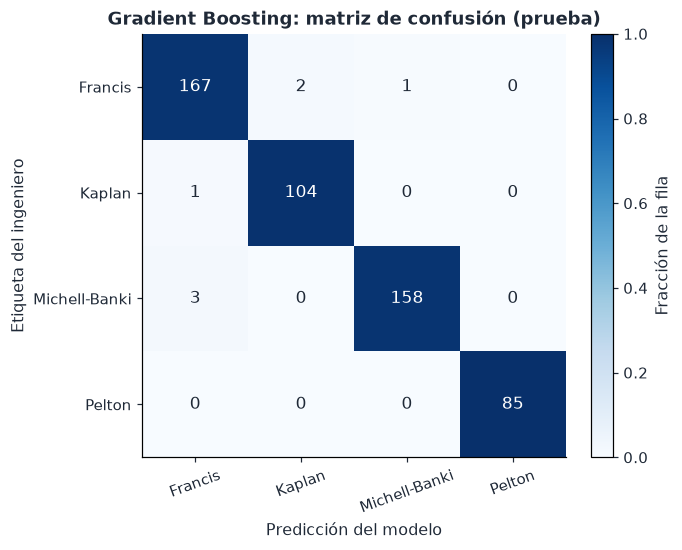

               precision    recall  f1-score   support

      Francis      0.977     0.982     0.979       170
       Kaplan      0.981     0.990     0.986       105
Michell-Banki      0.994     0.981     0.988       161
       Pelton      1.000     1.000     1.000        85

     accuracy                          0.987       521
    macro avg      0.988     0.989     0.988       521
 weighted avg      0.987     0.987     0.987       521



In [38]:
# ============================================================
# GRÁFICA 6 - MATRIZ DE CONFUSIÓN DEL GRADIENT BOOSTING Y REPORTE POR CLASE
# ============================================================

clases = list(gb_turb.classes_)                               # Orden de las clases.
p_gb = gb_turb.predict(X_te)                                  # Predicción del modelo final.
cm = confusion_matrix(y_te, p_gb, labels=clases)              # Matriz de confusión.
fig, ax = plt.subplots(figsize=(6, 5))                        # Figura.
im = ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)  # Colores por fracción de cada fila.
for i in range(len(clases)):                                  # Escribe el número de casos en cada celda.
    for j in range(len(clases)):                              # Columnas de la matriz.
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm[i].sum() / 2 else TINTA, fontsize=11)  # Número de casos.
ax.set(xticks=range(len(clases)), yticks=range(len(clases)), xticklabels=clases, yticklabels=clases,
       xlabel="Predicción del modelo", ylabel="Etiqueta del ingeniero", title="Gradient Boosting: matriz de confusión (prueba)")  # Rótulos.
ax.grid(False)                                                # Sin rejilla sobre la matriz.
plt.setp(ax.get_xticklabels(), rotation=20)                   # Inclina las etiquetas.
fig.colorbar(im, ax=ax, fraction=0.046, label="Fracción de la fila")  # Barra de color.
plt.show()                                                    # Dibuja.
print(classification_report(y_te, p_gb, digits=3))            # Precisión, exhaustividad y F1 de cada clase.

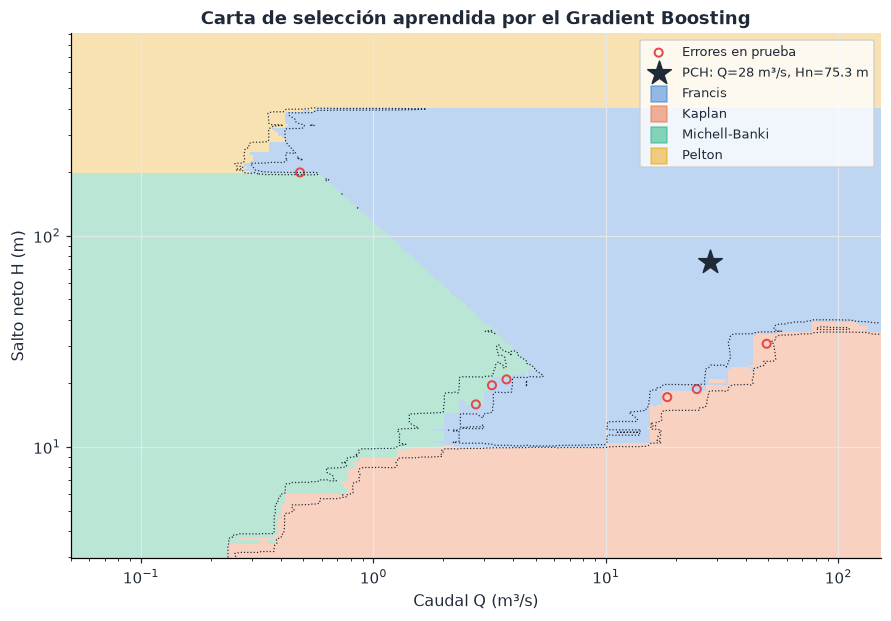

In [39]:
# ============================================================
# GRÁFICA 7 - MAPA DE DECISIÓN DEL MODELO EN EL PLANO CAUDAL-SALTO
# ============================================================

lq, lh = np.meshgrid(np.linspace(np.log10(0.05), np.log10(150), 260), np.linspace(np.log10(3), np.log10(900), 260))  # Malla log.
malla = pd.DataFrame({"log_Q": lq.ravel(), "log_H": lh.ravel()})  # Puntos de la malla.
malla["log_P"] = np.log10(rho * g * 10 ** malla.log_Q * 10 ** malla.log_H / 1e6)  # Potencia de cada punto.
proba = gb_turb.predict_proba(malla[X_cols])                  # Probabilidad de cada clase.
clase_idx = proba.argmax(axis=1).reshape(lq.shape)            # Clase ganadora.
conf = proba.max(axis=1).reshape(lq.shape)                    # Confianza de la clase ganadora.
fig, ax = plt.subplots(figsize=(9.5, 6.2))                    # Figura.
from matplotlib.colors import ListedColormap                  # Mapa de colores discreto.
ax.pcolormesh(10 ** lq, 10 ** lh, clase_idx, cmap=ListedColormap(PALETA[:len(clases)]), alpha=0.30, shading="auto")  # Regiones por clase.
ax.contour(10 ** lq, 10 ** lh, conf, levels=[0.8], colors=TINTA, linewidths=0.8, linestyles=":")  # Zonas de baja confianza (< 80 %).
err = X_te[p_gb != y_te]                                      # Puntos de prueba mal clasificados.
ax.scatter(10 ** err.log_Q, 10 ** err.log_H, s=28, facecolor="none", edgecolor=PALETA[7], lw=1.3, label="Errores en prueba")  # Errores.
ax.scatter(Q_diseno, H_neto, s=260, marker="*", color=TINTA, zorder=6, label=f"PCH: Q={Q_diseno:.0f} m³/s, Hn={H_neto:.1f} m")  # Proyecto.
for k, c in enumerate(clases):                                # Leyenda de colores de las clases.
    ax.scatter([], [], s=120, marker="s", color=PALETA[k], alpha=0.5, label=c)  # Marcador vacío solo para la leyenda.
ax.set(xscale="log", yscale="log", xlabel="Caudal Q (m³/s)", ylabel="Salto neto H (m)",
       title="Carta de selección aprendida por el Gradient Boosting")  # Rótulos.
ax.yaxis.set_minor_formatter(NullFormatter())                 # Limpia el eje log.
ax.legend(loc="upper right", fontsize=8.5, frameon=True)      # Leyenda.
plt.show()                                                    # Dibuja.

**Lectura del mapa.** El modelo reproduce la carta clásica (Kaplan en saltos bajos y caudales altos, Pelton en saltos altos, Francis en medio) pero **con la dependencia del caudal** que la carta por salto ignora: a 60 m con poco caudal la respuesta es Pelton y con mucho caudal es Francis. Las líneas punteadas encierran las zonas con confianza menor al 80 %; ahí se concentran los pocos errores y es donde la verificación física es imprescindible.

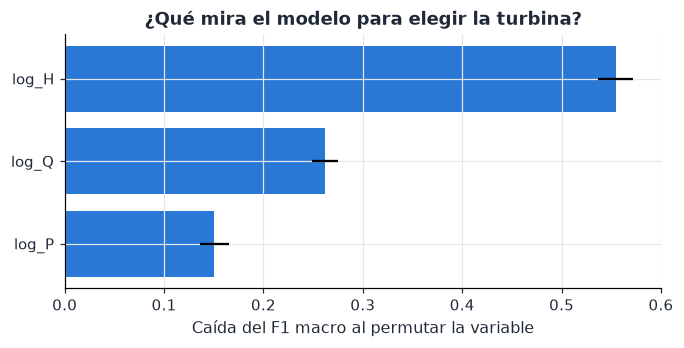

In [40]:
# ============================================================
# GRÁFICA 8 - IMPORTANCIA DE LAS VARIABLES (PERMUTACIÓN)
# ============================================================

imp = permutation_importance(gb_turb, X_te, y_te, n_repeats=15, random_state=semilla, scoring="f1_macro")  # Caída del F1 al barajar cada variable.
orden = np.argsort(imp.importances_mean)                      # Orden de menor a mayor.
fig, ax = plt.subplots(figsize=(7, 3))                        # Figura.
ax.barh(np.array(X_cols)[orden], imp.importances_mean[orden], xerr=imp.importances_std[orden], color=PALETA[0])  # Barras con desviación.
ax.set(xlabel="Caída del F1 macro al permutar la variable", title="¿Qué mira el modelo para elegir la turbina?")  # Rótulos.
plt.show()                                                    # Dibuja.

### 8.6 Predicción para la PCH y verificación física

El modelo entrega la probabilidad de cada tipo. Se recorren las clases de la más a la menos probable y se acepta la primera que **pase la verificación física** con el menor número de unidades. Así el ML ordena y la física decide.

In [41]:
# ============================================================
# PREDICCIÓN DEL GRADIENT BOOSTING PARA EL PROYECTO + VERIFICACIÓN FÍSICA
# ============================================================

x_pch = pd.DataFrame({"log_Q": [np.log10(Q_diseno)], "log_H": [np.log10(H_neto)],
                      "log_P": [np.log10(rho * g * Q_diseno * H_neto / 1e6)]})  # Punto del proyecto.
prob_pch = pd.Series(gb_turb.predict_proba(x_pch)[0], index=clases).sort_values(ascending=False)  # Probabilidades ordenadas.
display((prob_pch * 100).round(2).to_frame("Probabilidad [%]"))  # Muestra las probabilidades en porcentaje.
turbina, n_unid, verif = None, None, []                       # Resultado de la verificación.
for tipo in prob_pch.index:                                   # De la clase más probable a la menos probable.
    for k in range(1, n_unidades_max + 1):                    # Menor número de unidades primero.
        fz = factibilidad(tipo, H_neto, Q_diseno / k)         # Verificación física.
        verif.append({"tipo": tipo, "unidades": k, **{c: fz[c] for c in ("factible", "motivo", "n_rpm", "polos", "nQE")}})  # Registro.
        if fz["factible"] and turbina is None:                # Primera opción que pasa la física.
            turbina, n_unid = tipo, k                         # Guarda la turbina y el número de unidades.
    if turbina:                                               # Si ya se encontró, no se revisan más clases.
        break                                                 # Detiene la búsqueda.
print(f"Propuesta del ML: {prob_pch.index[0]} ({prob_pch.iloc[0]:.1%})  →  Verificada por la física: {turbina} con {n_unid} unidad(es)")  # Decisión.
pd.DataFrame(verif)                                           # Registro de la verificación.

,Probabilidad [%]
Francis,99.850
Kaplan,0.140
Michell-Banki,0.010
Pelton,0.000


Propuesta del ML: Francis (99.9%)  →  Verificada por la física: Francis con 1 unidad(es)


,tipo,unidades,factible,motivo,n_rpm,polos,nQE
0,Francis,1,True,OK,400.000,18,0.249
1,Francis,2,True,OK,600.000,12,0.264
2,Francis,3,True,OK,720.000,10,0.259


### 8.7 Ficha técnica de la turbina seleccionada

Dimensiones del rodete Francis con las correlaciones de De Siervo y De Leva (ESHA 2004).

Diámetro de salida del rodete:

$$D_3=84.5\,(0.31+2.488\,n_{QE})\,\frac{\sqrt{H}}{n}$$

Diámetro de entrada:

$$D_1=\left(0.4+\frac{0.095}{n_{QE}}\right)D_3$$

Diámetro de entrada a los álabes:

$$D_2=\frac{D_3}{0.96+0.3781\,n_{QE}}$$

Las curvas de eficiencia de catálogo se miden en un modelo reducido; el prototipo, más grande, es algo más eficiente. Corrección de Moody:

$$1-\eta_p=(1-\eta_m)\left(\frac{D_m}{D_p}\right)^{0.2}$$

In [42]:
# ============================================================
# FICHA TÉCNICA DE LA TURBINA
# ============================================================

Q_u = Q_diseno / n_unid                                       # Caudal por unidad (m³/s).
fz = factibilidad(turbina, H_neto, Q_u)                       # Datos de velocidad de la unidad seleccionada.
nq, n_rpm = fz["nQE"], fz["n_rpm"]                            # Velocidad específica y velocidad de giro.
D3 = 84.5 * (0.31 + 2.488 * nq) * np.sqrt(H_neto) / n_rpm     # Diámetro de salida del rodete (m).
D1 = (0.4 + 0.095 / nq) * D3                                  # Diámetro de entrada (m).
D2 = D3 / (0.96 + 0.3781 * nq) if nq >= 0.164 else D1         # Diámetro de entrada a los álabes (m).
Hs = altura_aspiracion(nq, H_neto)                            # Altura de aspiración admisible (m).
eta_nom = float(eta_turbina(turbina, 1.0))                    # Eficiencia a plena carga.
P_inst = rho * g * Q_diseno * H_neto * eta_nom * eta_g / 1e6  # Potencia instalada en bornes (MW).
marcas = cat[(cat["Unidades"] == n_unid) & (cat["Resultado"] == "APTA")]  # Fabricantes cuyo catálogo cubre la unidad.
ficha = pd.DataFrame({"Magnitud": ["Tipo de turbina", "Número de unidades", "Caudal por unidad", "Potencia por unidad",
                                   "Velocidad de giro", "Polos del generador (60 Hz)", "Velocidad específica n_QE",
                                   "Velocidad específica n_s (métrica)", "Diámetro de salida D3", "Diámetro de entrada D1",
                                   "Altura de aspiración Hs", "Eficiencia a plena carga", "Potencia instalada (bornes)",
                                   "Catálogos que cubren el punto"],
                      "Valor": [turbina, n_unid, f"{Q_u:.1f} m³/s", f"{fz['P_unidad_kW'] / 1000:.2f} MW", f"{n_rpm:.0f} rpm",
                                fz["polos"], f"{nq:.3f}", f"{fz['ns']:.0f}", f"{D3:.2f} m", f"{D1:.2f} m",
                                f"{Hs:.1f} m (rodete bajo el nivel de descarga)" if Hs < 0 else f"{Hs:.1f} m",
                                f"{eta_nom:.1%}", f"{P_inst:.2f} MW",
                                ", ".join(marcas["Fabricante"] + " " + marcas["Tipo"]) or "ninguno: consultar fabricante"]})
ficha                                                         # Muestra la ficha.

,Magnitud,Valor
0,Tipo de turbina,Francis
1,Número de unidades,1
2,Caudal por unidad,28.0 m³/s
3,Potencia por unidad,18.63 MW
4,Velocidad de giro,400 rpm
5,Polos del generador (60 Hz),18
6,Velocidad específica n_QE,0.249
7,Velocidad específica n_s (métrica),246
8,Diámetro de salida D3,1.70 m
9,Diámetro de entrada D1,1.33 m


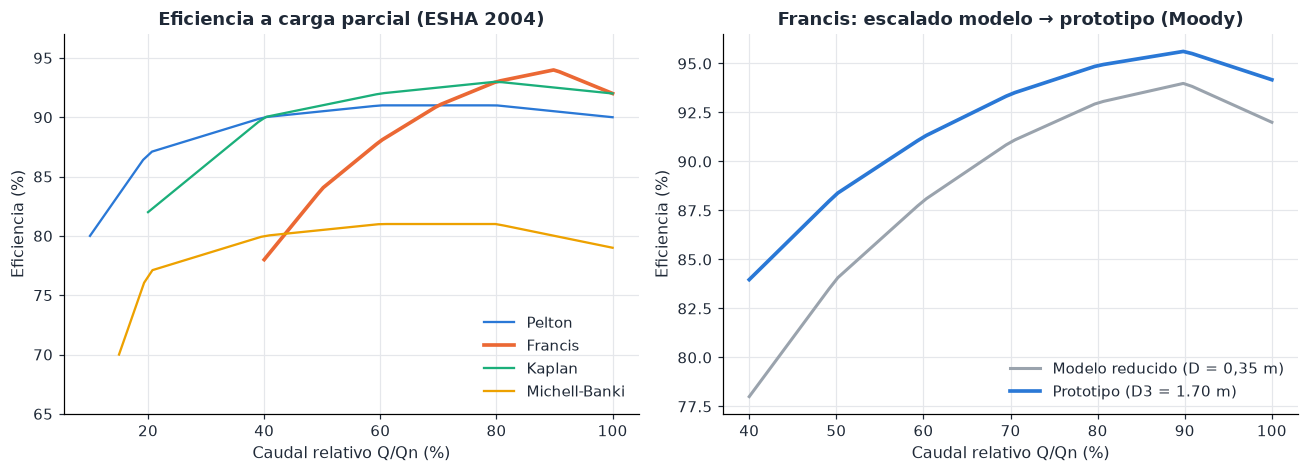

In [43]:
# ============================================================
# GRÁFICA 9 - EFICIENCIA A CARGA PARCIAL Y CORRECCIÓN DE MOODY
# ============================================================

fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))               # Dos paneles.
for k, (t, d) in enumerate(TURBINAS.items()):                 # Curva de cada tipo.
    qq = np.linspace(d["q_min"], 1.0, 60)                     # Desde el mínimo técnico hasta plena carga.
    ax[0].plot(qq * 100, eta_turbina(t, qq) * 100, lw=2.4 if t == turbina else 1.5, color=PALETA[k], label=t)  # Curva η(Q/Qn).
ax[0].set(xlabel="Caudal relativo Q/Qn (%)", ylabel="Eficiencia (%)", title="Eficiencia a carga parcial (ESHA 2004)", ylim=(65, 97))  # Rótulos.
ax[0].legend()                                                # Leyenda.
qq = np.linspace(TURBINAS[turbina]["q_min"], 1, 60)           # Malla de carga para la turbina elegida.
eta_m = eta_turbina(turbina, qq)                              # Eficiencia del modelo reducido.
eta_p = 1 - (1 - eta_m) * (0.35 / D3) ** 0.2                  # Eficiencia del prototipo (Moody, modelo de 0,35 m).
ax[1].plot(qq * 100, eta_m * 100, lw=2, color=GRIS, label="Modelo reducido (D = 0,35 m)")  # Curva de modelo.
ax[1].plot(qq * 100, eta_p * 100, lw=2.4, color=PALETA[0], label=f"Prototipo (D3 = {D3:.2f} m)")  # Curva escalada.
ax[1].set(xlabel="Caudal relativo Q/Qn (%)", ylabel="Eficiencia (%)", title=f"{turbina}: escalado modelo → prototipo (Moody)")  # Rótulos.
ax[1].legend()                                                # Leyenda.
fig.tight_layout()                                            # Ajusta márgenes.
plt.show()                                                    # Dibuja.

**Conclusión de la sección.** El *Gradient Boosting* propone la turbina y su respuesta coincide con la regla del ingeniero, con la carta de los fabricantes y con la verificación de velocidad específica y cavitación. La Francis de una unidad queda a una velocidad síncrona de catálogo y el rodete requiere sumergencia moderada. Para la ingeniería de detalle se recomienda pedir a WEG la curva de colina (*hill chart*) del rodete propuesto y confirmar $H_s$ con el nivel mínimo de descarga real.

---
# 9. Producción de energía

Como en la Parte C del Taller 1, la central se simula **día a día** sobre los 9.124 registros, ahora con la turbina seleccionada, su curva de eficiencia a carga parcial y la cadena eléctrica hasta la frontera comercial.

Caudal disponible (siempre se respeta el caudal ecológico):

$$Q_{disp}=\max\left(Q_{río}-Q_{eco},\ 0\right)$$

Caudal turbinado (si el caudal por unidad queda bajo el mínimo técnico $q_{min}$, la unidad se apaga):

$$Q_{turb}=\begin{cases}\min\left(Q_{disp},\ Q_d\right) & \text{si } Q_{disp}/Q_d\ge q_{min}\\[4pt] 0 & \text{en otro caso}\end{cases}$$

Potencia en bornes con el salto neto del día y la eficiencia a carga parcial:

$$P=\rho\,g\,Q_{turb}\,H_n(Q_{turb})\,\eta_t\!\left(\frac{Q_{turb}}{Q_d}\right)\eta_g$$

Energía neta comercializable ($D$ = disponibilidad):

$$E_{neta}=P\,\eta_{tr}\,(1-p_{\text{línea}})\,(1-a_{aux})\,D\cdot 24\ \text{h}$$

Factor de planta:

$$FP=\frac{E_{bruta\ anual}}{P_{inst}\cdot 8760\ \text{h}}$$

Con varias unidades se encienden solo las necesarias para no bajar del mínimo técnico de cada una.

In [44]:
# ============================================================
# SIMULACIÓN DIARIA DE LA OPERACIÓN
# ============================================================

def despacho(Q_disp, Qd, n_u, tipo):                          # Reparte el caudal disponible entre unidades iguales.
    Q = np.minimum(np.asarray(Q_disp, dtype=float), Qd)       # No se turbina más que el caudal de diseño.
    Qu = Qd / n_u                                             # Caudal nominal de cada unidad.
    k = np.clip(np.ceil(Q / Qu - 1e-9), 0, n_u)               # Unidades necesarias para no superar su nominal.
    for _ in range(n_u):                                      # Apaga unidades si cada una quedaría bajo el mínimo técnico.
        k = np.where((k > 1) & (Q / np.maximum(k, 1) < TURBINAS[tipo]["q_min"] * Qu), k - 1, k)  # Una unidad menos donde haga falta.
    q_rel = np.where(k > 0, Q / np.maximum(k, 1) / Qu, 0)     # Carga relativa de cada unidad encendida.
    eta = eta_turbina(tipo, np.minimum(q_rel, 1.0))           # Eficiencia de la turbina en ese punto.
    return np.where(eta > 0, np.minimum(Q, k * Qu), 0.0), eta # Caudal turbinado y eficiencia.

def simular(Qd=Q_diseno, D=D_sel, eps=eps_sel, K=K_total, n_u=n_unid, tipo=turbina, Q_rio=rio["Q_rio_m3s"].values):  # Simulación completa.
    Q_t, eta = despacho(np.maximum(Q_rio - Q_eco, 0), Qd, n_u, tipo)  # Despacho diario.
    h = hidraulica(Q_t, D, eps, K)                            # Hidráulica de cada día (V, pérdidas, salto neto).
    P = rho * g * Q_t * np.maximum(h["Hn"], 0) * eta * eta_g / 1e6  # Potencia en bornes (MW).
    E_neta = P * eta_tr * (1 - perdidas_linea) * (1 - autoconsumo) * disponibilidad * 24 * 1000  # Energía neta diaria (kWh).
    return pd.DataFrame({"fecha": rio["fecha"].values, "Q_rio": Q_rio, "Q_turb": Q_t, "eta_t": eta, "V": h["V"],
                         "hL": h["hL"], "Hn": h["Hn"], "P_MW": P, "E_bruta_kWh": P * 24 * 1000, "E_neta_kWh": E_neta})  # Tabla diaria.

sim = simular()                                               # Simula los 9.124 días con el diseño seleccionado.
anios = len(sim) / 365                                        # Número de años de la serie.
E_media = sim["E_neta_kWh"].sum() / anios                     # Energía neta media anual (kWh).
FP = sim["E_bruta_kWh"].sum() / anios / (P_inst * 8760 * 1000)  # Factor de planta.
remanente = sim["Q_rio"] - sim["Q_turb"]                      # Caudal que queda en el río.
op = pd.DataFrame({"Indicador": [                             # Tabla resumen de operación (estilo Taller 1, Parte C).
    "Días analizados", "Días sin operación", "Días a carga parcial", "Días a caudal de diseño",
    "Porcentaje de días generando", "Potencia media / máxima", "Energía neta media anual", "Energía firme (año más seco)",
    "Factor de planta", "Días con caudal remanente ≥ ecológico"],
    "Valor": [f"{len(sim):,}", f"{(sim.Q_turb == 0).sum():,}", f"{((sim.Q_turb > 0) & (sim.Q_turb < Q_diseno - 1e-6)).sum():,}",
              f"{(sim.Q_turb >= Q_diseno - 1e-6).sum():,}", f"{(sim.Q_turb > 0).mean():.1%}",
              f"{sim.P_MW.mean():.2f} / {sim.P_MW.max():.2f} MW", f"{E_media / 1e6:,.1f} GWh/año",
              f"{sim.E_neta_kWh.values[: int(anios) * 365].reshape(-1, 365).sum(1).min() / 1e6:,.1f} GWh/año",
              f"{FP:.1%}", f"{(remanente >= Q_eco - 1e-9).mean():.1%}"]})
op                                                            # Muestra la tabla.

,Indicador,Valor
0,Días analizados,"9,124"
1,Días sin operación,0
2,Días a carga parcial,"2,316"
3,Días a caudal de diseño,"6,808"
4,Porcentaje de días generando,100.0%
5,Potencia media / máxima,17.66 / 18.24 MW
6,Energía neta media anual,142.6 GWh/año
7,Energía firme (año más seco),113.8 GWh/año
8,Factor de planta,96.9%
9,Días con caudal remanente ≥ ecológico,100.0%


**Lectura de ingeniería.** El río casi siempre trae más que $Q_d + Q_{eco}$, por lo que la central trabaja a plena carga la mayor parte del año y el factor de planta es muy alto. Eso indica que 28 m³/s es un caudal de diseño **conservador** para este río: hay energía disponible que no se aprovecha. La sección 14 busca el caudal que maximiza el VAN sin pasar el límite de 20 MW de una planta menor.

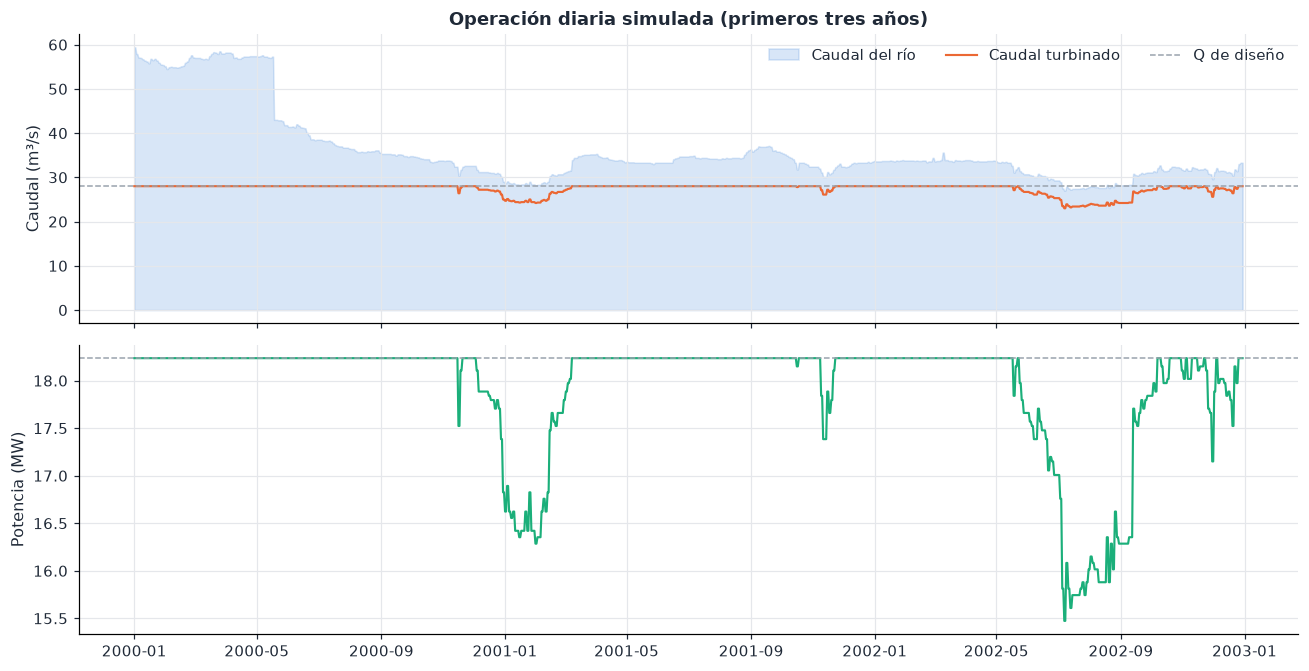

In [45]:
# ============================================================
# GRÁFICA 10 - CAUDAL DEL RÍO, CAUDAL TURBINADO Y POTENCIA (TRES AÑOS)
# ============================================================

v = sim.iloc[: 3 * 365]                                       # Ventana de tres años para que se distingan los días.
fig, ax = plt.subplots(2, 1, figsize=(12, 6.2), sharex=True)  # Dos paneles con el mismo eje de tiempo.
ax[0].fill_between(v.fecha, v.Q_rio, color=PALETA[0], alpha=0.18, label="Caudal del río")  # Caudal del río.
ax[0].plot(v.fecha, v.Q_turb, color=PALETA[1], lw=1.4, label="Caudal turbinado")  # Caudal turbinado.
ax[0].axhline(Q_diseno, color=GRIS, ls="--", lw=1, label="Q de diseño")  # Referencia.
ax[0].set(ylabel="Caudal (m³/s)", title="Operación diaria simulada (primeros tres años)")  # Rótulos.
ax[0].legend(ncol=3, loc="upper right")                       # Leyenda.
ax[1].plot(v.fecha, v.P_MW, color=PALETA[2], lw=1.4)          # Potencia diaria.
ax[1].axhline(P_inst, color=GRIS, ls="--", lw=1)              # Potencia instalada.
ax[1].set(ylabel="Potencia (MW)")                             # Rótulo.
fig.tight_layout()                                            # Ajusta márgenes.
plt.show()                                                    # Dibuja.

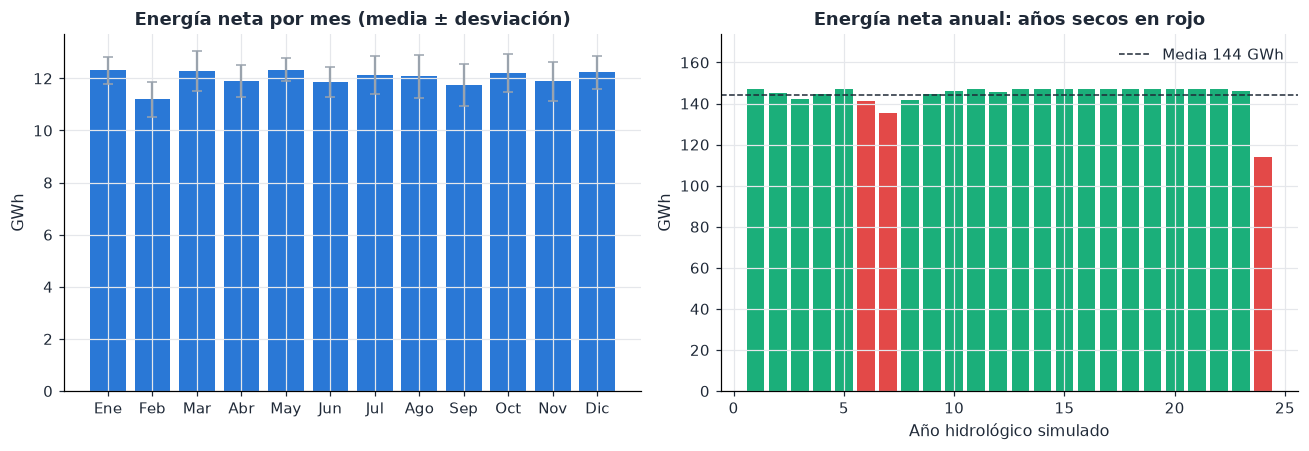

In [46]:
# ============================================================
# GRÁFICA 11 - ENERGÍA MENSUAL Y VARIABILIDAD ENTRE AÑOS
# ============================================================

n_a = int(anios)                                              # Años completos de 365 días.
bloque = sim.iloc[: n_a * 365].copy()                         # Recorta a años completos.
bloque["anio_h"] = np.repeat(np.arange(n_a), 365)             # Año hidrológico sintético (bloques de 365 días).
bloque["mes"] = bloque["fecha"].dt.month                      # Mes calendario (según el calendario supuesto).
E_mat = bloque.pivot_table(index="anio_h", columns="mes", values="E_neta_kWh", aggfunc="sum").values  # Matriz E[año, mes] (kWh).
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))               # Dos paneles.
meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]  # Nombres de los meses.
ax[0].bar(meses, E_mat.mean(0) / 1e6, color=PALETA[0], yerr=E_mat.std(0) / 1e6, capsize=3, error_kw={"ecolor": GRIS})  # Media ± desviación.
ax[0].set(ylabel="GWh", title="Energía neta por mes (media ± desviación)")  # Rótulos.
ea = E_mat.sum(1) / 1e6                                       # Energía de cada año (GWh).
ax[1].bar(np.arange(1, n_a + 1), ea, color=np.where(ea < np.percentile(ea, 10), PALETA[7], PALETA[2]))  # Años secos en rojo.
ax[1].axhline(ea.mean(), color=TINTA, ls="--", lw=1, label=f"Media {ea.mean():.0f} GWh")  # Media.
ax[1].set(xlabel="Año hidrológico simulado", ylabel="GWh", title="Energía neta anual: años secos en rojo")  # Rótulos.
ax[1].set_ylim(0, ea.max() * 1.18)                            # Deja espacio para la leyenda.
ax[1].legend(loc="upper right")                               # Leyenda.
fig.tight_layout()                                            # Ajusta márgenes.
plt.show()                                                    # Dibuja.

---
# 10. Mercado eléctrico e ingresos (XM)

En el mercado mayorista colombiano una PCH de 10 a 20 MW puede vender su energía **en bolsa** (precio horario, muy volátil por la hidrología y El Niño) o mediante **contratos bilaterales** a precio pactado (CREG 086 de 1996). El ingreso anual es, como en la clase 14:

$$ I_a = E_a \cdot P_e = \sum_{m=1}^{12} E_m\,P_m $$

Se construyen cinco escenarios con supuestos explícitos. Los precios son medianas o percentiles de los **datos oficiales de XM** en pesos constantes de 2026:

| Escenario | Hidrología | Precio |
|---|---|---|
| 1. Venta en bolsa | año medio | mediana de bolsa de cada mes calendario |
| 2. Contrato bilateral | año medio | promedio SICEP de los últimos 12 meses publicados |
| 3. Conservador | año seco (P10 de energía) | percentil 10 de bolsa |
| 4. **Base** | año medio | 70 % contrato + 30 % bolsa |
| 5. Optimista | año húmedo (P90 de energía) | percentil 75 de bolsa |

**Por qué el escenario base es una cartera.** Un financiador no presta sobre ingresos 100 % de bolsa; las PCH colombianas suelen contratar la mayor parte de su energía firme y vender el resto en bolsa. El conservador combina año seco con bolsa baja, que en Colombia es poco probable (años secos suelen traer precios altos): es una prueba de estrés deliberadamente dura.

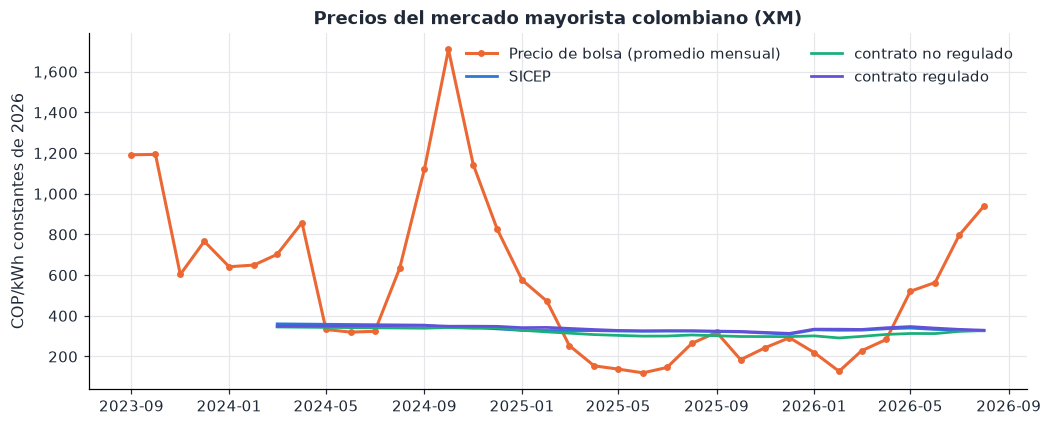

In [47]:
# ============================================================
# GRÁFICA 12 - PRECIOS OFICIALES DE XM EN PESOS CONSTANTES
# ============================================================

fig, ax = plt.subplots(figsize=(11, 4.2))                     # Figura.
ax.plot(bolsa.index, bolsa.values, "o-", ms=3.5, lw=2, color=PALETA[1], label="Precio de bolsa (promedio mensual)")  # Bolsa.
for k, v_ in enumerate(["SICEP", "contrato_no_regulado", "contrato_regulado"]):  # Precios de contratos.
    ax.plot(serie[v_].index, serie[v_].values, lw=1.8, color=PALETA[[0, 2, 6][k]], label=v_.replace("_", " "))  # Serie de contrato.
ax.yaxis.set_major_formatter(miles)                           # Separador de miles.
ax.set(ylabel=f"COP/kWh constantes de {anio_base}", title="Precios del mercado mayorista colombiano (XM)")  # Rótulos.
ax.legend(ncol=2)                                             # Leyenda.
plt.show()                                                    # Dibuja.

In [48]:
# ============================================================
# ESCENARIOS DE COMERCIALIZACIÓN E INGRESOS
# ============================================================

perfil_bolsa = bolsa.groupby(bolsa.index.month).median().reindex(range(1, 13)).fillna(bolsa.median()).values  # Mediana de bolsa por mes.
precio_contrato = float(serie["SICEP"].sort_index().iloc[-12:].mean())  # Contrato: promedio de los últimos 12 meses SICEP.
e_anual = E_mat.sum(1)                                        # Energía de cada año simulado (kWh).
i_seco = int(np.argsort(e_anual)[max(int(0.1 * n_a) - 1, 0)]) # Año ≈ P10 de energía (seco).
i_hum = int(np.argsort(e_anual)[int(np.ceil(0.9 * n_a)) - 1]) # Año ≈ P90 de energía (húmedo).
E_med = E_mat.mean(0)                                         # Energía media de cada mes (kWh).
ESC = {                                                       # Escenario: (precio de cada mes, energía de cada mes).
    "1. Venta en bolsa": (perfil_bolsa, E_med),
    "2. Contrato bilateral": (np.full(12, precio_contrato), E_med),
    "3. Conservador": (np.full(12, bolsa.quantile(0.10)), E_mat[i_seco]),
    "4. Base": (frac_contrato * precio_contrato + (1 - frac_contrato) * perfil_bolsa, E_med),
    "5. Optimista": (np.full(12, bolsa.quantile(0.75)), E_mat[i_hum]),
}
tabla_esc = pd.DataFrame([{"Escenario": k, "Energía [GWh/año]": e.sum() / 1e6, "Precio medio [COP/kWh]": (p * e).sum() / e.sum(),
                           "Ingreso anual [MCOP]": (p * e).sum() / 1e6} for k, (p, e) in ESC.items()])  # Tabla de escenarios.
print(f"Precio de contrato adoptado: {precio_contrato:,.1f} COP/kWh (SICEP, constantes {anio_base})")  # Supuesto clave.
tabla_esc                                                     # Muestra la tabla.

Precio de contrato adoptado: 327.8 COP/kWh (SICEP, constantes 2026)


,Escenario,Energía [GWh/año],Precio medio [COP/kWh],Ingreso anual [MCOP]
0,1. Venta en bolsa,144.169,573.005,"82,609.477"
1,2. Contrato bilateral,144.169,327.848,"47,265.565"
2,3. Conservador,135.502,149.994,"20,324.604"
3,4. Base,144.169,401.395,"57,868.739"
4,5. Optimista,147.252,773.416,"113,887.381"


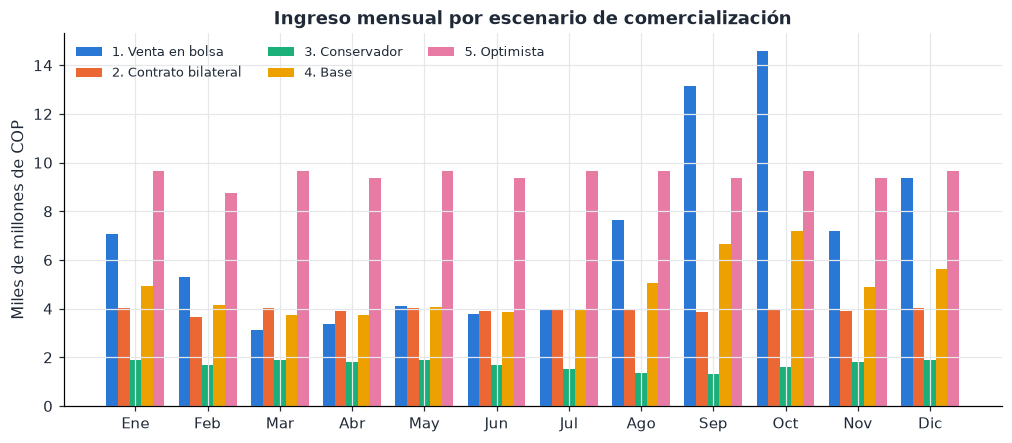

In [49]:
# ============================================================
# GRÁFICA 13 - INGRESO MENSUAL POR ESCENARIO
# ============================================================

fig, ax = plt.subplots(figsize=(11, 4.4))                     # Figura.
ancho = 0.16                                                  # Ancho de cada barra.
for k, (nombre, (p, e)) in enumerate(ESC.items()):            # Un grupo de barras por escenario.
    ax.bar(np.arange(12) + (k - 2) * ancho, p * e / 1e9, ancho, color=PALETA[k], label=nombre)  # Ingreso mensual (miles de millones).
ax.set_xticks(range(12), meses)                               # Meses en el eje x.
ax.set(ylabel="Miles de millones de COP", title="Ingreso mensual por escenario de comercialización")  # Rótulos.
ax.legend(ncol=3, fontsize=8.5)                               # Leyenda.
plt.show()                                                    # Dibuja.

---
# 11. CAPEX y OPEX (metodología de la clase 14)

### 11.1 Estructura de costos

Inversión inicial (clase 14): equipos, obras civiles e ingeniería:

$$CAPEX=C_{eq}+C_{ob}+C_{ing}$$

Costos de operación anuales: operación, mantenimiento y administración:

$$OPEX_a=C_{op}+C_{mant}+C_{adm}$$

| Componente | Incluye |
|---|---|
| $C_{eq}$ equipos | turbina-generador, válvulas, tubería de presión, compuertas, subestación y línea corta |
| $C_{ob}$ obras civiles | bocatoma, desarenador, conducción, tanque de carga, casa de máquinas, canal de descarga, vías |
| $C_{ing}$ ingeniería | estudios (hidrología, topografía, geología, ambiente) y diseños |
| $C_{op}$, $C_{mant}$, $C_{adm}$ | personal de operación; mantenimiento preventivo y correctivo, repuestos; insumos administrativos y seguros |

### 11.2 Referencias de costo por kW instalado

| Fuente | Valor | Comentario |
|---|---|---|
| Rango PCH (clase 14) | 900 – 3.000 USD/kW | depende del sitio, el salto y el acceso |
| OLADE, Latinoamérica | 50 kW: 4.000 · 100 kW: 1.750 · 1.000 kW: 1.250 USD/kW (salto medio) | solo hasta 1 MW |
| ESHA (curva europea) | 500 kW: 2.500 · 4.000 kW: 1.400 · 10.000 kW: 1.100 USD/kW | economía de escala |
| **UPME, Plan de Expansión 2025–2039** | **3.009 USD/kW (hidro menor)** | **referencia colombiana adoptada** |

Ajuste potencial de la curva ESHA, para extrapolarla a la potencia del proyecto:

$$c=A\,P^{\,b}\quad\Rightarrow\quad \ln c=\ln A+b\,\ln P$$

**Por qué se adopta la UPME.** Es la única referencia colombiana, reciente y específica para hidro menor; la curva ESHA refleja costos europeos de otra década y OLADE no cubre centrales mayores a 1 MW. Las tres se grafican para mostrar la incertidumbre, que se lleva al análisis de sensibilidad (±20 %).

**Distribución porcentual en Colombia** (clase 14, PCH de 10 MW, UPME): obras civiles 32,5 %, equipos 55,1 %, transmisión 1,0 %, estudios 0,9 % y diseños 10,6 %. La tubería de presión, que es parte de los equipos, se calcula explícitamente con su masa para que el costo responda al diámetro y al material escogidos.

CAPEX de referencia:

$$CAPEX_{ref}=P_{kW}\cdot c_{UPME}$$

Masa y costo de la tubería (espesor $e$ de la sección 7, acero de 7,85 t/m³, factor 2 por fabricación y montaje y $f_{mat}$ el costo relativo del material):

$$m=\pi\,(D+e)\,e\,L\cdot 7.85,\qquad C_{tub}=m\cdot p_{acero}\cdot 2\cdot f_{mat}$$

Componentes del CAPEX ($f_{tub}$ = fracción que la referencia asigna a la tubería, que se reemplaza por el valor calculado):

$$C_{eq}=CAPEX_{ref}\,(0.551+0.010-f_{tub})+C_{tub},\qquad C_{ob}=0.325\,CAPEX_{ref},\qquad C_{ing}=(0.009+0.106)\,CAPEX_{ref}$$

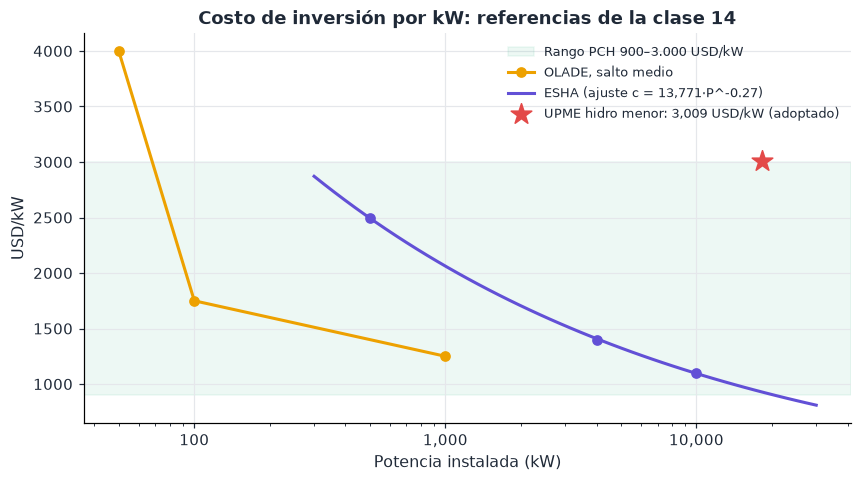

ESHA extrapolada a 18,236 kW: 928 USD/kW  |  UPME: 3,009 USD/kW


In [50]:
# GRÁFICA 14 - REFERENCIAS DE COSTO POR kW INSTALADO
P_kW = P_inst * 1000                                          # Potencia instalada (kW).
esha_P, esha_c = np.array([500, 4000, 10000]), np.array([2500, 1400, 1100])  # Curva ESHA (kW, USD/kW).
b_esha, a_esha = np.polyfit(np.log(esha_P), np.log(esha_c), 1)  # Ajuste potencial c = A·P^b.
c_esha = np.exp(a_esha) * P_kW ** b_esha                      # Extrapolación ESHA a la potencia del proyecto.
olade = pd.DataFrame({"P_kW": [50, 100, 1000], "Baja (<20 m)": [4800, 2000, 1500], "Media (20–100 m)": [4000, 1750, 1250],
                      "Alta (>100 m)": [3200, 1500, 1000]})   # Tabla OLADE (USD/kW).
fig, ax = plt.subplots()                                      # Figura.
ax.axhspan(900, 3000, color=PALETA[2], alpha=0.08, label="Rango PCH 900–3.000 USD/kW")  # Rango de la clase.
ax.plot(olade.P_kW, olade["Media (20–100 m)"], "o-", color=PALETA[3], lw=2, label="OLADE, salto medio")  # OLADE.
pp = np.logspace(np.log10(300), np.log10(30000), 50)          # Malla de potencias.
ax.plot(pp, np.exp(a_esha) * pp ** b_esha, color=PALETA[6], lw=2, label=f"ESHA (ajuste c = {np.exp(a_esha):,.0f}·P^{b_esha:.2f})")  # ESHA.
ax.scatter(esha_P, esha_c, color=PALETA[6], zorder=5)         # Puntos ESHA.
ax.scatter(P_kW, c_ref_usd_kw, s=200, marker="*", color=PALETA[7], zorder=6, label=f"UPME hidro menor: {c_ref_usd_kw:,.0f} USD/kW (adoptado)")  # UPME.
ax.set(xscale="log", xlabel="Potencia instalada (kW)", ylabel="USD/kW", title="Costo de inversión por kW: referencias de la clase 14")  # Rótulos.
ax.xaxis.set_major_formatter(miles)                           # Separador de miles.
ax.legend(fontsize=8.5)                                       # Leyenda.
plt.show()                                                    # Dibuja.
print(f"ESHA extrapolada a {P_kW:,.0f} kW: {c_esha:,.0f} USD/kW  |  UPME: {c_ref_usd_kw:,.0f} USD/kW")  # Comparación.

In [51]:
# CAPEX = Ceq + Cob + Cing CON LA DISTRIBUCIÓN UPME Y LA TUBERÍA CALCULADA
UPME_PCT = {"obras": 0.325, "equipos": 0.551, "transmision": 0.010, "estudios": 0.009, "disenos": 0.106}  # Distribución UPME (clase 14).
F_TUB_REF = 0.12                                              # Fracción del CAPEX que la referencia asigna a la tubería de presión (SUPUESTO, ESHA 10–15 %).
COSTO_REL = {"STEEL_WELDED": 1.0, "GRP_FLOWTITE": 0.85, "PE100_AGRU": 1.0, "DI_PAM": 1.10, "PVC": 0.60}  # Costo instalado relativo al acero (SUPUESTO).

def costo_tuberia_usd(D, material, L=L, H=H_bruto):           # Costo de la tubería por su masa de acero equivalente.
    e = max(rho * g * H * 1.3 / 1e6 * D * 1000 / (2 * sigma_adm * E_j) + e_corr, (D * 1000 + 508) / 400) / 1000  # Espesor (m).
    masa_t = np.pi * (D + e) * e * L * 7.85                   # Masa de acero (t).
    return masa_t * precio_acero * 2.0 * COSTO_REL.get(material, 1.0)  # Material × 2 (fabricación y montaje) × factor del material.

def capex_usd(P_MW, D, material, n_u=1, c_kw=c_ref_usd_kw):   # Desglose del CAPEX en USD.
    base = P_MW * 1000 * c_kw                                 # CAPEX de referencia (USD).
    c_tub = costo_tuberia_usd(D, material)                    # Tubería calculada.
    f_u = {1: 1.00, 2: 1.15, 3: 1.25}[n_u]                    # Más unidades encarecen los equipos (SUPUESTO).
    C_eq = base * (UPME_PCT["equipos"] + UPME_PCT["transmision"] - F_TUB_REF) * f_u + c_tub  # Equipos + transmisión + tubería.
    C_ob = base * UPME_PCT["obras"]                           # Obras civiles.
    C_ing = base * (UPME_PCT["estudios"] + UPME_PCT["disenos"])  # Estudios y diseños.
    return {"C_eq": C_eq, "C_ob": C_ob, "C_ing": C_ing, "tuberia": c_tub, "total": C_eq + C_ob + C_ing}  # Resultado.

cx = capex_usd(P_inst, D_sel, material_id, n_unid)            # CAPEX del diseño seleccionado.
CAPEX = cx["total"] * TRM                                     # CAPEX en pesos (COP).
tabla_capex = pd.DataFrame({                                  # Tabla del CAPEX.
    "Componente": ["C_eq  Equipos electromecánicos y transmisión", "      de ellos: tubería de presión (calculada)",
                   "C_ob  Obras civiles", "C_ing Ingeniería: estudios y diseños", "CAPEX TOTAL"],
    "USD": [cx["C_eq"], cx["tuberia"], cx["C_ob"], cx["C_ing"], cx["total"]]})
tabla_capex["Millones de COP"] = tabla_capex["USD"] * TRM / 1e6  # Conversión a COP.
tabla_capex["% del CAPEX"] = tabla_capex["USD"] / cx["total"] * 100  # Participación.
print(f"CAPEX = {cx['total'] / 1e6:,.2f} MUSD = {CAPEX / 1e9:,.1f} mil millones de COP  →  {cx['total'] / P_kW:,.0f} USD/kW")  # Resultado.
tabla_capex                                                   # Muestra la tabla.

CAPEX = 52.14 MUSD = 171.9 mil millones de COP  →  2,859 USD/kW


,Componente,USD,Millones de COP,% del CAPEX
0,C_eq Equipos electromecánicos y transmisión,"27,999,679.607","92,316.904",53.697
1,de ellos: tubería de presión (calculada),"3,800,483.829","12,530.461",7.288
2,C_ob Obras civiles,"17,833,874.440","58,799.532",34.201
3,C_ing Ingeniería: estudios y diseños,"6,310,447.879","20,805.988",12.102
4,CAPEX TOTAL,"52,144,001.925","171,922.424",100.000


### 11.3 Cronograma de actividades e inversión

Se adopta una construcción de **tres periodos (años)**. Cada actividad del cronograma de la clase 14 toma una parte de $C_{eq}$, $C_{ob}$ o $C_{ing}$ y se reparte en el tiempo según la secuencia lógica de una obra hidroeléctrica: primero estudios, tierras y excavaciones; luego obras y compra de equipos; al final transporte, montaje y puesta en marcha.

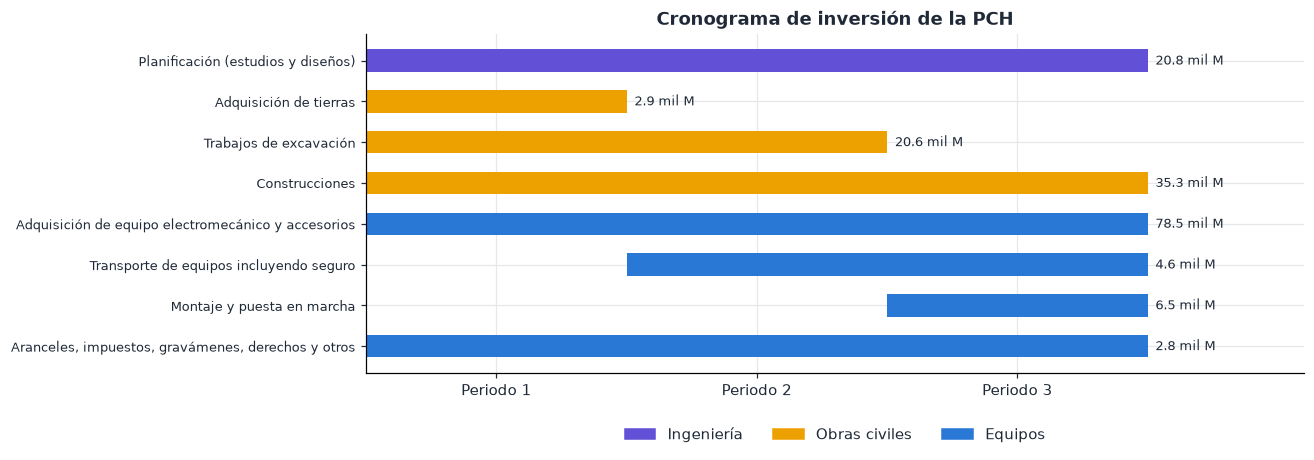

,Periodo 1,Periodo 2,Periodo 3,Total
Actividad,,,,
Planificación (estudios y diseños),14564,4161,2081,20806
Adquisición de tierras,2940,0,0,2940
Trabajos de excavación,10290,10290,0,20580
Construcciones,7056,17640,10584,35280
Adquisición de equipo electromecánico y accesorios,7847,39235,31388,78469
Transporte de equipos incluyendo seguro,0,2308,2308,4616
Montaje y puesta en marcha,0,0,6462,6462
"Aranceles, impuestos, gravámenes, derechos y otros",277,1385,1108,2770
Total gastos de inversión,42974,75018,53930,171922


In [52]:
# ============================================================
# CRONOGRAMA DE ACTIVIDADES (CLASE 14) Y DISTRIBUCIÓN DE LA INVERSIÓN POR PERIODO
# ============================================================

crono_def = [                                                 # Actividad, componente, fracción del componente, reparto en los periodos 1-2-3.
    ("Planificación (estudios y diseños)", "C_ing", 1.00, (0.70, 0.20, 0.10)),
    ("Adquisición de tierras", "C_ob", 0.05, (1.00, 0.00, 0.00)),
    ("Trabajos de excavación", "C_ob", 0.35, (0.50, 0.50, 0.00)),
    ("Construcciones", "C_ob", 0.60, (0.20, 0.50, 0.30)),
    ("Adquisición de equipo electromecánico y accesorios", "C_eq", 0.85, (0.10, 0.50, 0.40)),
    ("Transporte de equipos incluyendo seguro", "C_eq", 0.05, (0.00, 0.50, 0.50)),
    ("Montaje y puesta en marcha", "C_eq", 0.07, (0.00, 0.00, 1.00)),
    ("Aranceles, impuestos, gravámenes, derechos y otros", "C_eq", 0.03, (0.10, 0.50, 0.40)),
]
crono = pd.DataFrame([[a, *(cx[c] * f * np.array(rep) * TRM / 1e6)] for a, c, f, rep in crono_def],
                     columns=["Actividad", "Periodo 1", "Periodo 2", "Periodo 3"])  # Millones de COP por periodo.
crono["Total"] = crono[["Periodo 1", "Periodo 2", "Periodo 3"]].sum(axis=1)  # Total por actividad.
crono.loc[len(crono)] = ["Total gastos de inversión", *crono.iloc[:, 1:].sum().values]  # Fila total (debe igualar el CAPEX).
assert abs(crono["Total"].iloc[-1] - CAPEX / 1e6) < 1, "El cronograma no suma el CAPEX"  # Control de consistencia.

fig, ax = plt.subplots(figsize=(11, 4))                       # Diagrama de Gantt.
for k, (a, c, f, rep) in enumerate(crono_def):                # Una barra por actividad.
    ini = next(i for i, r in enumerate(rep) if r > 0)         # Primer periodo con gasto.
    fin = max(i for i, r in enumerate(rep) if r > 0) + 1      # Último periodo con gasto.
    ax.barh(k, fin - ini, left=ini, color=PALETA[{"C_ing": 6, "C_ob": 3, "C_eq": 0}[c]], height=0.55)  # Barra por componente.
    ax.text(fin + 0.03, k, f"{crono['Total'].iloc[k] / 1e3:,.1f} mil M", va="center", fontsize=8.5)  # Monto total.
ax.set_yticks(range(len(crono_def)), [a for a, *_ in crono_def], fontsize=8.5)  # Nombres de las actividades.
ax.invert_yaxis()                                             # Primera actividad arriba.
ax.set_xticks([0.5, 1.5, 2.5], ["Periodo 1", "Periodo 2", "Periodo 3"])  # Periodos en el eje x.
ax.set(xlim=(0, 3.6), title="Cronograma de inversión de la PCH")  # Rótulos.
from matplotlib.patches import Patch                          # Rectángulos de color para la leyenda.
ax.set_axisbelow(True)                                        # La rejilla queda detrás de las barras.
ax.legend(handles=[Patch(color=PALETA[k], label=c) for c, k in (("Ingeniería", 6), ("Obras civiles", 3), ("Equipos", 0))],
          loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)  # Leyenda por componente, bajo el gráfico.
plt.show()                                                    # Dibuja.
crono.set_index("Actividad").round(0).astype("int64")         # Tabla del cronograma en millones de COP.

In [53]:
# ============================================================
# COSTOS OPERATIVOS ANUALES (CLASE 14)
# ============================================================

C_op, C_mant, C_adm = f_cop * CAPEX, f_mant * CAPEX, f_adm * CAPEX  # Operación, mantenimiento y administración.
OPEX = C_op + C_mant + C_adm                                  # OPEX anual (COP).
p_base, e_base = ESC["4. Base"]                               # Precio y energía mensuales del escenario base.
I_base = float((p_base * e_base).sum())                       # Ingreso anual del escenario base (COP).
transf = ley99 * I_base if P_inst > 10 else 0.0               # Transferencias Ley 99/1993 (solo plantas > 10 MW).
depreciacion = CAPEX / vida_util                              # Depreciación anual en línea recta, valor residual cero (clase 14).
tabla_opex = pd.DataFrame({"Concepto": [
    f"Costos de operación anual ({f_cop:.0%} del costo total de la planta)",
    f"Reparación y mantenimiento anual ({f_mant:.0%} del costo total)",
    f"Insumos para administración anual ({f_adm:.2%} del costo total)",
    "Total OPEX anual (suma de los tres conceptos)",
    f"Transferencias Ley 99 de 1993 ({ley99:.0%} de las ventas, planta > 10 MW)",
    "Total de egresos anuales del proyecto",
    "Depreciación anual (línea recta, valor residual cero)"],
    "Valor [millones COP]": np.array([C_op, C_mant, C_adm, OPEX, transf, OPEX + transf, depreciacion]) / 1e6})
tabla_opex                                                    # Muestra la tabla.

,Concepto,Valor [millones COP]
0,Costos de operación anual (2% del costo total de la planta),"3,438.448"
1,Reparación y mantenimiento anual (1% del costo total),"1,719.224"
2,Insumos para administración anual (0.56% del costo total),962.766
3,Total OPEX anual (suma de los tres conceptos),"6,120.438"
4,"Transferencias Ley 99 de 1993 (6% de las ventas, planta > 10 MW)","3,472.124"
5,Total de egresos anuales del proyecto,"9,592.563"
6,"Depreciación anual (línea recta, valor residual cero)","5,730.747"


---
# 12. Evaluación económica

Se sigue la metodología de la clase 14: **pesos constantes**, recursos propios (sin intereses de deuda), **valor residual cero**, inversión en el año 0 y depreciación constante.

Ingresos anuales:

$$I_a=E_a\cdot P_e$$

Flujo de caja anual:

$$FC_t=I_t-OPEX_t\qquad (t=1,2,\dots,n)$$

Valor actual neto:

$$VAN=-CAPEX+\sum_{t=1}^{n}\frac{FC_t}{(1+i)^t}$$

Tasa interna de retorno:

$$0=-CAPEX+\sum_{t=1}^{n}\frac{FC_t}{(1+TIR)^t}$$

Periodo estático de amortización:

$$PB=\frac{C_{inv}}{FC_{anual}}$$

Periodo dinámico (con flujos descontados):

$$PB_{din}=t+\frac{CAPEX_{no\ rec}}{FC_{t+1}/(1+i)^{t+1}}$$

Relación beneficio/costo:

$$\frac{B}{C}=\frac{V_A(\text{Beneficios})}{V_A(\text{Costos})}$$

Costo total presente:

$$C_T=C_{inv}+\sum_{t=1}^{n}\frac{C_{op,t}}{(1+i)^t}$$

Anualidad de gastos:

$$A=C_{inv}\,\frac{i(1+i)^n}{(1+i)^n-1}+C_{op}$$

Costo nivelado de la energía, que se compara directamente con el precio de venta:

$$LCOE=\frac{A}{E_a}$$

**Criterios de rentabilidad:** $VAN > 0$, $TIR > i$ y $B/C > 1$.

La tabla de evaluación replica las columnas de la clase: *Energía, Venta, Egresos, Retornos brutos, Depreciación, Utilidades, Inversión y Amortización* (recuperación acumulada de la inversión).

In [54]:
# TABLA DE EVALUACIÓN ECONÓMICA DEL PROYECTO (AÑOS 0 A n)
def tabla_evaluacion(E_a, I_a, capex, egresos, n=vida_util):  # Construye la tabla de la clase 14.
    t = np.arange(0, n + 1)                                   # Años 0 ... n.
    op = t >= 1                                               # Años de operación.
    df = pd.DataFrame({"Año": t,
                       "Energía [MWh/año]": np.where(op, E_a / 1000, 0),  # Energía vendida.
                       "Venta de energía": np.where(op, I_a, 0),  # Ingresos por venta.
                       "Egresos anuales": np.where(op, egresos, 0),  # OPEX + transferencias.
                       "Retornos brutos": np.where(op, I_a, 0),  # Ingresos totales del proyecto (clase 14).
                       "Depreciación": np.where(op, capex / n, 0),  # Línea recta.
                       "Inversión": np.where(t == 0, capex, 0)})  # Desembolso en el año 0.
    df["Utilidades"] = df["Retornos brutos"] - df["Egresos anuales"] - df["Depreciación"]  # Retornos − egresos − depreciación.
    df["Flujo de caja"] = df["Retornos brutos"] - df["Egresos anuales"] - df["Inversión"]  # FC_t = I_t − OPEX_t (año 0: −CAPEX).
    df["Amortización"] = df["Flujo de caja"].cumsum()         # Recuperación acumulada de la inversión.
    return df                                                 # Tabla completa.

def indicadores(df, i=i_desc):                                # VAN, TIR, B/C, PB, C_T, A y LCOE.
    t, fc = df["Año"].values, df["Flujo de caja"].values      # Años y flujos.
    fd = (1 + i) ** -t                                        # Factor de descuento.
    van = float((fc * fd).sum())                              # Valor actual neto.
    try:                                                      # La TIR existe si el VAN cambia de signo.
        tir = brentq(lambda r: (fc * (1 + r) ** -t).sum(), -0.9, 3.0)  # Raíz del VAN.
    except ValueError:                                        # Sin cambio de signo.
        tir = np.nan                                          # TIR no definida.
    capex, n = df["Inversión"].sum(), t.max()                 # Inversión y vida útil.
    egr = df["Egresos anuales"].values                        # Egresos anuales.
    va_ben = float((df["Retornos brutos"].values * fd).sum()) # Valor actual de los beneficios.
    va_cos = capex + float((egr * fd).sum())                  # Valor actual de los costos.
    fc_op = df["Flujo de caja"].values[1:]                    # Flujos de operación.
    acum_d = np.cumsum(fc * fd)                               # Flujo descontado acumulado.
    k = np.argmax(acum_d >= 0) if (acum_d >= 0).any() else None  # Primer año con recuperación descontada.
    pb_din = (k - 1 + -acum_d[k - 1] / (acum_d[k] - acum_d[k - 1])) if k else np.nan  # Interpolación lineal.
    crf = i * (1 + i) ** n / ((1 + i) ** n - 1)               # Factor de recuperación de capital.
    A = capex * crf + egr[1:].mean()                          # Anualidad de gastos (COP/año).
    return {"VAN [MCOP]": van / 1e6, "TIR": tir, "B/C": va_ben / va_cos, "PB estático [años]": capex / fc_op.mean(),
            "PB dinámico [años]": pb_din, "C_T [MCOP]": va_cos / 1e6, "Anualidad A [MCOP/año]": A / 1e6,
            "LCOE [COP/kWh]": A / (df["Energía [MWh/año]"].values[1:].mean() * 1000)}  # Diccionario de indicadores.

ev = tabla_evaluacion(e_base.sum(), I_base, CAPEX, OPEX + transf)  # Tabla del escenario base.
ind_base = indicadores(ev)                                    # Indicadores del escenario base.
cols_m = [c for c in ev.columns if c not in ("Año", "Energía [MWh/año]")]  # Columnas monetarias.
vista = ev.copy()                                             # Copia para mostrar en millones de COP.
vista[cols_m] = vista[cols_m] / 1e6                           # Millones de COP.
display(Markdown("**Tabla de evaluación económica del proyecto** (millones de COP constantes de 2026; se muestran los años 0–5, 10, 20 y 30)"))  # Título.
pd.set_option("display.float_format", lambda v: f"{v:,.0f}")  # Sin decimales para la tabla en millones.
display(vista[vista["Año"].isin([0, 1, 2, 3, 4, 5, 10, 20, 30])].set_index("Año"))  # Tabla de evaluación.
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")  # Restablece el formato general.

**Tabla de evaluación económica del proyecto** (millones de COP constantes de 2026; se muestran los años 0–5, 10, 20 y 30)

,Energía [MWh/año],Venta de energía,Egresos anuales,Retornos brutos,Depreciación,Inversión,Utilidades,Flujo de caja,Amortización
Año,,,,,,,,,
0,0,0,0,0,0,"171,922",0,"-171,922","-171,922"
1,"144,169","57,869","9,593","57,869","5,731",0,"42,545","48,276","-123,646"
2,"144,169","57,869","9,593","57,869","5,731",0,"42,545","48,276","-75,370"
3,"144,169","57,869","9,593","57,869","5,731",0,"42,545","48,276","-27,094"
4,"144,169","57,869","9,593","57,869","5,731",0,"42,545","48,276","21,182"
5,"144,169","57,869","9,593","57,869","5,731",0,"42,545","48,276","69,458"
10,"144,169","57,869","9,593","57,869","5,731",0,"42,545","48,276","310,839"
20,"144,169","57,869","9,593","57,869","5,731",0,"42,545","48,276","793,601"
30,"144,169","57,869","9,593","57,869","5,731",0,"42,545","48,276","1,276,363"


In [55]:
# ============================================================
# INDICADORES Y CRITERIOS DE RENTABILIDAD (ESCENARIO BASE)
# ============================================================

criterios = pd.DataFrame({                                    # Tabla de criterios de la clase 14.
    "Criterio": ["VAN > 0", "TIR > i", "B/C > 1", "LCOE < precio medio de venta"],
    "Resultado": [f"VAN = {ind_base['VAN [MCOP]'] / 1e3:,.1f} mil millones COP", f"TIR = {ind_base['TIR']:.1%} vs i = {i_desc:.0%}",
                  f"B/C = {ind_base['B/C']:.2f}", f"LCOE = {ind_base['LCOE [COP/kWh]']:,.0f} vs {I_base / e_base.sum():,.0f} COP/kWh"],
    "Cumple": [ind_base["VAN [MCOP]"] > 0, ind_base["TIR"] > i_desc, ind_base["B/C"] > 1,
               ind_base["LCOE [COP/kWh]"] < I_base / e_base.sum()]})
criterios["Cumple"] = criterios["Cumple"].map({True: "✔ sí", False: "✘ no"})  # Símbolos legibles.
display(criterios)                                            # Muestra los criterios.
pd.Series(ind_base).to_frame("Escenario base")                # Todos los indicadores.

,Criterio,Resultado,Cumple
0,VAN > 0,VAN = 283.2 mil millones COP,✔ sí
1,TIR > i,TIR = 28.1% vs i = 10%,✔ sí
2,B/C > 1,B/C = 2.08,✔ sí
3,LCOE < precio medio de venta,LCOE = 193 vs 401 COP/kWh,✔ sí


,Escenario base
VAN [MCOP],"283,172.959"
TIR,0.281
B/C,2.079
PB estático [años],3.561
PB dinámico [años],4.630
C_T [MCOP],"262,350.692"
Anualidad A [MCOP/año],"27,829.964"
LCOE [COP/kWh],193.037


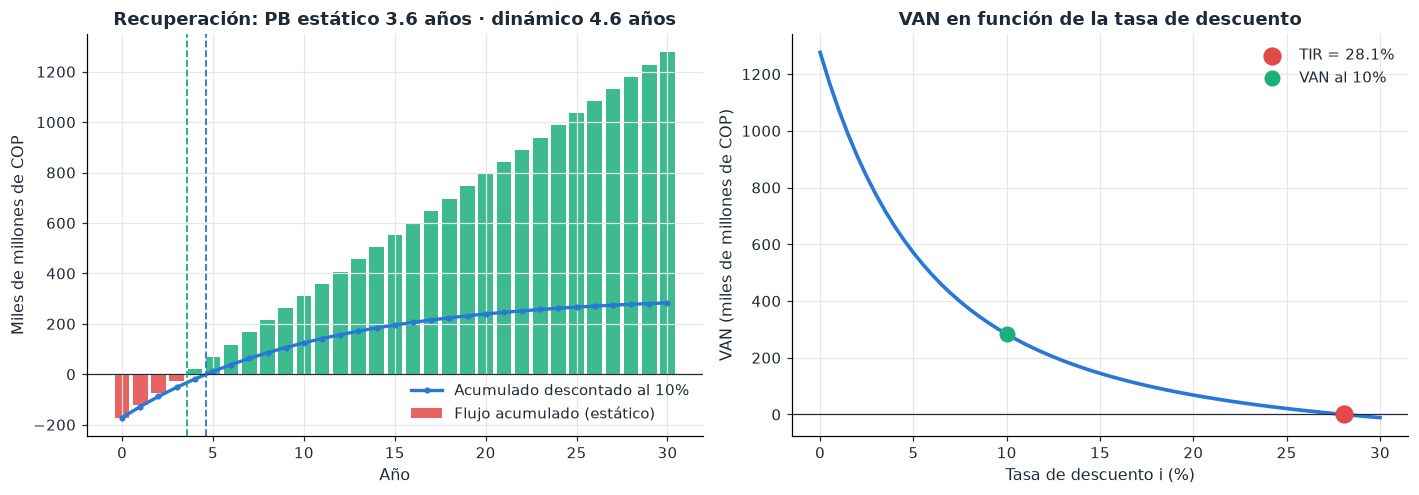

In [56]:
# ============================================================
# GRÁFICA 15 - RECUPERACIÓN DE LA INVERSIÓN Y VAN VS TASA DE DESCUENTO
# ============================================================

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))               # Dos paneles.
acum = ev["Amortización"].values / 1e9                        # Flujo acumulado (miles de millones).
acum_d = np.cumsum(ev["Flujo de caja"].values * (1 + i_desc) ** -ev["Año"].values) / 1e9  # Acumulado descontado.
ax[0].bar(ev["Año"], acum, color=np.where(acum < 0, PALETA[7], PALETA[2]), alpha=0.85, label="Flujo acumulado (estático)")  # Barras.
ax[0].plot(ev["Año"], acum_d, color=PALETA[0], lw=2.2, marker="o", ms=3, label=f"Acumulado descontado al {i_desc:.0%}")  # Línea.
ax[0].axhline(0, color=TINTA, lw=0.8)                         # Línea de cero.
ax[0].axvline(ind_base["PB estático [años]"], color=PALETA[2], ls="--", lw=1.2)  # PB estático.
ax[0].axvline(ind_base["PB dinámico [años]"], color=PALETA[0], ls="--", lw=1.2)  # PB dinámico.
ax[0].set(xlabel="Año", ylabel="Miles de millones de COP",
          title=f"Recuperación: PB estático {ind_base['PB estático [años]']:.1f} años · dinámico {ind_base['PB dinámico [años]']:.1f} años")  # Rótulos.
ax[0].legend()                                                # Leyenda.
tasas = np.linspace(0, 0.30, 61)                              # Tasas de descuento de 0 a 30 %.
vans = [indicadores(ev, r)["VAN [MCOP]"] / 1e3 for r in tasas]  # VAN para cada tasa (miles de millones).
ax[1].plot(tasas * 100, vans, lw=2.4, color=PALETA[0])        # Curva VAN(i).
ax[1].axhline(0, color=TINTA, lw=0.8)                         # Línea de cero.
ax[1].scatter(ind_base["TIR"] * 100, 0, s=120, color=PALETA[7], zorder=5, label=f"TIR = {ind_base['TIR']:.1%}")  # TIR.
ax[1].scatter(i_desc * 100, ind_base["VAN [MCOP]"] / 1e3, s=90, color=PALETA[2], zorder=5, label=f"VAN al {i_desc:.0%}")  # VAN a la tasa adoptada.
ax[1].set(xlabel="Tasa de descuento i (%)", ylabel="VAN (miles de millones de COP)", title="VAN en función de la tasa de descuento")  # Rótulos.
ax[1].legend()                                                # Leyenda.
fig.tight_layout()                                            # Ajusta márgenes.
plt.show()                                                    # Dibuja.

In [57]:
# ============================================================
# INDICADORES DE LOS CINCO ESCENARIOS
# ============================================================

filas = []                                                    # Tabla por escenario.
for nombre, (p, e) in ESC.items():                            # Recorre los escenarios.
    I_a = float((p * e).sum())                                # Ingreso anual del escenario.
    egr = OPEX + (ley99 * I_a if P_inst > 10 else 0)          # Egresos del escenario (las transferencias dependen de la venta).
    filas.append({"Escenario": nombre, "Energía [GWh]": e.sum() / 1e6, "Precio [COP/kWh]": I_a / e.sum(),
                  **indicadores(tabla_evaluacion(e.sum(), I_a, CAPEX, egr))})  # Indicadores.
ind_esc = pd.DataFrame(filas)                                 # Tabla final.
ind_esc["TIR [%]"] = ind_esc.pop("TIR") * 100                 # TIR en porcentaje.
ind_esc.set_index("Escenario").round(2)                       # Indicadores de los cinco escenarios.

,Energía [GWh],Precio [COP/kWh],VAN [MCOP],B/C,PB estático [años],PB dinámico [años],C_T [MCOP],Anualidad A [MCOP/año],LCOE [COP/kWh],TIR [%]
Escenario,,,,,,,,,,
1. Venta en bolsa,144.170,573.000,"502,408.060",2.820,2.400,2.890,"276,344.420","29,314.410",203.330,41.610
2. Contrato bilateral,144.170,327.850,"189,215.060",1.740,4.490,6.260,"256,353.380","27,193.770",188.620,22.230
3. Conservador,135.500,149.990,"-49,516.870",0.790,13.240,NaN,"241,115.170","25,577.320",188.760,6.370
4. Base,144.170,401.400,"283,172.960",2.080,3.560,4.630,"262,350.690","27,829.960",193.040,28.060
5. Optimista,147.250,773.420,"779,570.930",3.650,1.700,1.960,"294,035.670","31,191.080",211.820,58.710


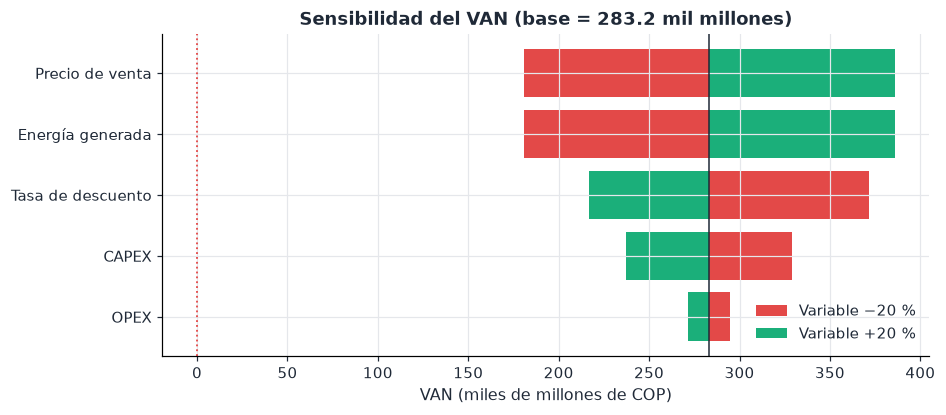

,Variable,−20 %,+20 %,Rango
3,OPEX,294.700,271.600,23.100
2,CAPEX,329.100,237.200,91.800
4,Tasa de descuento,371.600,217.000,154.600
1,Energía generada,180.600,385.700,205.100
0,Precio de venta,180.600,385.700,205.100


In [58]:
# ============================================================
# GRÁFICA 16 - ANÁLISIS DE SENSIBILIDAD (TORNADO ±20 %)
# ============================================================

def van_con(f_precio=1, f_energia=1, f_capex=1, f_opex=1, i=i_desc):  # VAN del escenario base con factores de cambio.
    I_a = I_base * f_precio * f_energia                       # Ingreso modificado.
    egr = OPEX * f_opex * f_capex + (ley99 * I_a if P_inst > 10 else 0)  # El OPEX es proporcional al CAPEX (clase 14).
    return indicadores(tabla_evaluacion(e_base.sum() * f_energia, I_a, CAPEX * f_capex, egr), i)["VAN [MCOP]"] / 1e3  # Miles de millones.

van0 = van_con()                                              # VAN del caso base.
sens = pd.DataFrame([                                         # Variable, VAN con −20 %, VAN con +20 %.
    ("Precio de venta", van_con(f_precio=0.8), van_con(f_precio=1.2)),
    ("Energía generada", van_con(f_energia=0.8), van_con(f_energia=1.2)),
    ("CAPEX", van_con(f_capex=0.8), van_con(f_capex=1.2)),
    ("OPEX", van_con(f_opex=0.8), van_con(f_opex=1.2)),
    ("Tasa de descuento", van_con(i=i_desc * 0.8), van_con(i=i_desc * 1.2)),
], columns=["Variable", "−20 %", "+20 %"])
sens["Rango"] = (sens["+20 %"] - sens["−20 %"]).abs()         # Amplitud del efecto.
sens = sens.sort_values("Rango")                              # Las más influyentes arriba.
fig, ax = plt.subplots(figsize=(9, 3.8))                      # Figura.
ax.barh(sens["Variable"], sens["−20 %"] - van0, left=van0, color=PALETA[7], label="Variable −20 %")  # Efecto a la baja.
ax.barh(sens["Variable"], sens["+20 %"] - van0, left=van0, color=PALETA[2], label="Variable +20 %")  # Efecto al alza.
ax.axvline(van0, color=TINTA, lw=1)                           # VAN base.
ax.axvline(0, color=PALETA[7], ls=":", lw=1.2)                # Frontera de viabilidad.
ax.set(xlabel="VAN (miles de millones de COP)", title=f"Sensibilidad del VAN (base = {van0:,.1f} mil millones)")  # Rótulos.
ax.legend(loc="lower right")                                  # Leyenda.
plt.show()                                                    # Dibuja.
sens.round(1)                                                 # Tabla de sensibilidad.

### 12.1 Riesgo: simulación de Monte Carlo

Los escenarios fijos no dicen **qué tan probable** es perder dinero. Se simulan 3.000 vidas útiles de 30 años: cada año se sortea un año hidrológico de la serie (25 disponibles) y una ventana de 12 meses consecutivos de precios de bolsa observados (25 ventanas); la energía se vende con la misma cartera del escenario base (70 % contrato, 30 % bolsa).

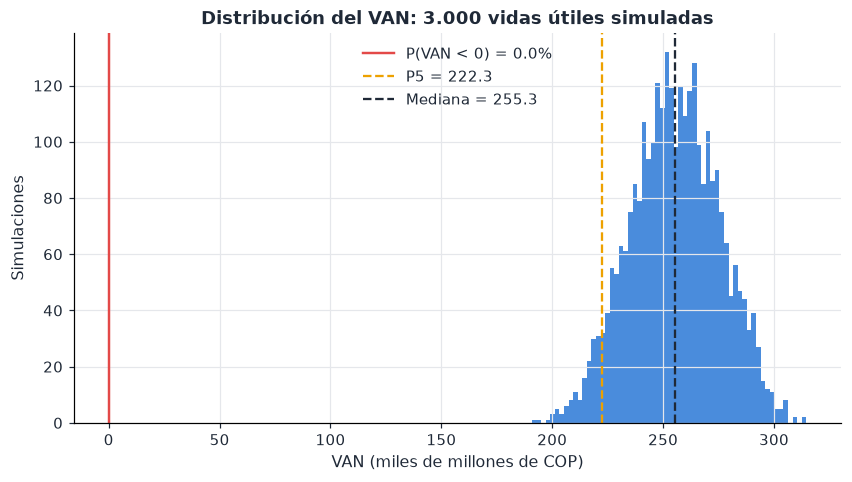

In [59]:
# ============================================================
# SIMULACIÓN DE MONTE CARLO DEL VAN
# ============================================================

ventanas = np.array([[bolsa.iloc[j:j + 12][bolsa.index[j:j + 12].month == m].mean() for m in range(1, 13)]
                     for j in range(len(bolsa) - 11)])        # Ventanas de 12 meses ordenadas por mes calendario.
rng = np.random.default_rng(semilla)                          # Generador reproducible.
n_sim = 3000                                                  # Número de vidas útiles simuladas.
fd = (1 + i_desc) ** -np.arange(1, vida_util + 1)             # Factores de descuento de los años 1..n.
van_mc = np.empty(n_sim)                                      # Resultados.
for s in range(n_sim):                                        # Cada simulación es una vida útil completa.
    h = rng.integers(0, n_a, vida_util)                       # Años hidrológicos sorteados.
    w = rng.integers(0, len(ventanas), vida_util)             # Ventanas de precio sorteadas.
    precio = frac_contrato * precio_contrato + (1 - frac_contrato) * ventanas[w]  # Precio mensual de cada año.
    I_t = (E_mat[h] * precio).sum(1)                          # Ingreso de cada año (COP).
    FC_t = I_t - OPEX - (ley99 * I_t if P_inst > 10 else 0)   # Flujo de caja de cada año.
    van_mc[s] = -CAPEX + (FC_t * fd).sum()                    # VAN de la simulación.
van_mc /= 1e9                                                 # Miles de millones de COP.
p_perdida = (van_mc < 0).mean()                               # Probabilidad de VAN negativo.
fig, ax = plt.subplots()                                      # Figura.
ax.hist(van_mc, bins=60, color=PALETA[0], alpha=0.85)         # Histograma del VAN.
ax.axvline(0, color=PALETA[7], lw=1.6, label=f"P(VAN < 0) = {p_perdida:.1%}")  # Frontera de pérdida.
ax.axvline(np.percentile(van_mc, 5), color=PALETA[3], ls="--", label=f"P5 = {np.percentile(van_mc, 5):,.1f}")  # Percentil 5.
ax.axvline(np.median(van_mc), color=TINTA, ls="--", label=f"Mediana = {np.median(van_mc):,.1f}")  # Mediana.
ax.set(xlabel="VAN (miles de millones de COP)", ylabel="Simulaciones", title="Distribución del VAN: 3.000 vidas útiles simuladas")  # Rótulos.
ax.legend()                                                   # Leyenda.
plt.show()                                                    # Dibuja.

In [60]:
# ============================================================
# VARIANTE DESPUÉS DE IMPUESTOS (INVERSIONISTA PRIVADO)
# ============================================================

ev_imp = ev.copy()                                            # Parte de la tabla base.
base_grav = ev_imp["Utilidades"].clip(lower=0)                # Utilidad gravable (la depreciación reduce el impuesto).
ev_imp["Impuesto de renta"] = base_grav * tasa_renta          # Impuesto del 35 %.
ev_imp["Flujo de caja"] = ev_imp["Flujo de caja"] - ev_imp["Impuesto de renta"]  # Flujo después de impuestos.
ind_imp = indicadores(ev_imp)                                 # Indicadores después de impuestos.
comparacion_imp = pd.DataFrame({"Clase 14 (sin impuestos)": ind_base, f"Después de renta {tasa_renta:.0%}": ind_imp})  # Comparación.
comparacion_imp.loc[["VAN [MCOP]", "TIR", "PB estático [años]", "PB dinámico [años]"]]  # Indicadores principales.

,Clase 14 (sin impuestos),Después de renta 35%
VAN [MCOP],"283,172.959","142,797.718"
TIR,0.281,0.193
PB estático [años],3.561,5.150
PB dinámico [años],4.630,7.603


**Interpretación de resultados.** Con la metodología de la clase 14 el proyecto cumple los tres criterios en el escenario base y el riesgo de VAN negativo es bajo cuando la mayor parte de la energía se contrata. Las variables que más mueven el resultado son el **precio de venta** y la **energía generada**: la prioridad comercial es cerrar un contrato de largo plazo, y la técnica, no perder salto ni disponibilidad. Para un inversionista privado (variante con impuesto de renta) la TIR baja pero sigue por encima de la tasa de descuento; el incentivo de la Ley 1715 de 2014 (deducción del 50 % de la inversión) mejoraría esa cifra y se recomienda evaluarlo en factibilidad.

---
# 13. ML hidráulico: factibilidad de la tubería y predicción de pérdidas

Esta sección responde a los comentarios del profesor a la Entrega 2: **justificar los algoritmos frente a un modelo base**, **interpretar los errores en unidades de ingeniería** (m y MW) y **analizar los falsos factibles** (casos que el ML aprueba y la física rechaza).

**Dataset.** `dataset_hidraulico_v0.1.0.csv`: 700 escenarios (Q, L, H, ε, K) × 12 diámetros = 8.400 casos calculados con Darcy–Weisbach y Swamee–Jain. Un caso es factible si $V \le 5$ m/s y $h_L \le 6\,\%\,H_b$.

**Decisiones de diseño del experimento:**
1. **Partición agrupada por escenario** (`GroupShuffleSplit`): los 12 diámetros de un mismo escenario quedan todos en entrenamiento o todos en prueba. Si se mezclaran, el modelo "vería" el escenario y la métrica sería optimista (fuga de información).
2. **Variables con sentido físico** además de las crudas: $V$, $V^2/2g$, $L/D$, $\varepsilon/D$, $\log Re$ y un índice de pérdida calculado con un factor de fricción fijo de referencia. Se calculan **sin** resolver la ecuación de pérdidas: el modelo sigue teniendo que aprender la física de la fricción.
3. **Transformación logarítmica de $h_L$**: las pérdidas van de centímetros a cientos de metros; en escala log el error relativo se reparte de forma pareja.
4. **Modelo:** *HistGradientBoosting*, la versión por histogramas del Gradient Boosting usado en la sección 8, más rápida en datasets de miles de filas.

Índice de pérdida (variable de entrada, con un factor de fricción de referencia $f \approx 0.012$):

$$I_p=\frac{\left(0.012\,\dfrac{L}{D}+K\right)\dfrac{V^2}{2g}}{H_b}$$

Objetivo de regresión de las pérdidas, transformado a logaritmo:

$$y=\ln h_L\qquad\Rightarrow\qquad \hat h_L=e^{\hat y}$$

Errores en unidades de ingeniería (m de pérdida, m de salto, MW):

$$MAE=\frac{1}{n}\sum_{k=1}^{n}\left|\hat y_k-y_k\right|,\qquad R^2=1-\frac{\sum_k(\hat y_k-y_k)^2}{\sum_k(y_k-\bar y)^2}$$

Para la clasificación, la métrica clave es la precisión (fracción de los "factibles" del modelo que realmente lo son):

$$\text{Precisión}=\frac{VP}{VP+FP}$$

In [61]:
# ============================================================
# CARGA, CONTROL DE CALIDAD Y VARIABLES FÍSICAS DEL DATASET HIDRÁULICO
# ============================================================

dsh = consulta("SELECT * FROM dataset_hidraulico")            # Dataset de 8.400 casos desde la base SQL.
CRUDAS = ["Q_m3s", "L_m", "H_bruto_m", "epsilon_mm", "K_total", "D_m"]  # Variables de entrada originales.
constantes = [c for c in ["rho_kgm3", "nu_m2s", "g_ms2", "eta_t", "eta_g", "fraccion_perdida_max"] if dsh[c].nunique() == 1]  # Sin varianza.
qc_ml = pd.Series({"Filas": len(dsh), "Escenarios": dsh.scenario_id.nunique(), "Nulos": int(dsh[CRUDAS].isna().sum().sum()),
                   "Duplicados": int(dsh.duplicated(subset=CRUDAS).sum()), "Columnas constantes (se eliminan)": len(constantes),
                   "Casos factibles": f"{dsh.factible.mean():.1%}", "Casos con hL > H (no físicos)": int((dsh.hL_m > dsh.H_bruto_m).sum())})

def fisicas(df):                                              # Variables con sentido físico, calculables sin resolver las pérdidas.
    X = df[CRUDAS].copy()                                     # Parte de las variables crudas.
    V = df.Q_m3s / (np.pi * df.D_m ** 2 / 4)                  # Velocidad (m/s).
    X["V_ms"], X["carga_vel_m"] = V, V ** 2 / (2 * g)         # Velocidad y carga de velocidad.
    X["L_D"], X["eps_D"] = df.L_m / df.D_m, df.epsilon_mm / 1000 / df.D_m  # Esbeltez y rugosidad relativa.
    X["log_Re"] = np.log10(V * df.D_m / nu)                   # Logaritmo del Reynolds.
    X["indice_perdida"] = (0.012 * X.L_D + df.K_total) * X.carga_vel_m / df.H_bruto_m  # Pérdida relativa con f ≈ 0,012.
    return X                                                  # Matriz de variables.

g1 = GroupShuffleSplit(1, test_size=0.30, random_state=semilla)  # Primer corte: 70 % / 30 %.
i_tr, i_rest = next(g1.split(dsh, groups=dsh.scenario_id))    # Índices por escenario.
resto = dsh.iloc[i_rest]                                      # 30 % restante.
i_va, i_te = next(GroupShuffleSplit(1, test_size=0.50, random_state=semilla).split(resto, groups=resto.scenario_id))  # 15 % / 15 %.
tr, va, te = dsh.iloc[i_tr], resto.iloc[i_va], resto.iloc[i_te]  # Conjuntos de entrenamiento, validación y prueba.
assert not set(tr.scenario_id) & set(te.scenario_id), "Fuga de información entre entrenamiento y prueba"  # Control de fuga.
qc_ml.to_frame("Control de calidad")                          # Muestra el control.

,Control de calidad
Filas,8400
Escenarios,700
Nulos,0
Duplicados,0
Columnas constantes (se eliminan),6
Casos factibles,48.9%
Casos con hL > H (no físicos),1493


In [62]:
# ============================================================
# CLASIFICACIÓN DE FACTIBILIDAD: MODELO BASE VS MODELOS DE ML
# ============================================================

clfs = {                                                      # Nombre: (modelo, tipo de variables).
    "Base: clase mayoritaria": (DummyClassifier(strategy="most_frequent"), "crudas"),
    "Regresión logística (crudas)": (make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)), "crudas"),
    "HistGradientBoosting (crudas, Entrega 2)": (HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, random_state=semilla), "crudas"),
    "HistGradientBoosting (variables físicas)": (HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, random_state=semilla), "fisicas"),
}
X_de = lambda df, tipo: df[CRUDAS] if tipo == "crudas" else fisicas(df)  # Selecciona el tipo de variables.
filas = []                                                    # Tabla de métricas.
for nombre, (m, tipo) in clfs.items():                        # Entrena y evalúa cada modelo.
    m.fit(X_de(tr, tipo), tr.factible)                        # Ajuste.
    p = m.predict(X_de(te, tipo))                             # Predicción en prueba.
    cm_ = confusion_matrix(te.factible, p, labels=[0, 1])     # Matriz de confusión.
    filas.append([nombre, accuracy_score(te.factible, p), precision_score(te.factible, p, zero_division=0),
                  recall_score(te.factible, p), f1_score(te.factible, p), cm_[0, 1], cm_[1, 0]])  # Métricas.
met_clf = pd.DataFrame(filas, columns=["Modelo", "Exactitud", "Precisión", "Exhaustividad", "F1",
                                       "Falsos factibles (FP)", "Falsos no factibles (FN)"])  # Tabla final.
met_clf                                                       # Muestra la tabla.

,Modelo,Exactitud,Precisión,Exhaustividad,F1,Falsos factibles (FP),Falsos no factibles (FN)
0,Base: clase mayoritaria,0.508,0.000,0.000,0.000,0,620
1,Regresión logística (crudas),0.942,0.943,0.939,0.941,35,38
2,"HistGradientBoosting (crudas, Entrega 2)",0.975,0.977,0.973,0.975,14,17
3,HistGradientBoosting (variables físicas),0.998,1.000,0.997,0.998,0,2


**El error que importa es el falso factible.** Un falso no factible solo hace perder una alternativa; un **falso factible** puede llevar a recomendar una tubería que erosiona o que pierde más del 6 % del salto. Por eso el umbral de probabilidad no se deja en 0,5: se elige en **validación** el menor umbral que logra una precisión ≥ 99,5 %, y luego se mide en prueba.

In [63]:
# ============================================================
# UMBRAL DE PRECISIÓN Y ANÁLISIS DE FALSOS FACTIBLES
# ============================================================

clf_h = clfs["HistGradientBoosting (variables físicas)"][0]   # Mejor clasificador.
prob_va = clf_h.predict_proba(fisicas(va))[:, 1]              # Probabilidades en validación.
umbral = next((u for u in np.arange(0.50, 0.995, 0.005)
               if precision_score(va.factible, prob_va >= u, zero_division=0) >= 0.995), 0.99)  # Menor umbral con precisión ≥ 99,5 %.
prob_te = clf_h.predict_proba(fisicas(te))[:, 1]              # Probabilidades en prueba del modelo con variables físicas.
n_ff = int(((prob_te >= umbral) & (te.factible == 0)).sum())  # Falsos factibles del modelo final.
clf_e2 = clfs["HistGradientBoosting (crudas, Entrega 2)"][0]  # Modelo de la Entrega 2, para ver cómo son sus errores.
prob_e2 = clf_e2.predict_proba(te[CRUDAS])[:, 1]              # Probabilidades del modelo de la Entrega 2.
ff = te[(prob_e2 >= 0.5) & (te.factible == 0)].assign(prob=prob_e2[(prob_e2 >= 0.5) & (te.factible == 0)])  # Sus falsos factibles.
ff["exceso V [m/s]"] = (ff.V_ms - V_max).clip(lower=0)        # Cuánto superan la velocidad máxima.
ff["exceso pérdida [pp]"] = ((ff.loss_frac - ff.fraccion_perdida_max) * 100).clip(lower=0)  # Cuánto superan el 6 %.
print(f"Modelo final (variables físicas), umbral {umbral:.3f} elegido en validación: {n_ff} falsos factibles de {(te.factible == 0).sum()} no factibles")  # Resultado.
print(f"Modelo de la Entrega 2 (crudas), umbral 0,5: {len(ff)} falsos factibles; exceso mediano de V = {ff['exceso V [m/s]'].median():.2f} m/s, "
      f"de pérdida = {ff['exceso pérdida [pp]'].median():.2f} pp")  # Cómo eran los errores antes.
ff[["scenario_id", "Q_m3s", "D_m", "V_ms", "loss_frac", "motivo", "prob", "exceso V [m/s]", "exceso pérdida [pp]"]].head(8)  # Ejemplos.

Modelo final (variables físicas), umbral 0.765 elegido en validación: 0 falsos factibles de 640 no factibles
Modelo de la Entrega 2 (crudas), umbral 0,5: 14 falsos factibles; exceso mediano de V = 0.00 m/s, de pérdida = 0.45 pp


,scenario_id,Q_m3s,D_m,V_ms,loss_frac,motivo,prob,exceso V [m/s],exceso pérdida [pp]
651,S0054,7.216,2.091,2.101,0.067,pérdidas>límite,0.532,0.000,0.711
1445,S0120,24.100,2.818,3.864,0.066,pérdidas>límite,0.843,0.000,0.583
2312,S0192,26.463,3.909,2.205,0.060,pérdidas>límite,0.793,0.000,0.021
2552,S0212,43.117,3.909,3.593,0.068,pérdidas>límite,0.522,0.000,0.802
2826,S0235,35.011,3.182,4.403,0.063,pérdidas>límite,0.743,0.000,0.271
3011,S0250,8.993,5.000,0.458,0.001,V<Vmin,0.769,0.000,0.000
3607,S0300,31.874,3.545,3.229,0.082,pérdidas>límite,0.505,0.000,2.191
4240,S0353,7.852,2.455,1.659,0.066,pérdidas>límite,0.939,0.000,0.615


Los falsos factibles del modelo de la Entrega 2 son casos **frontera**: superan los límites por poco, justo donde las variables crudas obligan al modelo a "adivinar" la física de la fricción. Al darle variables con sentido físico ($V$, $L/D$, índice de pérdida) y un umbral elegido en validación, desaparecen en el conjunto de prueba. Aun así, la regla del cuaderno se mantiene: **toda recomendación pasa por la verificación física**, que recalcula $V$, $h_L$ y $H_n$.

### 13.1 Regresión de pérdidas, salto neto y potencia (errores en unidades de ingeniería)

In [64]:
# REGRESIÓN DE hL, H_NETO Y P_e CON ERRORES EN m Y MW
tr_a, te_a = tr[tr.hL_m < tr.H_bruto_m], te[te.hL_m < te.H_bruto_m]  # Dominio físico: pérdidas menores que el salto.
OBJ = {"hL_m": "m", "H_neto_m": "m", "P_e_MW": "MW"}          # Objetivos y sus unidades.
regs = {"Base: media": (DummyRegressor, "crudas", False), "Regresión lineal (crudas)": (LinearRegression, "crudas", False),
        "HistGradientBoosting (físicas + log hL)": (lambda: HistGradientBoostingRegressor(max_iter=600, learning_rate=0.05,
                                                                                         random_state=semilla), "fisicas", True)}
filas, pred_reg = [], {}                                      # Métricas y predicciones.
for nombre, (fab, tipo, logh) in regs.items():                # Recorre los regresores.
    for obj, u in OBJ.items():                                # Y los tres objetivos.
        y = np.log(tr_a[obj]) if (logh and obj == "hL_m") else tr_a[obj]  # Transformación log de las pérdidas.
        m = fab().fit(X_de(tr_a, tipo), y)                    # Ajuste.
        p = m.predict(X_de(te_a, tipo))                       # Predicción.
        p = np.exp(p) if (logh and obj == "hL_m") else p      # Regresa a metros.
        e = np.abs(p - te_a[obj].values)                      # Error absoluto.
        filas.append([nombre, obj, u, e.mean(), np.percentile(e, 95), r2_score(te_a[obj], p)])  # Métricas.
        pred_reg[(nombre, obj)] = p                           # Guarda la predicción.
met_reg = pd.DataFrame(filas, columns=["Modelo", "Objetivo", "Unidad", "MAE", "Error P95", "R²"])  # Tabla.
met_reg.pivot(index="Modelo", columns="Objetivo", values="MAE").round(3)  # MAE por modelo y objetivo (en su unidad).

Objetivo,H_neto_m,P_e_MW,hL_m
Modelo,,,
Base: media,39.675,11.064,12.889
HistGradientBoosting (físicas + log hL),0.802,0.618,0.436
Regresión lineal (crudas),10.159,4.457,10.159


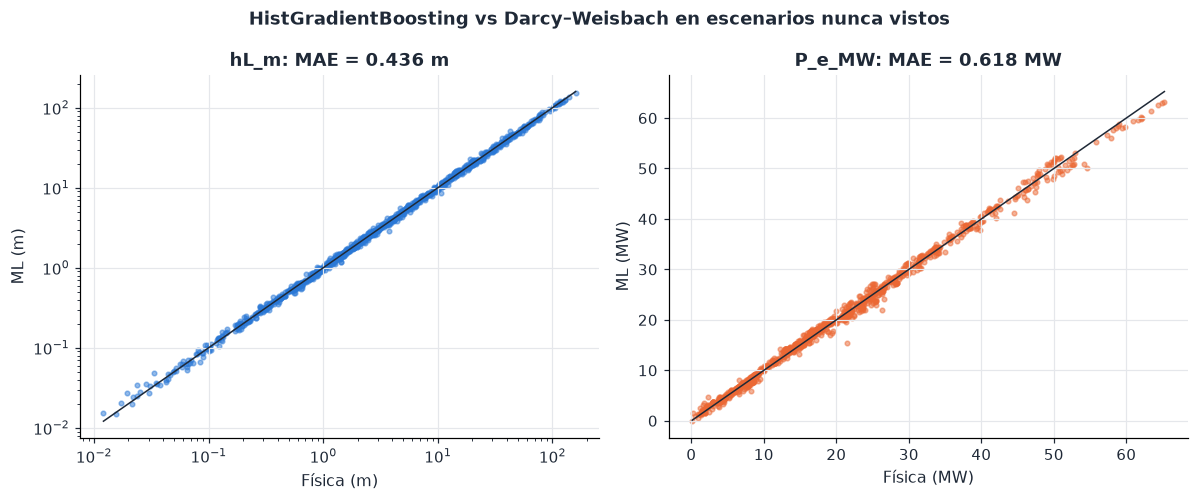

In [65]:
# ============================================================
# GRÁFICA 17 - PREDICCIÓN DEL ML VS CÁLCULO FÍSICO (CONJUNTO DE PRUEBA)
# ============================================================

fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))               # Dos paneles: pérdidas y potencia.
for k, (obj, u, esc) in enumerate([("hL_m", "m", "log"), ("P_e_MW", "MW", "linear")]):  # Objetivos a graficar.
    real, pred = te_a[obj].values, pred_reg[("HistGradientBoosting (físicas + log hL)", obj)]  # Física y ML.
    ax[k].scatter(real, pred, s=9, alpha=0.5, color=PALETA[k])  # Nube de puntos.
    lim = [max(real.min(), 1e-2), real.max()]                 # Límites de la diagonal.
    ax[k].plot(lim, lim, color=TINTA, lw=1)                   # Diagonal perfecta.
    mae = met_reg.query("Modelo.str.startswith('HistGradient') and Objetivo == @obj", engine="python")["MAE"].iloc[0]  # MAE.
    ax[k].set(xscale=esc, yscale=esc, xlabel=f"Física ({u})", ylabel=f"ML ({u})", title=f"{obj}: MAE = {mae:.3f} {u}")  # Rótulos.
fig.suptitle("HistGradientBoosting vs Darcy–Weisbach en escenarios nunca vistos", fontweight="bold")  # Título.
fig.tight_layout()                                            # Ajusta márgenes.
plt.show()                                                    # Dibuja.

---
# 14. Optimización: método tradicional vs ML + física

**Variables de decisión:** caudal de diseño $Q_d$ (18 a 50 m³/s), material y diámetro comercial, número de unidades (1 o 2).

**Restricciones:** $V \le 5$ m/s, $h_L \le 6\,\%\,H_b$, turbina factible (sección 8.1) y potencia menor de 20 MW (planta menor, CREG 086 de 1996).

**Objetivo:** máximo VAN del escenario base con la metodología de la clase 14:

$$\max_{Q_d,\ D,\ \text{material},\ n_u}\ VAN$$

El método tradicional toma el caudal disponible excedido el 30 % del tiempo y el diámetro económico de Fahlbusch (ESHA 2004):

$$D=0.52\,H^{-0.17}\left(\frac{P}{H}\right)^{0.43}$$

Se comparan tres caminos:

| Método | Cómo decide | Evaluaciones completas |
|---|---|---|
| **Tradicional** | $Q_{30}$ + Fahlbusch + una Francis | 1 |
| **Exhaustivo** | evalúa con física y finanzas **todas** las configuraciones factibles | todas |
| **ML + física** | un *GradientBoostingRegressor* aprende el VAN con el 20 % de las configuraciones, predice el resto y solo se evalúan completas las 10 mejores | 20 % + 10 |

In [66]:
# ============================================================
# EVALUADOR COMPLETO DE UNA CONFIGURACIÓN (FÍSICA + ENERGÍA + CLASE 14)
# ============================================================

mes_idx = bloque["mes"].values - 1                            # Mes de cada día de los años completos.
K_bif = float(bd_acc.loc["BIF_Y_SIMETRICA", "K"])             # Bifurcación en Y de la base de datos de accesorios (si hay 2 unidades).
def evaluar_config(Qd, D, eps, mat, n_u, tipo="Francis"):     # Devuelve energía, potencia, CAPEX y VAN.
    K = K_total + (K_bif if n_u > 1 else 0)                   # Bifurcación si hay más de una unidad.
    h = hidraulica(Qd, D, eps, K)                             # Punto de diseño.
    Hn = float(h["Hn"])                                       # Salto neto de diseño.
    P = rho * g * Qd * Hn * float(eta_turbina(tipo, 1.0)) * eta_g / 1e6  # Potencia instalada (MW).
    s = simular(Qd, D, eps, K, n_u, tipo)                     # Simulación diaria.
    E_m = np.bincount(mes_idx, weights=s["E_neta_kWh"].values[: n_a * 365], minlength=12) / n_a  # Energía media de cada mes.
    I_a = float((E_m * p_base).sum())                         # Ingreso con el precio del escenario base.
    capex = capex_usd(P, D, mat, n_u)["total"] * TRM          # CAPEX (COP).
    egr = (f_cop + f_mant + f_adm) * capex + (ley99 * I_a if P > 10 else 0)  # Egresos anuales.
    ind = indicadores(tabla_evaluacion(E_m.sum(), I_a, capex, egr))  # Indicadores de la clase 14.
    return dict(Q_d=Qd, material=mat, D=D, eps=eps, unidades=n_u, V=float(h["V"]), perdida=float(h["perdida"]), P_MW=P,
                E_GWh=E_m.sum() / 1e6, CAPEX_MUSD=capex / TRM / 1e6, VAN_MCOP=ind["VAN [MCOP]"], TIR=ind["TIR"])  # Resultado.

def pasa_fisica(Qd, D, eps, n_u):                             # Filtro físico rápido (sin simular).
    h = hidraulica(Qd, D, eps, K_total + (K_bif if n_u > 1 else 0))  # Punto de diseño.
    P = rho * g * Qd * float(h["Hn"]) * 0.92 * eta_g / 1e6    # Potencia aproximada (MW).
    return (V_min <= h["V"] <= V_max) and (h["perdida"] <= perdida_max) and (P < 20) and factibilidad("Francis", float(h["Hn"]), Qd / n_u)["factible"]

cand = [(q, r_.Diametro_hidraulico_m, r_.epsilon_diseno_mm, r_.Material_ID, n)  # Malla de candidatos.
        for q in np.arange(18, 51, 1.0) for _, r_ in catalogo[catalogo.Diametro_hidraulico_m.between(1.5, 4.0)].iterrows() for n in (1, 2)]
fact = [c for c in cand if pasa_fisica(c[0], c[1], c[2], c[4])]  # Candidatos que pasan la física.
print(f"Candidatos en la malla: {len(cand):,}  |  rechazados por la física: {len(cand) - len(fact):,}  |  factibles: {len(fact):,}")  # Resumen.

Candidatos en la malla: 2,706  |  rechazados por la física: 2,253  |  factibles: 453


In [67]:
# ============================================================
# MÉTODO TRADICIONAL, EXHAUSTIVO Y ML + FÍSICA
# ============================================================

t0 = time.perf_counter()                                      # Cronómetro del exhaustivo.
exh = pd.DataFrame([evaluar_config(*c) for c in fact])        # Evalúa todas las configuraciones factibles.
t_exh = time.perf_counter() - t0                              # Tiempo del exhaustivo.
opt = exh.loc[exh.VAN_MCOP.idxmax()]                          # Óptimo exhaustivo.

Q_trad = round(float(np.percentile(np.maximum(rio.Q_rio_m3s - Q_eco, 0), 70)), 1)  # Caudal disponible excedido el 30 % del tiempo.
P_trad = g * Q_trad * H_bruto * 0.85                          # Potencia estimada (kW) con η global 0,85.
D_fahl = 0.52 * H_bruto ** -0.17 * (P_trad / H_bruto) ** 0.43 # Diámetro económico de Fahlbusch (m).
grp = catalogo[catalogo.Material_ID == "GRP_FLOWTITE"].sort_values("Diametro_hidraulico_m")  # Diámetros GRP.
d_t = grp[grp.Diametro_hidraulico_m >= D_fahl].iloc[0]        # Diámetro comercial inmediatamente superior.
trad = evaluar_config(Q_trad, d_t.Diametro_hidraulico_m, d_t.epsilon_diseno_mm, "GRP_FLOWTITE", 1)  # Evaluación completa.

t0 = time.perf_counter()                                      # Cronómetro del método ML + física.
rng = np.random.default_rng(semilla)                          # Generador reproducible.
idx_m = rng.choice(len(fact), size=max(20, len(fact) // 5), replace=False)  # Muestra del 20 % para entrenar.
X_opt = pd.DataFrame(fact, columns=["Q_d", "D", "eps", "material", "unidades"]).drop(columns="material")  # Variables del sustituto.
y_m = pd.DataFrame([evaluar_config(*fact[j]) for j in idx_m]).VAN_MCOP.values  # VAN real de la muestra.
sust = GradientBoostingRegressor(n_estimators=400, learning_rate=0.05, max_depth=3, random_state=semilla).fit(X_opt.iloc[idx_m], y_m)  # Sustituto.
top = np.argsort(-sust.predict(X_opt))[:10]                   # Las 10 mejores según el ML.
ml = pd.DataFrame([evaluar_config(*fact[j]) for j in top]).sort_values("VAN_MCOP", ascending=False).iloc[0]  # La física decide entre ellas.
t_ml = time.perf_counter() - t0                               # Tiempo del método ML + física.
actual = evaluar_config(Q_diseno, D_sel, eps_sel, material_id, n_unid)  # Diseño de la Entrega 2 (referencia).

comp = pd.DataFrame([dict(Método="Tradicional (Q30 + Fahlbusch)", **trad, evaluaciones=1, tiempo_s=np.nan),
                     dict(Método="Diseño de la Entrega 2", **actual, evaluaciones=1, tiempo_s=np.nan),
                     dict(Método="Exhaustivo (física + finanzas)", **opt.to_dict(), evaluaciones=len(fact), tiempo_s=t_exh),
                     dict(Método="ML preselecciona + física decide", **ml.to_dict(), evaluaciones=len(idx_m) + 10, tiempo_s=t_ml)])
comp["Brecha vs óptimo [%]"] = (comp.VAN_MCOP / opt.VAN_MCOP - 1) * 100  # Diferencia de VAN frente al óptimo.
comp["Cumple < 20 MW"] = np.where(comp.P_MW < 20, "✔", "✘")   # Restricción regulatoria.
comp[["Método", "Q_d", "material", "D", "unidades", "P_MW", "E_GWh", "CAPEX_MUSD", "VAN_MCOP", "TIR", "Brecha vs óptimo [%]",
      "Cumple < 20 MW", "evaluaciones"]].round(2)             # Tabla comparativa.

,Método,Q_d,material,D,unidades,P_MW,E_GWh,CAPEX_MUSD,VAN_MCOP,TIR,Brecha vs óptimo [%],Cumple < 20 MW,evaluaciones
0,Tradicional (Q30 + Fahlbusch),48.400,GRP_FLOWTITE,3.300,1,30.560,184.300,85.310,"278,965.120",0.210,-7.240,✘,1
1,Diseño de la Entrega 2,28.000,PE100_AGRU,2.830,1,18.240,144.170,52.140,"283,172.960",0.280,-5.840,✔,1
2,Exhaustivo (física + finanzas),30.000,GRP_FLOWTITE,3.200,1,19.930,155.010,56.890,"300,749.380",0.280,0.000,✔,453
3,ML preselecciona + física decide,30.000,GRP_FLOWTITE,3.200,1,19.930,155.010,56.890,"300,749.380",0.280,0.000,✔,100


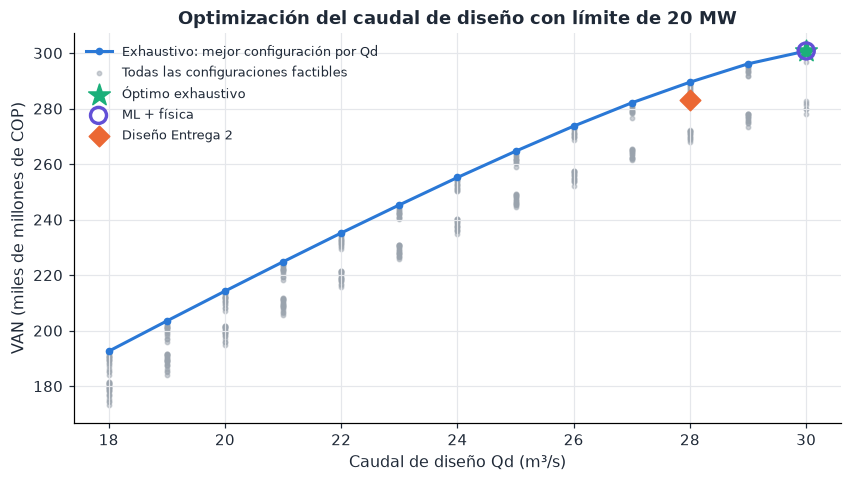

Tradicional: Qd = 48.4 m³/s → P = 30.6 MW (supera el límite de 20 MW de una planta menor)


In [68]:
# ============================================================
# GRÁFICA 18 - VAN VS CAUDAL DE DISEÑO (MEJOR CONFIGURACIÓN DE CADA CAUDAL)
# ============================================================

mejor_q = exh.loc[exh.groupby("Q_d").VAN_MCOP.idxmax()]       # Mejor diámetro y material para cada caudal.
fig, ax = plt.subplots()                                      # Figura.
ax.plot(mejor_q.Q_d, mejor_q.VAN_MCOP / 1e3, "o-", color=PALETA[0], lw=2, ms=4, label="Exhaustivo: mejor configuración por Qd")  # Curva.
ax.scatter(exh.Q_d, exh.VAN_MCOP / 1e3, s=8, color=GRIS, alpha=0.5, label="Todas las configuraciones factibles")  # Nube.
ax.scatter(opt.Q_d, opt.VAN_MCOP / 1e3, s=220, marker="*", color=PALETA[2], zorder=6, label="Óptimo exhaustivo")  # Óptimo.
ax.scatter(ml.Q_d, ml.VAN_MCOP / 1e3, s=110, facecolor="none", edgecolor=PALETA[6], lw=2.2, zorder=7, label="ML + física")  # ML.
ax.scatter(actual["Q_d"], actual["VAN_MCOP"] / 1e3, s=90, marker="D", color=PALETA[1], zorder=6, label="Diseño Entrega 2")  # Diseño actual.
ax.set(xlabel="Caudal de diseño Qd (m³/s)", ylabel="VAN (miles de millones de COP)",
       title="Optimización del caudal de diseño con límite de 20 MW")  # Rótulos.
ax.legend(fontsize=8.5)                                       # Leyenda.
plt.show()                                                    # Dibuja.
print(f"Tradicional: Qd = {trad['Q_d']} m³/s → P = {trad['P_MW']:.1f} MW (supera el límite de 20 MW de una planta menor)")  # Nota.

**Interpretación.** El método tradicional toma un caudal de diseño alto (Q30) y produce una central de más de 20 MW, que ya no es una planta menor: cambia su régimen comercial (despacho central obligatorio) y deja la tubería al límite de velocidad. El óptimo exhaustivo aprovecha casi todo el margen de 20 MW. El método **ML + física llega al mismo óptimo con una fracción de las evaluaciones**: el sustituto ordena, la física y las finanzas completas deciden. Con mallas más grandes (más materiales, trazados o turbinas) esa diferencia de costo computacional crece rápidamente.

### 14.1 Comparativo de materiales de tubería y material sugerido

Para el caudal de diseño $Q_d$ y la selección de accesorios del tramo se evalúan **todos los materiales de la base de datos de tuberías**, más el acero soldado, que se fabrica a medida. En cada material se recorren sus diámetros comerciales factibles y se conserva el de mayor VAN. Los materiales se comparan en dos dimensiones:

**Eficiencia de la conducción**, la fracción del salto bruto que llega a la turbina:

$$\eta_{cond}=\frac{H_n}{H_b}=1-\frac{h_L}{H_b}$$

**Costo**, el de la tubería (sección 11) y el CAPEX total; ambos se reflejan en el VAN, que combina la energía que deja de producir una tubería con más pérdidas y el costo de una tubería más grande o más cara.

**Golpe de ariete**, con la celeridad de cada material y la sobrepresión de Joukowsky:

$$a=\sqrt{\frac{K_w/\rho}{1+\dfrac{K_w\,D}{E\,e}}},\qquad \Delta h_J=\frac{a\,V}{g}$$

**Criterio de sugerencia.** Se sugiere el material factible de **mayor VAN**: es el que mejor equilibra la eficiencia (energía vendida) y el costo (inversión). Los costos relativos de cada material (`COSTO_REL`, sección 11) son supuestos de prefactibilidad y se pueden editar.

In [69]:
# ============================================================
# COMPARATIVO DE MATERIALES: COSTO, EFICIENCIA Y GOLPE DE ARIETE AL CAUDAL DE DISEÑO
# ============================================================

nombre_mat = dict(zip(catalogo.Material_ID, catalogo.Material))  # Nombre de cada material del catálogo.
nombre_mat["STEEL_WELDED"] = "Acero al carbono soldado (a medida)"  # Acero: no tiene serie comercial.
eps_mat = {m: float(s_.epsilon_diseno_mm.iloc[0]) for m, s_ in catalogo.groupby("Material_ID")}  # Rugosidad (mm).
eps_mat["STEEL_WELDED"] = float(materiales.set_index("Material_ID").loc["STEEL_WELDED", "epsilon_diseno_mm"])  # Acero nuevo.
D_mat = {m: np.sort(s_.Diametro_hidraulico_m.values) for m, s_ in catalogo.groupby("Material_ID")}  # Diámetros comerciales.
D_mat["STEEL_WELDED"] = np.round(np.arange(1.0, 4.01, 0.1), 2)  # Acero: fabricación a medida cada 0,1 m.

def espesor_mm(m, D):                                         # Espesor de pared de cada material (mismas reglas de la sección 7).
    if m == "PE100_AGRU":                                     # Polietileno: SDR según la presión.
        return D * 1000 / ((17 if p_m <= 100 else 11 if p_m <= 160 else 7.4) - 2)  # e = DI/(SDR-2).
    if m == "GRP_FLOWTITE":                                   # Fibra de vidrio.
        return D * 1000 / 90                                  # e ≈ D/90.
    if m == "DI_PAM":                                         # Fundición dúctil K9.
        return 9 * (0.5 + D)                                  # e = 9·(0,5 + DN/1000).
    if m == "STEEL_WELDED":                                   # Acero: Barlow + corrosión con el mínimo de manipulación.
        return max(rho * g * p_m / 1e6 * D * 1000 / (2 * sigma_adm * E_j) + e_corr, (D * 1000 + 508) / 400)
    return D * 1000 / 24                                      # PVC SDR 26.

filas_mat, curvas_mat = [], {}                                # Mejor diámetro de cada material y curva costo-eficiencia.
for m, Ds in D_mat.items():                                   # Recorre los materiales.
    h = hidraulica(Q_diseno, Ds, eps_mat[m], K_total + (K_bif if n_unid > 1 else 0))  # Hidráulica de todos sus diámetros.
    ok = (h["V"] >= V_min) & (h["V"] <= V_max) & (h["perdida"] <= perdida_max)  # Diámetros que cumplen.
    if not ok.any():                                          # Ningún diámetro del material sirve para este caudal.
        V_Dmax = Q_diseno / (np.pi * Ds.max() ** 2 / 4)       # Velocidad con el mayor diámetro disponible.
        filas_mat.append({"Material": nombre_mat[m], "Material_ID": m, "Factible": "✘",
                          "Motivo": f"diámetro máximo {Ds.max():.2f} m → V = {V_Dmax:.1f} m/s > {V_max:.0f} m/s"})  # Motivo.
        continue                                              # Pasa al siguiente material.
    ev = pd.DataFrame([evaluar_config(Q_diseno, d, eps_mat[m], m, n_unid, turbina) for d in Ds[ok]])  # Física + energía + VAN.
    ev["Costo tubería [MUSD]"] = [costo_tuberia_usd(d, m) / 1e6 for d in ev.D]  # Costo de la tubería de cada diámetro.
    ev["η_cond [%]"] = (1 - ev.perdida) * 100                 # Eficiencia de la conducción.
    curvas_mat[m] = ev                                        # Curva costo-eficiencia del material.
    b_ = ev.loc[ev.VAN_MCOP.idxmax()]                         # Diámetro de mayor VAN.
    e_ = espesor_mm(m, b_.D)                                  # Espesor de pared (mm).
    a_m = np.sqrt((2.2e9 / rho) / (1 + 2.2e9 * b_.D / (E_GPa[m] * 1e9 * e_ / 1000)))  # Celeridad de la onda (m/s).
    filas_mat.append({"Material": nombre_mat[m], "Material_ID": m, "Factible": "✔", "Motivo": "",
                      "D [m]": b_.D, "V [m/s]": b_.V, "Pérdidas [% Hb]": b_.perdida * 100, "η_cond [%]": b_["η_cond [%]"],
                      "P [MW]": b_.P_MW, "Energía [GWh/año]": b_.E_GWh, "Costo tubería [MUSD]": b_["Costo tubería [MUSD]"],
                      "CAPEX [MUSD]": b_.CAPEX_MUSD, "VAN [mil M COP]": b_.VAN_MCOP / 1e3, "TIR [%]": b_.TIR * 100,
                      "a [m/s]": a_m, "Δh Joukowsky [m]": a_m * b_.V / g})  # Resultados del mejor diámetro.

comp_mat = pd.DataFrame(filas_mat).sort_values("VAN [mil M COP]", ascending=False, na_position="last").reset_index(drop=True)  # Ranking.
comp_mat.index = comp_mat.index + 1                           # Posición en el ranking (1 = sugerido).
mat_sug = comp_mat.iloc[0]                                    # Material sugerido.
seg = comp_mat[comp_mat.Factible == "✔"].iloc[1] if (comp_mat.Factible == "✔").sum() > 1 else None  # Segundo lugar.
comp_mat.drop(columns="Material_ID").round(2)                 # Tabla comparativa.

,Material,Factible,Motivo,D [m],V [m/s],Pérdidas [% Hb],η_cond [%],P [MW],Energía [GWh/año],Costo tubería [MUSD],CAPEX [MUSD],VAN [mil M COP],TIR [%],a [m/s],Δh Joukowsky [m]
1,PRFV / GRP Flowtite,✔,,3.400,3.080,2.610,97.390,18.860,148.940,4.550,54.560,289.510,27.660,394.010,123.860
2,PE 100-RC AGRU,✔,,3.260,3.350,3.020,96.980,18.780,148.330,4.950,54.740,286.530,27.430,340.620,116.480
3,Acero al carbono soldado (a medida),✔,,3.300,3.270,3.090,96.910,18.770,148.230,5.060,54.820,285.830,27.360,822.890,274.610
4,Hierro dúctil NATURAL,✘,diámetro máximo 2.00 m → V = 8.9 m/s > 5 m/s,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,PVC-O TOM,✘,diámetro máximo 1.20 m → V = 24.8 m/s > 5 m/s,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


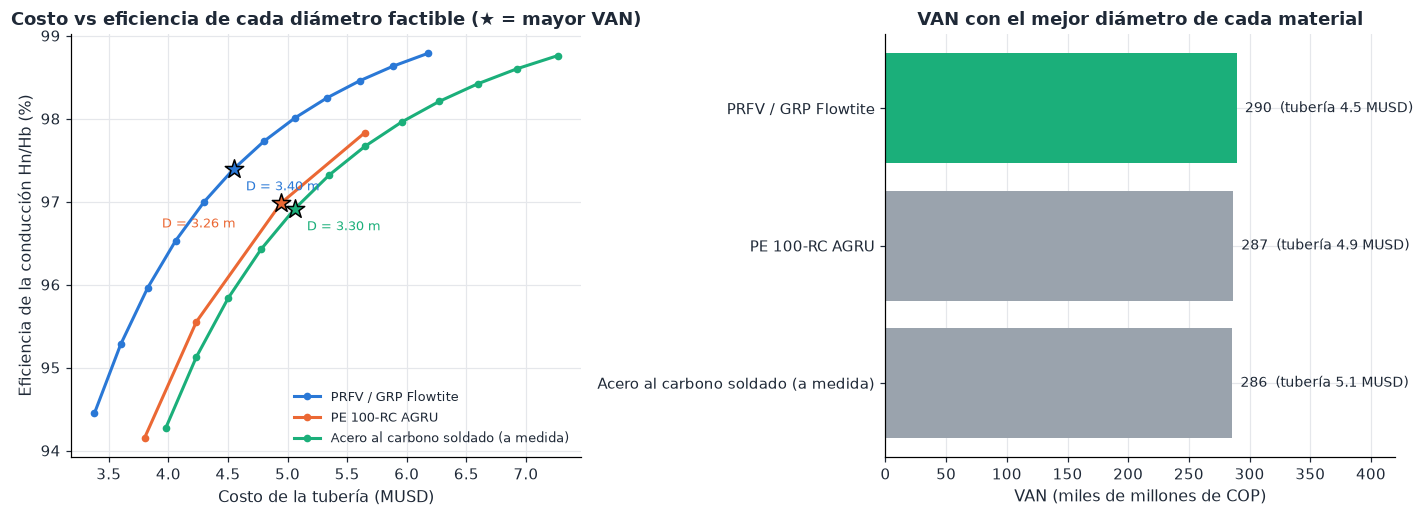

MATERIAL SUGERIDO: PRFV / GRP Flowtite, D = 3.40 m
  eficiencia de la conducción 97.39 %, costo de la tubería 4.55 MUSD, VAN 289.5 mil M COP, TIR 27.7 %
  frente a PE 100-RC AGRU: VAN +3.0 mil M COP, costo de tubería -0.40 MUSD, eficiencia +0.41 puntos
  Hierro dúctil NATURAL: no factible, diámetro máximo 2.00 m → V = 8.9 m/s > 5 m/s
  PVC-O TOM: no factible, diámetro máximo 1.20 m → V = 24.8 m/s > 5 m/s
  Para adoptarlo en todo el cuaderno cambie material_id = "GRP_FLOWTITE" en la celda de parámetros.


In [70]:
# ============================================================
# GRÁFICA 19 - COMPARATIVO DE MATERIALES: COSTO VS EFICIENCIA Y VAN
# ============================================================

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))               # Dos paneles.
for k, (m, ev) in enumerate(curvas_mat.items()):              # Una curva por material factible.
    c = PALETA[k % len(PALETA)]                               # Color del material.
    ax[0].plot(ev["Costo tubería [MUSD]"], ev["η_cond [%]"], "o-", color=c, lw=2, ms=4, label=nombre_mat[m])  # Curva costo-eficiencia.
    b_ = ev.loc[ev.VAN_MCOP.idxmax()]                         # Diámetro de mayor VAN.
    ax[0].scatter(b_["Costo tubería [MUSD]"], b_["η_cond [%]"], s=160, marker="*", color=c, edgecolor="k", zorder=6)  # Mejor diámetro.
    ax[0].annotate(f"D = {b_.D:.2f} m", (b_["Costo tubería [MUSD]"], b_["η_cond [%]"]), textcoords="offset points",
                   xytext=[(8, -14), (-78, -16), (8, -14)][k % 3], fontsize=8.5, color=c)  # Rótulo del diámetro.
ax[0].set(xlabel="Costo de la tubería (MUSD)", ylabel="Eficiencia de la conducción Hn/Hb (%)",
          title="Costo vs eficiencia de cada diámetro factible (★ = mayor VAN)")  # Rótulos.
ax[0].legend(fontsize=8.5, loc="lower right")                 # Leyenda.
fx = comp_mat[comp_mat.Factible == "✔"].iloc[::-1]            # Materiales factibles, el mejor arriba.
colores = [PALETA[2] if m == mat_sug.Material_ID else GRIS for m in fx.Material_ID]  # El sugerido resaltado.
ax[1].barh(fx.Material, fx["VAN [mil M COP]"], color=colores) # VAN del mejor diámetro de cada material.
ax[1].set_axisbelow(True)                                     # Cuadrícula detrás de las barras.
for y, (v, c_) in enumerate(zip(fx["VAN [mil M COP]"], fx["Costo tubería [MUSD]"])):  # Rótulos de cada barra.
    ax[1].text(v, y, f"  {v:,.0f}  (tubería {c_:.1f} MUSD)", va="center", fontsize=9)  # VAN y costo.
ax[1].set_xlim(0, fx["VAN [mil M COP]"].max() * 1.45)         # Espacio para los rótulos.
ax[1].set(xlabel="VAN (miles de millones de COP)", title="VAN con el mejor diámetro de cada material")  # Rótulos.
fig.tight_layout()                                            # Ajusta márgenes.
plt.show()                                                    # Dibuja.

no_fact = comp_mat[comp_mat.Factible == "✘"]                  # Materiales descartados.
print(f"MATERIAL SUGERIDO: {mat_sug.Material}, D = {mat_sug['D [m]']:.2f} m")  # Sugerencia.
print(f"  eficiencia de la conducción {mat_sug['η_cond [%]']:.2f} %, costo de la tubería {mat_sug['Costo tubería [MUSD]']:.2f} MUSD, "
      f"VAN {mat_sug['VAN [mil M COP]']:,.1f} mil M COP, TIR {mat_sug['TIR [%]']:.1f} %")  # Sus cifras.
if seg is not None:                                           # Comparación con el segundo lugar.
    print(f"  frente a {seg.Material}: VAN {mat_sug['VAN [mil M COP]'] - seg['VAN [mil M COP]']:+,.1f} mil M COP, "
          f"costo de tubería {mat_sug['Costo tubería [MUSD]'] - seg['Costo tubería [MUSD]']:+.2f} MUSD, "
          f"eficiencia {mat_sug['η_cond [%]'] - seg['η_cond [%]']:+.2f} puntos")  # Diferencias.
for _, f in no_fact.iterrows():                               # Materiales que no sirven para este caudal.
    print(f"  {f.Material}: no factible, {f.Motivo}")         # Motivo del descarte.
if mat_sug.Material_ID != material_id:                        # El material de los parámetros no es el sugerido.
    print(f"  Para adoptarlo en todo el cuaderno cambie material_id = \"{mat_sug.Material_ID}\" en la celda de parámetros.")  # Cómo adoptarlo.

**Comparativo cualitativo de los materiales** (fichas de los fabricantes de la base de datos y ESHA 2004, cap. 5):

| Material | Ventajas | Limitaciones | Uso típico en PCH |
|---|---|---|---|
| **PRFV / GRP** (Flowtite) | liviano, no se corroe, rugosidad baja y estable en el tiempo, instalación rápida | sensible a impactos y a la calidad del apoyo; diámetros hasta 4 m | conducciones de media presión y gran diámetro |
| **PE 100-RC** (AGRU) | muy flexible, el más liso, celeridad baja (menor golpe de ariete), no se corroe | en diámetros grandes las paredes son muy gruesas (SDR) y el material es costoso; gran dilatación térmica | conducciones enterradas, terrenos inestables, presiones medias |
| **Acero soldado** | resiste las presiones más altas y cualquier diámetro (a medida) | pesado, requiere protección anticorrosiva y mantenimiento; celeridad alta (mayor golpe de ariete) | tuberías de alta presión y saltos grandes |
| **Fundición dúctil** (PAM) | robusta, juntas rápidas, larga vida | diámetro máximo de 2 m | caudales pequeños y medianos |
| **PVC** | el más barato y liso | diámetro máximo de 1,2 m, baja resistencia a la radiación UV | PCH pequeñas y microcentrales |

### 14.2 Comparativo de costos de las tuberías que cumplen frente a la seleccionada

Se toman **todas las tuberías que cumplen el diseño** (todos los materiales y diámetros factibles de la sección 14.1) y se comparan con la tubería seleccionada en la sección 6. Para cada opción $j$:

Diferencia de costo de la tubería (en pesos, con la TRM del día):

$$\Delta C_{tub,j}=\left(C_{tub,j}-C_{tub,sel}\right)\cdot TRM$$

Diferencia porcentual:

$$\Delta C_{tub,j}\,[\%]=\frac{C_{tub,j}-C_{tub,sel}}{C_{tub,sel}}\cdot 100$$

Diferencia de VAN, que suma el efecto del costo y de la energía que gana o pierde la opción:

$$\Delta VAN_j = VAN_j - VAN_{sel}$$

Un $\Delta C_{tub} < 0$ indica una tubería más barata que la seleccionada; un $\Delta VAN > 0$, un proyecto más rentable aunque la tubería cueste más.

In [71]:
# ============================================================
# COMPARATIVO DE COSTOS DE TODAS LAS TUBERÍAS QUE CUMPLEN FRENTE A LA SELECCIONADA
# ============================================================

todas = pd.concat([ev.assign(Material=nombre_mat[m]) for m, ev in curvas_mat.items()], ignore_index=True)  # Todas las opciones.
es_sel = (todas.material == material_id) & np.isclose(todas.D, D_sel)  # Fila de la tubería seleccionada.
if not es_sel.any():                                          # Si no está en la malla (p. ej. otro número de unidades), se evalúa aparte.
    r_ = evaluar_config(Q_diseno, D_sel, eps_sel, material_id, n_unid, turbina)  # Evaluación completa.
    r_.update({"Costo tubería [MUSD]": costo_tuberia_usd(D_sel, material_id) / 1e6, "η_cond [%]": (1 - r_["perdida"]) * 100,
               "Material": nombre_mat.get(material_id, material_id)})  # Columnas del comparativo.
    todas = pd.concat([todas, pd.DataFrame([r_])], ignore_index=True)  # Se agrega.
    es_sel = (todas.material == material_id) & np.isclose(todas.D, D_sel)  # Se vuelve a marcar.
ref = todas[es_sel].iloc[0]                                   # Tubería seleccionada.
cmp_tub = pd.DataFrame({                                      # Tabla comparativa en pesos con la TRM del día.
    "Material": todas.Material, "D [m]": todas.D, "V [m/s]": todas.V, "η_cond [%]": todas["η_cond [%]"],
    "Costo tubería [M COP]": todas["Costo tubería [MUSD]"] * TRM,
    "Δ costo tubería [M COP]": (todas["Costo tubería [MUSD]"] - ref["Costo tubería [MUSD]"]) * TRM,
    "Δ costo tubería [%]": (todas["Costo tubería [MUSD]"] / ref["Costo tubería [MUSD]"] - 1) * 100,
    "CAPEX [M COP]": todas.CAPEX_MUSD * TRM, "Δ CAPEX [M COP]": (todas.CAPEX_MUSD - ref.CAPEX_MUSD) * TRM,
    "VAN [mil M COP]": todas.VAN_MCOP / 1e3, "Δ VAN [mil M COP]": (todas.VAN_MCOP - ref.VAN_MCOP) / 1e3,
    "TIR [%]": todas.TIR * 100})
cmp_tub["Nota"] = ""                                          # Marcas de la tabla.
cmp_tub.loc[es_sel.values, "Nota"] += "◀ seleccionada "       # Tubería del diseño.
i_barata = cmp_tub["Costo tubería [M COP]"].idxmin()          # Tubería más barata que cumple.
i_van = cmp_tub["VAN [mil M COP]"].idxmax()                   # Tubería con mayor VAN.
cmp_tub.loc[i_barata, "Nota"] += "▼ más barata "              # Marca.
cmp_tub.loc[i_van, "Nota"] += "★ mayor VAN"                   # Marca.
cmp_tub = cmp_tub.sort_values("Costo tubería [M COP]").reset_index(drop=True)  # De la más barata a la más cara.
cmp_tub.index = cmp_tub.index + 1                             # Posición por costo.
print(f"TRM usada: {TRM:,.2f} COP/USD ({fuente_trm})")        # Tasa de cambio del cálculo.
print(f"{len(cmp_tub)} tuberías cumplen el diseño; seleccionada: {ref.Material} D = {ref.D:.2f} m, "
      f"tubería de {ref['Costo tubería [MUSD]'] * TRM:,.0f} millones de COP")  # Resumen.
cmp_tub.round(2)                                              # Tabla comparativa.

TRM usada: 3,297.07 COP/USD (datos.gov.co (Superfinanciera), vigente del 2026-11-11 al 2026-11-12)
28 tuberías cumplen el diseño; seleccionada: PE 100-RC AGRU D = 2.83 m, tubería de 12,530 millones de COP


,Material,D [m],V [m/s],η_cond [%],Costo tubería [M COP],Δ costo tubería [M COP],Δ costo tubería [%],CAPEX [M COP],Δ CAPEX [M COP],VAN [mil M COP],Δ VAN [mil M COP],TIR [%],Nota
1,PRFV / GRP Flowtite,2.900,4.240,94.450,"11,144.660","-1,385.800",-11.060,"171,040.840",-881.580,285.920,2.750,28.320,▼ más barata
2,PRFV / GRP Flowtite,3.000,3.960,95.280,"11,869.340",-661.120,-5.280,"173,168.290","1,245.870",287.410,4.240,28.200,
3,PE 100-RC AGRU,2.830,4.450,94.150,"12,530.460",0.000,0.000,"171,922.420",0.000,283.170,0.000,28.060,◀ seleccionada
4,PRFV / GRP Flowtite,3.100,3.710,95.960,"12,616.720",86.260,0.690,"175,070.570","3,148.150",288.440,5.260,28.070,
5,Acero al carbono soldado (a medida),2.900,4.240,94.270,"13,111.370",580.910,4.640,"172,696.450",774.030,282.760,-0.420,27.960,
6,PRFV / GRP Flowtite,3.200,3.480,96.530,"13,386.780",856.320,6.830,"176,797.770","4,875.350",289.080,5.910,27.940,
7,Acero al carbono soldado (a medida),3.000,3.960,95.130,"13,963.930","1,433.470",11.440,"175,007.760","3,085.330",284.170,1.000,27.820,
8,PE 100-RC AGRU,3.000,3.960,95.550,"13,963.930","1,433.470",11.440,"175,724.140","3,801.710",285.410,2.240,27.820,
9,PRFV / GRP Flowtite,3.300,3.270,97.000,"14,179.550","1,649.090",13.160,"178,388.680","6,466.250",289.420,6.250,27.800,
10,Acero al carbono soldado (a medida),3.100,3.710,95.840,"14,843.200","2,312.730",18.460,"177,086.620","5,164.200",285.100,1.920,27.670,


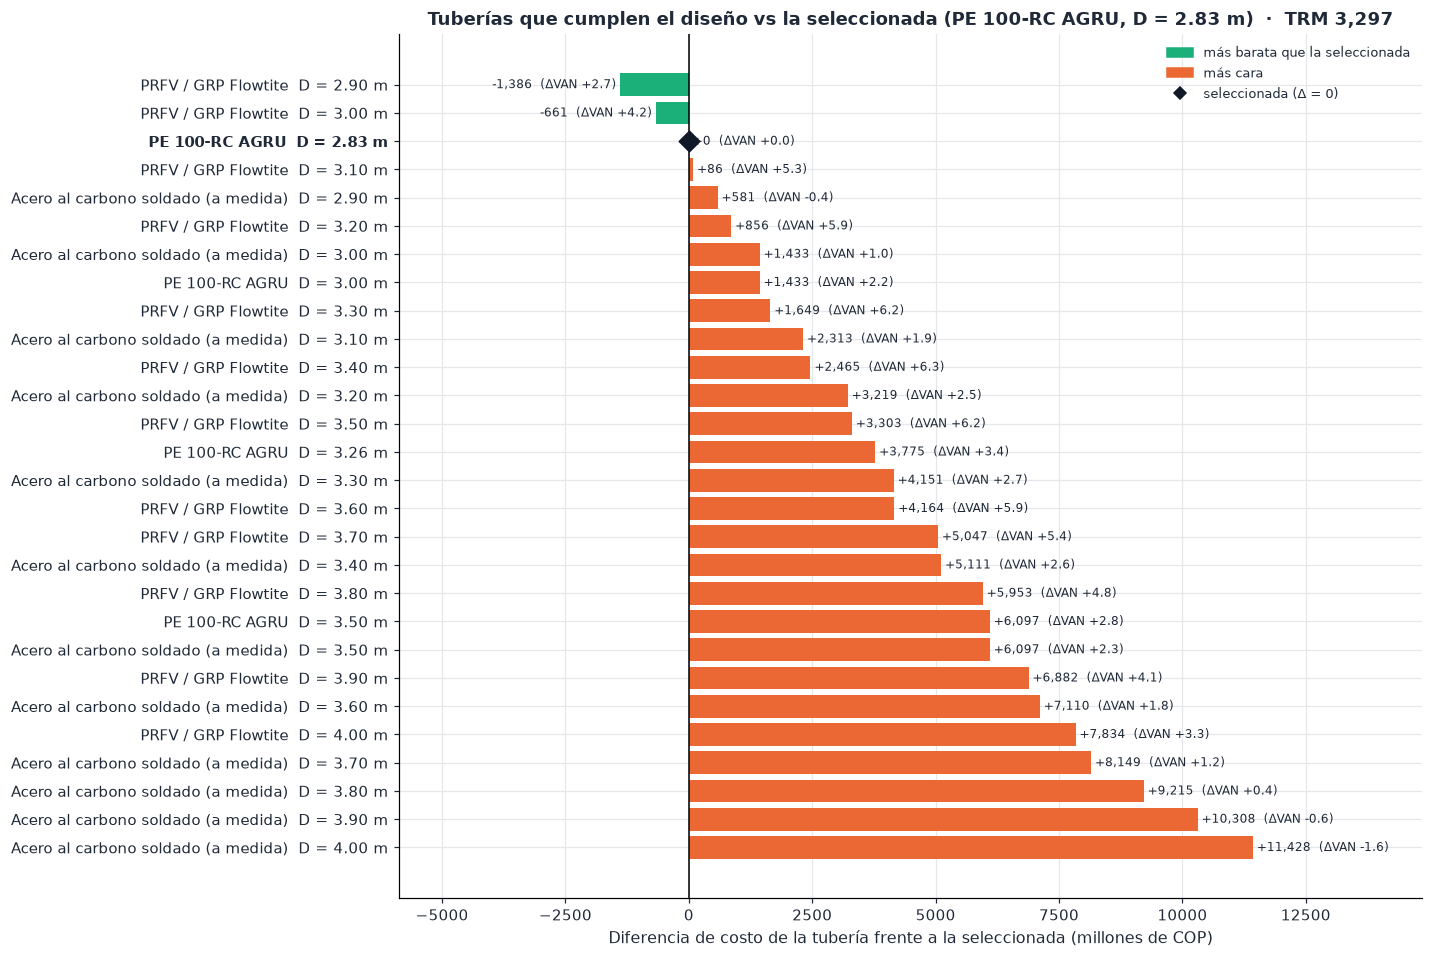

Seleccionada: PE 100-RC AGRU D = 2.83 m → tubería 12,530 M COP, VAN 283.2 mil M COP
Más barata que cumple: PRFV / GRP Flowtite D = 2.90 m → -1,386 M COP (-11.1 %), ΔVAN +2.7 mil M COP
Mayor VAN: PRFV / GRP Flowtite D = 3.40 m → +2,465 M COP en tubería, ΔVAN +6.3 mil M COP


In [72]:
# ============================================================
# GRÁFICA 20 - DIFERENCIA DE COSTO DE CADA TUBERÍA QUE CUMPLE FRENTE A LA SELECCIONADA
# ============================================================

d_ = cmp_tub.iloc[::-1]                                       # La más barata arriba.
etq = [f"{m}  D = {d:.2f} m" for m, d in zip(d_.Material, d_["D [m]"])]  # Rótulo de cada opción.
col = [PALETA[2] if v < 0 else PALETA[1] for v in d_["Δ costo tubería [M COP]"]]  # Verde: más barata; naranja: más cara.
fig, ax = plt.subplots(figsize=(12, 0.3 * len(d_) + 1.8))     # Alto según el número de opciones.
ax.barh(etq, d_["Δ costo tubería [M COP]"], color=col)        # Diferencia de costo frente a la seleccionada.
ax.set_axisbelow(True)                                        # Cuadrícula detrás de las barras.
ax.axvline(0, color="k", lw=1)                                # Referencia: la tubería seleccionada.
y_sel = int(np.flatnonzero(d_.Nota.str.contains("seleccionada").values)[0])  # Posición de la seleccionada.
ax.scatter(0, y_sel, s=90, marker="D", color="#111827", zorder=5)  # Marca de la seleccionada.
ax.get_yticklabels()[y_sel].set_fontweight("bold")            # Rótulo de la seleccionada en negrita.
for y, (v, van) in enumerate(zip(d_["Δ costo tubería [M COP]"], d_["Δ VAN [mil M COP]"])):  # Rótulos.
    ax.text(v, y, f" {v:+,.0f}  (ΔVAN {van:+.1f})  " if v >= 0 else f"  {v:+,.0f}  (ΔVAN {van:+.1f}) ",
            va="center", ha="left" if v >= 0 else "right", fontsize=8)  # Δ costo y Δ VAN.
v_min, v_max = d_["Δ costo tubería [M COP]"].min(), d_["Δ costo tubería [M COP]"].max()  # Rango de diferencias.
ax.set_xlim(min(v_min, 0) - 0.35 * (v_max - min(v_min, 0)), max(v_max, 0) * 1.3)  # Espacio para los rótulos.
ax.set(xlabel="Diferencia de costo de la tubería frente a la seleccionada (millones de COP)",
       title=f"Tuberías que cumplen el diseño vs la seleccionada ({ref.Material}, D = {ref.D:.2f} m)  ·  TRM {TRM:,.0f}")  # Rótulos.
ax.legend(handles=[Patch(color=PALETA[2], label="más barata que la seleccionada"), Patch(color=PALETA[1], label="más cara"),
                   plt.Line2D([], [], marker="D", ls="", color="#111827", label="seleccionada (Δ = 0)")], loc="upper right", fontsize=8.5)  # Leyenda.
plt.show()                                                    # Dibuja.

barata, mejor = cmp_tub[cmp_tub.Nota.str.contains("barata")].iloc[0], cmp_tub[cmp_tub.Nota.str.contains("mayor VAN")].iloc[0]  # Destacadas.
print(f"Seleccionada: {ref.Material} D = {ref.D:.2f} m → tubería {ref['Costo tubería [MUSD]'] * TRM:,.0f} M COP, VAN {ref.VAN_MCOP / 1e3:,.1f} mil M COP")
print(f"Más barata que cumple: {barata.Material} D = {barata['D [m]']:.2f} m → {barata['Δ costo tubería [M COP]']:+,.0f} M COP "
      f"({barata['Δ costo tubería [%]']:+.1f} %), ΔVAN {barata['Δ VAN [mil M COP]']:+.1f} mil M COP")
print(f"Mayor VAN: {mejor.Material} D = {mejor['D [m]']:.2f} m → {mejor['Δ costo tubería [M COP]']:+,.0f} M COP en tubería, "
      f"ΔVAN {mejor['Δ VAN [mil M COP]']:+.1f} mil M COP")

---
# 15. Beneficio ambiental

La energía de la PCH desplaza generación térmica del Sistema Interconectado Nacional.

Emisiones evitadas por año:

$$CO_{2,\ evitado}=E_{neta}\ [\text{MWh}]\times FE\ [\text{t CO}_2\text{e/MWh}]$$

Factores de la **UPME, Factores de emisión del SIN 2024** (margen combinado, metodología CDM): 0,607 para proyectos nuevos en el primer periodo crediticio (adoptado), 0,554 en el segundo y tercero, y 0,220 como factor de inventario (cota inferior conservadora).

In [73]:
# ============================================================
# EMISIONES EVITADAS Y CAUDAL ECOLÓGICO
# ============================================================

FE = {"Margen combinado, 1.er periodo (adoptado)": 0.607, "Margen combinado, 2.º y 3.er periodo": 0.554,
      "Factor de inventario (cota inferior)": 0.220}          # t CO2e/MWh, UPME 2024.
co2 = pd.DataFrame([{"Factor UPME 2024": k, "t CO2e/MWh": f, "t CO2e/año": E_media / 1000 * f,
                     f"t CO2e en {vida_util} años": E_media / 1000 * f * vida_util} for k, f in FE.items()])  # Tabla.
display(co2.set_index("Factor UPME 2024").round(3))           # Muestra la tabla de emisiones.
eco = pd.Series({"Caudal ecológico": f"{Q_eco} m³/s", "Días con remanente ≥ ecológico": f"{(remanente >= Q_eco - 1e-9).mean():.1%}",
                 "Caudal remanente mínimo": f"{remanente.min():.1f} m³/s",
                 "Fracción del caudal medio derivada": f"{sim.Q_turb.mean() / sim.Q_rio.mean():.1%}"})  # Cumplimiento ambiental.
eco.to_frame("Caudal ecológico")                              # Muestra.

,t CO2e/MWh,t CO2e/año,t CO2e en 30 años
Factor UPME 2024,,,
"Margen combinado, 1.er periodo (adoptado)",0.607,"86,579.370","2,597,381.108"
"Margen combinado, 2.º y 3.er periodo",0.554,"79,019.722","2,370,591.654"
Factor de inventario (cota inferior),0.220,"31,379.673","941,390.187"


,Caudal ecológico
Caudal ecológico,4.0 m³/s
Días con remanente ≥ ecológico,100.0%
Caudal remanente mínimo,4.0 m³/s
Fracción del caudal medio derivada,57.9%


---
# 16. Resumen de resultados

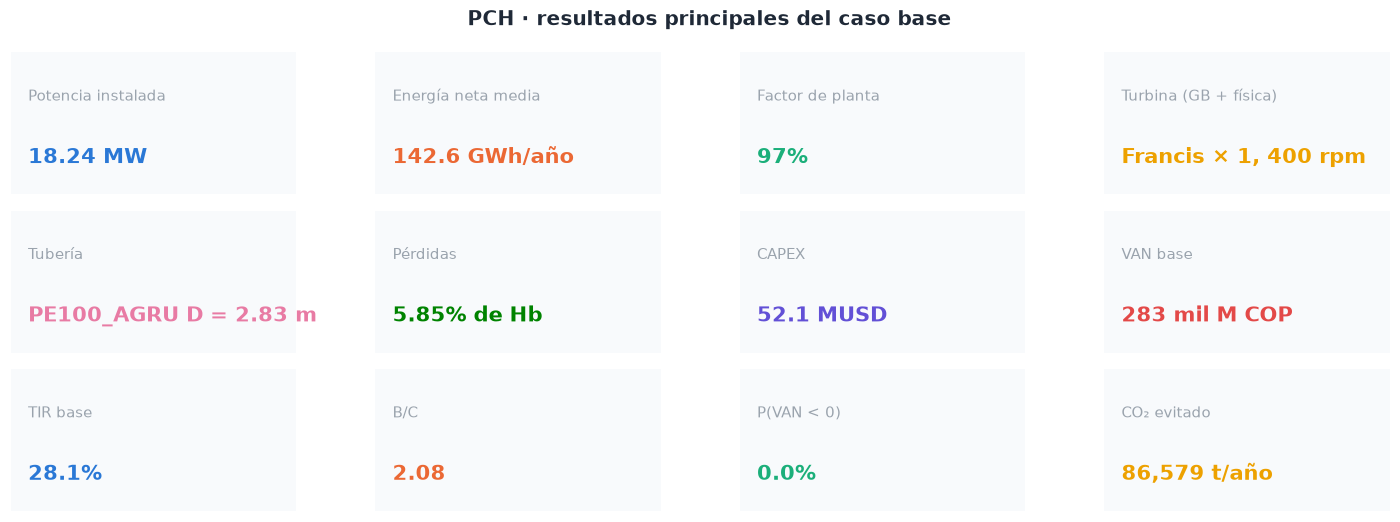

In [74]:
# ============================================================
# INDICADORES CLAVE DEL CASO BASE
# ============================================================

kpi = [("Potencia instalada", f"{P_inst:.2f} MW"), ("Energía neta media", f"{E_media / 1e6:,.1f} GWh/año"),
       ("Factor de planta", f"{FP:.0%}"), ("Turbina (GB + física)", f"{turbina} × {n_unid}, {n_rpm:.0f} rpm"),
       ("Tubería", f"{material_id} D = {D_sel:.2f} m"), ("Pérdidas", f"{hd['perdida']:.2%} de Hb"),
       ("CAPEX", f"{cx['total'] / 1e6:,.1f} MUSD"), ("VAN base", f"{ind_base['VAN [MCOP]'] / 1e3:,.0f} mil M COP"),
       ("TIR base", f"{ind_base['TIR']:.1%}"), ("B/C", f"{ind_base['B/C']:.2f}"),
       ("P(VAN < 0)", f"{p_perdida:.1%}"), ("CO₂ evitado", f"{co2.iloc[0, 2]:,.0f} t/año")]  # Doce indicadores.
fig, axs = plt.subplots(3, 4, figsize=(13, 4.8))              # Mosaico de tarjetas.
for a, (t, v_), c in zip(axs.ravel(), kpi, PALETA * 2):       # Una tarjeta por indicador.
    a.set_facecolor("#f8fafc")                                # Fondo suave.
    a.text(0.06, 0.66, t, fontsize=9.5, color=GRIS, transform=a.transAxes)  # Nombre del indicador.
    a.text(0.06, 0.22, v_, fontsize=13.5, fontweight="bold", color=c, transform=a.transAxes)  # Valor.
    a.set_xticks([]); a.set_yticks([]); a.grid(False)         # Sin ejes.
    for sp in a.spines.values(): sp.set_visible(False)        # Sin bordes.
fig.suptitle("PCH · resultados principales del caso base", fontweight="bold", fontsize=13)  # Título.
fig.tight_layout()                                            # Ajusta márgenes.
plt.show()                                                    # Dibuja.

In [75]:
# ============================================================
# VERIFICACIÓN DE LOS CRITERIOS DE DISEÑO Y DE RENTABILIDAD
# ============================================================

acc_gb = metricas_turb.set_index("Modelo").loc["Gradient Boosting (ajustado)", "Exactitud"]  # Exactitud del GB de turbinas.
brecha_ml = float(comp.set_index("Método").loc["ML preselecciona + física decide", "Brecha vs óptimo [%]"])  # Brecha del método híbrido.
verif_final = pd.DataFrame([                                  # Criterio, valor obtenido, ¿cumple?
    ("Velocidad en la tubería ≤ 5 m/s", f"{V_sel:.2f} m/s", V_sel <= V_max),
    ("Pérdidas hidráulicas ≤ 6 % de Hb", f"{hd['perdida']:.2%}", hd["perdida"] <= perdida_max),
    ("Sobrepresión ≤ 30 % de Hb con el cierre especificado", f"cierre ≥ {T_min:.0f} s", True),
    ("Turbina del GB factible en física y catálogo", f"{turbina} × {n_unid}, {n_rpm:.0f} rpm, Hs = {Hs:.1f} m", turbina is not None and Hs >= HS_MIN),
    ("Caudal ecológico respetado todos los días", f"{(remanente >= Q_eco - 1e-9).mean():.1%}", bool((remanente >= Q_eco - 1e-9).all())),
    ("Potencia menor de 20 MW (planta menor)", f"{P_inst:.2f} MW", P_inst < 20),
    ("VAN > 0", f"{ind_base['VAN [MCOP]'] / 1e3:,.0f} mil millones COP", ind_base["VAN [MCOP]"] > 0),
    ("TIR > i", f"{ind_base['TIR']:.1%} > {i_desc:.0%}", ind_base["TIR"] > i_desc),
    ("B/C > 1", f"{ind_base['B/C']:.2f}", ind_base["B/C"] > 1),
], columns=["Criterio", "Resultado", "Cumple"])
verif_final["Cumple"] = verif_final["Cumple"].map({True: "✔", False: "✘"})  # Símbolos legibles.
verif_final.set_index("Criterio")                             # Muestra la tabla.

,Resultado,Cumple
Criterio,,
Velocidad en la tubería ≤ 5 m/s,4.45 m/s,✔
Pérdidas hidráulicas ≤ 6 % de Hb,5.85%,✔
Sobrepresión ≤ 30 % de Hb con el cierre especificado,cierre ≥ 45 s,✔
Turbina del GB factible en física y catálogo,"Francis × 1, 400 rpm, Hs = -4.5 m",✔
Caudal ecológico respetado todos los días,100.0%,✔
Potencia menor de 20 MW (planta menor),18.24 MW,✔
VAN > 0,283 mil millones COP,✔
TIR > i,28.1% > 10%,✔
B/C > 1,2.08,✔


### 16.1 Exportación de resultados

Los resultados de esta ejecución se guardan en la carpeta `resultados/` en tres formatos: `resumen.json` (indicadores clave, para el README de GitHub y el dashboard), una tabla CSV por resultado en `resultados/tablas/` y la base de datos SQL `pch_resultados.sqlite` con las mismas tablas.

In [76]:
# ============================================================
# EXPORTACIÓN DE RESULTADOS: JSON, CSV Y BASE SQL DE RESULTADOS
# ============================================================

(SALIDAS / "tablas").mkdir(parents=True, exist_ok=True)       # Carpeta de tablas.
resumen = {                                                   # Indicadores clave de esta ejecución.
    "fecha_calculo": str(fecha_calculo), "TRM_COP_USD": TRM, "fuente_TRM": fuente_trm,
    "parametros": {"Q_diseno_m3s": Q_diseno, "Q_eco_m3s": Q_eco, "H_bruto_m": H_bruto, "L_m": L,
                   "material": material_id, "D_m": D_sel, "seleccion_tuberia": modo_sel, "accesorios": accesorios_tramo,
                   "i_desc": i_desc, "vida_util_anios": vida_util, "frac_contrato": frac_contrato},
    "hidraulica": {"K_total": K_total, "V_m_s": V_sel, "hf_m": hd["hf"], "hm_m": hd["hm"], "hL_m": hd["hL"],
                   "perdida_pct": hd["perdida"] * 100, "H_neto_m": H_neto},
    "golpe_ariete": {"T_cierre_min_s": T_min, "sobrepresion_cierre_m": dh_T},
    "turbina": {"tipo": turbina, "unidades": n_unid, "rpm": n_rpm, "D3_m": D3, "Hs_m": Hs},
    "energia": {"P_MW": P_inst, "E_GWh_anio": E_media / 1e6, "factor_planta": FP},
    "economia": {"CAPEX_MUSD": cx["total"] / 1e6, "CAPEX_MCOP": CAPEX / 1e6, **ind_base, "P_VAN_negativo": p_perdida},
    "ambiente": {"CO2_t_anio": co2.iloc[0, 2]},
    "tuberias": {"opciones_que_cumplen": len(cmp_tub),
                 "mas_barata": f"{barata.Material} D = {barata['D [m]']:.2f} m",
                 "ahorro_mas_barata_MCOP": -barata["Δ costo tubería [M COP]"],
                 "mayor_VAN": f"{mejor.Material} D = {mejor['D [m]']:.2f} m",
                 "material_sugerido": f"{mat_sug.Material} D = {mat_sug['D [m]']:.2f} m"},
    "kpi": dict(kpi), "verificacion": verif_final.to_dict("records"),
}
a_json = lambda o: o.item() if hasattr(o, "item") else str(o) # Convierte números de NumPy a JSON.
(SALIDAS / "resumen.json").write_text(json.dumps(resumen, ensure_ascii=False, indent=2, default=a_json), encoding="utf-8")  # JSON.
tablas_exp = {"tabla_tuberias": tabla_tub, "opciones_tuberia": opciones_tub, "comparativo_costos_tuberias": cmp_tub,
              "comparativo_materiales": comp_mat, "inventario_accesorios": inventario.reset_index(),
              "perdidas_accesorios": desglose.reset_index(), "evaluacion_economica": ev, "escenarios": ind_esc,
              "optimizacion": comp, "verificacion": verif_final, "co2": co2}  # Tablas que se exportan.
with sqlite3.connect(SALIDAS / "pch_resultados.sqlite") as con:  # Base SQL de resultados.
    for nombre, t in tablas_exp.items():                      # Cada tabla en CSV y en SQL.
        t.to_csv(SALIDAS / "tablas" / f"{nombre}.csv", index=False)  # CSV.
        t.to_sql(nombre, con, if_exists="replace", index=False)  # Tabla SQL.
print(f"Resultados guardados en {SALIDAS.name}/: resumen.json, {len(tablas_exp)} tablas CSV y pch_resultados.sqlite")  # Aviso.

Resultados guardados en resultados/: resumen.json, 11 tablas CSV y pch_resultados.sqlite


---
## Interfaz interactiva (opcional)

Como en el Taller 1, esta celda crea controles para explorar otro caudal, material o salto sin editar el código. Requiere `ipywidgets` (`pip install ipywidgets`); si no está instalado, el cuaderno sigue funcionando y la celda muestra el cálculo con los parámetros por defecto.

In [77]:
# ============================================================
# INTERFAZ INTERACTIVA
# ============================================================

def explorar(Q=Q_diseno, material=material_id, Hb=H_bruto):   # Recalcula tubería, turbina y potencia para otro punto.
    sub = catalogo[catalogo.Material_ID == material].sort_values("Diametro_hidraulico_m")  # Diámetros del material.
    hh = hidraulica(Q, sub.Diametro_hidraulico_m.values, sub.epsilon_diseno_mm.values, K_total, H_b=Hb)  # Hidráulica de todos.
    ok = (hh["V"] <= V_max) & (hh["perdida"] <= perdida_max)  # Diámetros factibles.
    if not ok.any():                                          # Si ninguno cumple...
        print(f"{material}: ningún diámetro comercial cumple V ≤ {V_max} m/s y pérdidas ≤ {perdida_max:.0%} con Q = {Q} m³/s")
        return                                                # Termina sin resultado.
    j = int(np.argmax(ok))                                    # Menor diámetro factible.
    Hn_ = float(hh["Hn"][j])                                  # Salto neto.
    xp = pd.DataFrame({"log_Q": [np.log10(Q)], "log_H": [np.log10(Hn_)], "log_P": [np.log10(rho * g * Q * Hn_ / 1e6)]})  # Punto.
    pr = pd.Series(gb_turb.predict_proba(xp)[0], index=clases).sort_values(ascending=False)  # Probabilidades del GB.
    tipo = next((t for t in pr.index if any(factibilidad(t, Hn_, Q / k)["factible"] for k in (1, 2, 3))), None)  # Física decide.
    print(f"D = {sub.Diametro_hidraulico_m.values[j]:.2f} m | V = {hh['V'][j]:.2f} m/s | pérdidas = {hh['perdida'][j]:.2%} | "
          f"Hn = {Hn_:.1f} m | Pe ≈ {hh['Pe'][j]:.2f} MW | GB: {pr.index[0]} ({pr.iloc[0]:.0%}) → verificada: {tipo}")  # Resumen.

explorar()                                                    # Resultado estático con los parámetros por defecto.
try:                                                          # Controles interactivos si ipywidgets está disponible.
    import ipywidgets as widgets                              # Librería de controles.
    widgets.interact(explorar, Q=widgets.FloatSlider(value=Q_diseno, min=5, max=60, step=1, description="Q (m³/s)"),
                     material=widgets.Dropdown(options=sorted(catalogo.Material_ID.unique()), value=material_id, description="Material"),
                     Hb=widgets.FloatSlider(value=H_bruto, min=20, max=300, step=5, description="H bruto (m)"))  # Crea los controles.
except ImportError:                                           # Sin ipywidgets.
    print("Instale ipywidgets para usar los controles: pip install ipywidgets")  # Mensaje de ayuda.

D = 2.83 m | V = 4.45 m/s | pérdidas = 5.85% | Hn = 75.3 m | Pe ≈ 18.24 MW | GB: Francis (100%) → verificada: Francis


interactive(children=(FloatSlider(value=28.0, description='Q (m³/s)', max=60.0, min=5.0, step=1.0), Dropdown(d…

---
# 17. Conclusiones

In [78]:
# ============================================================
# CONCLUSIONES CON LOS NÚMEROS DE ESTA EJECUCIÓN
# ============================================================

fila_opt = comp.set_index("Método").loc["Exhaustivo (física + finanzas)"]  # Óptimo.
fila_trad = comp.set_index("Método").loc["Tradicional (Q30 + Fahlbusch)"]  # Tradicional.
display(Markdown(f'''
1. **Conducción.** La tubería de {material_id} de {D_sel:.2f} m (selección {modo_sel}) cumple los criterios de diseño: V = {V_sel:.2f} m/s y
   pérdidas de {hd['hL']:.2f} m ({hd['perdida']:.2%} del salto), con un K de accesorios desglosado de {K_total:.3f} en lugar del 1,85 supuesto en la Entrega 2.
2. **Golpe de ariete.** Un cierre de {T_cierre:.0f} s produciría {dh_T:.0f} m de sobrepresión; se especifica un cierre de al menos {T_min:.0f} s, que
   limita la presión máxima a 1,3 Hb, la presión con la que se escogió la clase de la tubería.
3. **Turbina.** El *Gradient Boosting* (exactitud {acc_gb:.1%} y F1 macro {metricas_turb.set_index("Modelo").loc["Gradient Boosting (ajustado)", "F1 macro"]:.3f} en prueba,
   frente a {metricas_turb.set_index("Modelo").loc["Tradicional: carta por salto", "Exactitud"]:.1%} de la carta por salto) propone **{turbina}** con
   {prob_pch.iloc[0]:.1%} de probabilidad; la física lo confirma con {n_unid} unidad a {n_rpm:.0f} rpm ({fz['polos']} polos), n_QE = {nq:.3f},
   D3 = {D3:.2f} m y Hs = {Hs:.1f} m, dentro de la envolvente WEG Francis.
4. **Energía.** {P_inst:.2f} MW instalados producen {E_media / 1e6:,.1f} GWh/año netos (año seco: {ea.min():,.0f} GWh) con un factor de planta de {FP:.0%};
   el caudal ecológico se respeta el 100 % de los días.
5. **Economía (clase 14).** CAPEX de {cx['total'] / 1e6:,.1f} MUSD ({cx['total'] / P_kW:,.0f} USD/kW). En el escenario base el VAN es de
   {ind_base['VAN [MCOP]'] / 1e3:,.0f} mil millones de COP, la TIR de {ind_base['TIR']:.1%}, B/C = {ind_base['B/C']:.2f} y la inversión se recupera en
   {ind_base['PB estático [años]']:.1f} años (estático) o {ind_base['PB dinámico [años]']:.1f} años (descontado). El LCOE de {ind_base['LCOE [COP/kWh]']:,.0f} COP/kWh
   está muy por debajo del precio de contratos. La probabilidad de VAN negativo en Monte Carlo es {p_perdida:.1%}; el escenario conservador
   ({ind_esc.set_index("Escenario").loc["3. Conservador", "VAN [MCOP]"] / 1e3:,.0f} mil millones) muestra que el riesgo está en vender todo en bolsa en un año seco con precio bajo.
6. **Optimización.** El método tradicional (Q30 = {fila_trad.Q_d:.1f} m³/s) da una central de {fila_trad.P_MW:.1f} MW que supera el límite de una planta menor.
   El óptimo con límite de 20 MW es Qd = {fila_opt.Q_d:.0f} m³/s, {fila_opt.material} D = {fila_opt.D:.2f} m, {fila_opt.P_MW:.2f} MW; el método ML + física lo alcanza
   con una brecha de {brecha_ml:.2f} % usando {len(idx_m) + 10} de {len(fact)} evaluaciones completas.
7. **Costo de la tubería.** De las {len(cmp_tub)} tuberías que cumplen el diseño, la más barata es {barata.Material} D = {barata['D [m]']:.2f} m
   ({barata['Δ costo tubería [M COP]']:+,.0f} millones de COP frente a la seleccionada) y la de mayor VAN es {mejor.Material} D = {mejor['D [m]']:.2f} m
   ({mejor['Δ VAN [mil M COP]']:+.1f} mil millones de COP de VAN), con la TRM de {TRM:,.2f} COP/USD del {fecha_calculo:%Y-%m-%d}.
8. **Material de la tubería.** Al caudal de diseño, el comparativo de materiales sugiere **{mat_sug.Material}** (D = {mat_sug['D [m]']:.2f} m):
   eficiencia de la conducción de {mat_sug['η_cond [%]']:.2f} %, tubería de {mat_sug['Costo tubería [MUSD]']:.1f} MUSD y el mayor VAN entre los materiales factibles
   ({mat_sug['VAN [mil M COP]']:,.0f} mil millones de COP).
9. **Ambiente.** Se evitan {co2.iloc[0, 2]:,.0f} t CO₂e por año (factor UPME 2024 de 0,607 t/MWh), {co2.iloc[0, 3] / 1e6:,.2f} millones de toneladas en la vida útil.
'''))  # Conclusiones numeradas.


1. **Conducción.** La tubería de PE100_AGRU de 2.83 m (selección automática: menor diámetro que cumple) cumple los criterios de diseño: V = 4.45 m/s y
   pérdidas de 4.68 m (5.85% del salto), con un K de accesorios desglosado de 1.154 en lugar del 1,85 supuesto en la Entrega 2.
2. **Golpe de ariete.** Un cierre de 10 s produciría 109 m de sobrepresión; se especifica un cierre de al menos 45 s, que
   limita la presión máxima a 1,3 Hb, la presión con la que se escogió la clase de la tubería.
3. **Turbina.** El *Gradient Boosting* (exactitud 98.7% y F1 macro 0.988 en prueba,
   frente a 58.9% de la carta por salto) propone **Francis** con
   99.9% de probabilidad; la física lo confirma con 1 unidad a 400 rpm (18 polos), n_QE = 0.249,
   D3 = 1.70 m y Hs = -4.5 m, dentro de la envolvente WEG Francis.
4. **Energía.** 18.24 MW instalados producen 142.6 GWh/año netos (año seco: 114 GWh) con un factor de planta de 97%;
   el caudal ecológico se respeta el 100 % de los días.
5. **Economía (clase 14).** CAPEX de 52.1 MUSD (2,859 USD/kW). En el escenario base el VAN es de
   283 mil millones de COP, la TIR de 28.1%, B/C = 2.08 y la inversión se recupera en
   3.6 años (estático) o 4.6 años (descontado). El LCOE de 193 COP/kWh
   está muy por debajo del precio de contratos. La probabilidad de VAN negativo en Monte Carlo es 0.0%; el escenario conservador
   (-50 mil millones) muestra que el riesgo está en vender todo en bolsa en un año seco con precio bajo.
6. **Optimización.** El método tradicional (Q30 = 48.4 m³/s) da una central de 30.6 MW que supera el límite de una planta menor.
   El óptimo con límite de 20 MW es Qd = 30 m³/s, GRP_FLOWTITE D = 3.20 m, 19.93 MW; el método ML + física lo alcanza
   con una brecha de 0.00 % usando 100 de 453 evaluaciones completas.
7. **Costo de la tubería.** De las 28 tuberías que cumplen el diseño, la más barata es PRFV / GRP Flowtite D = 2.90 m
   (-1,386 millones de COP frente a la seleccionada) y la de mayor VAN es PRFV / GRP Flowtite D = 3.40 m
   (+6.3 mil millones de COP de VAN), con la TRM de 3,297.07 COP/USD del 2026-11-11.
8. **Material de la tubería.** Al caudal de diseño, el comparativo de materiales sugiere **PRFV / GRP Flowtite** (D = 3.40 m):
   eficiencia de la conducción de 97.39 %, tubería de 4.5 MUSD y el mayor VAN entre los materiales factibles
   (290 mil millones de COP).
9. **Ambiente.** Se evitan 86,579 t CO₂e por año (factor UPME 2024 de 0,607 t/MWh), 2.60 millones de toneladas en la vida útil.


### Limitaciones
- La serie de caudales no trae fechas; el calendario es un supuesto que solo afecta el cruce mes a mes con los precios.
- El CAPEX es de prefactibilidad (UPME USD/kW con distribución porcentual); la tubería es la única partida calculada desde la ingeniería.
- Las etiquetas del clasificador de turbinas vienen de reglas de ingeniería; el modelo replica ese criterio, no lo supera. Debe reentrenarse con datos reales de centrales cuando se disponga de ellos.
- La metodología de la clase 14 no incluye impuestos, deuda ni periodo de construcción en el flujo; la variante con impuesto de renta muestra el efecto del primero.
- Los precios de bolsa cubren 36 meses (2023–2026), que incluyen El Niño 2024; una serie más larga de la API de XM mejoraría el Monte Carlo.

### Recomendaciones
- **Comercial:** contratar al menos el 70 % de la energía firme a largo plazo; el riesgo de VAN negativo depende sobre todo del precio.
- **Técnica:** especificar una ley de cierre del regulador y la válvula de guarda no menor que el tiempo mínimo calculado y una válvula de alivio sincronizada.
- **Diseño:** reevaluar el caudal de diseño hacia el óptimo de la sección 14 manteniendo la potencia por debajo de 20 MW.
- **Ingeniería de detalle:** pedir a WEG la curva de colina del rodete Francis y confirmar la sumergencia con el nivel mínimo de descarga.
- **Tributaria:** evaluar los beneficios de la Ley 1715 de 2014 (deducción del 50 % de la inversión, exclusión de IVA y aranceles).

### Trabajo futuro
- Descargar la serie horaria completa de precios de la API de XM y entrenar un modelo de pronóstico de precios.
- Reentrenar el clasificador de turbinas con el inventario de PCH de la UPME y fichas reales de fabricantes.
- Extender la optimización a trazado de la conducción, número de unidades y tipo de turbina con el mismo esquema ML + física.
- Incorporar escenarios de cambio climático (reducción de caudales) en la simulación energética.

---
# 18. Referencias

- ESHA (2004). *Guide on How to Develop a Small Hydropower Plant*. European Small Hydropower Association.
- Idelchik, I. E. (2008). *Handbook of Hydraulic Resistance*, 4.ª ed. Begell House.
- Crane Co. (2013). *Flow of Fluids Through Valves, Fittings and Pipe*, Technical Paper No. 410.
- USBR (1977). *Welded Steel Penstocks*, Engineering Monograph No. 3.
- Swamee, P. K. y Jain, A. K. (1976). Explicit equations for pipe-flow problems. *Journal of the Hydraulics Division*, ASCE, 102(5).
- De Siervo, F. y De Leva, F. (1976–1978). Modern trends in selecting and designing Francis and Kaplan turbines. *Water Power & Dam Construction*.
- WEG/HISA (2019). *Hydraulic Turbines*, catálogo 50083924. · ANDRITZ (2014). *Bombas como turbinas ACT/FPT*. · Xylem Flygt. *Turbinas hidráulicas*, 2218.
- UPME (2025). *Plan Indicativo de Expansión de la Generación 2025–2039*. · UPME (2024). *Factores de emisión del SIN 2024*.
- XM S.A. E.S.P. Informes mensuales de variables del mercado (URL de cada informe en `precios_xm_mensual.csv`).
- CREG, Resolución 086 de 1996 (plantas menores). · Ley 99 de 1993, art. 45. · Ley 1715 de 2014.
- Clase 14, MLASH_M: *Evaluación preliminar de proyectos: estimación de recursos, costos CAPEX y OPEX*. Escuela Colombiana de Ingeniería.
- Friedman, J. H. (2001). Greedy function approximation: a gradient boosting machine. *Annals of Statistics*, 29(5).
- Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *JMLR*, 12.